# 9단계 한눈에 보기

이 노트북은 작업하며 주고받은 답변(✍️ 칸과 클로드의 답변)을 빼고, 코드 · 결과 · 물음마다의 결론(📌)만 남긴 판이다. 단계마다 한 일과 정한 것은 README 「전체 흐름」에 있다.

### 말 뜻 — 표를 읽을 때 쓰는 말 (10-28에 통일함)

| 말 | 뜻 |
|---|---|
| 실제 | 그해(주로 2026년)에 실제로 발전한 양 · 실제 값입니다. 전력거래소 자료 그대로입니다 |
| 모델 예측 | 2023 ~ 2025년을 배운 모델이 그때의 날씨 · 시각 · 날 종류를 보고 예측한 양입니다. 9단계까지는 「평소라면」이라고 불렀습니다 |
| 실제 − 모델 예측 | 발전량 표의 숫자입니다. + 면 실제가 모델 예측보다 많았다, − 면 적었다는 뜻입니다 |
| 평소 해 | 2023 · 2024 · 2025년입니다. 「평소」는 이 세 해만 가리킵니다 |
| 평소 범위 | 평소 해에 모델 예측이 한 달 평균으로 가장 크게 틀린 크기(±2,177 MWh)입니다. 모델이 예측해 본 2024 · 2025년으로 냈습니다. 2026년의 차이가 이 안이면 「달랐다고 말할 근거가 없다」로 읽습니다 |
| 세 해 평균 | 2023 ~ 2025년 같은 달 값의 평균입니다. 모델 없이 계산한 것으로, 10단계 가격 표(2-가 · 2-라)에서만 씁니다 |

앞 단계 글에서 발전량을 두고 쓴 「평소보다 많았다 · 적었다」는 「모델 예측보다 많았다 · 적었다」로 읽습니다.


# 09. 모델 적용 — 전체 11단계 중 9단계

**이 단계의 목적** — 「2026년은 평소와 얼마나 달랐나」에 숫자로 답하는 단계입니다. 평소 해의 패턴을 배운 모델이 맞힌 「평소라면 이만큼」과 2026년 실제 LNG 발전량을 비교하고, 그 차이를 선형회귀로 석탄 · 원전 · 수요 · 그 밖으로 나눈 표를 옆에 붙여, 무엇 때문에 달랐는지를 읽습니다(물음 1에서 정함).

**이 노트북을 연 흐름** — 10-17에 8단계를 닫으면서, 비교할 기간 · 「평소와 달랐다」의 기준 · 차이를 나눠 읽을지는 2026년 LNG를 보기 전에 9단계 첫 물음에서 정하기로 했습니다(8단계 닫는 칸 ②). 결과를 본 뒤에 정하면 결과에 맞춰 고르게 되기 때문입니다. 같은 날 창주 님이 「9단계 시작」이라고 하셔서 이 파일을 만들었습니다.

## 데이터와 모델

**데이터 흐름**

1. 2 · 3단계 — 시간마다 LNG · 기온 · 햇빛 같은 값을 받고, 빈 곳에 까닭을 붙여 고쳤습니다. 2026년 발전량은 API로 받았고, 5월 2 ~ 17일은 값이 깨져 있어 비교에서 빼기로 했습니다.
2. 4 · 5단계 — 무엇이 LNG를 움직이는지 보고, 모델이 쓸 열을 파일 하나(`data/hot/features_2023_2024_2025.csv`)로 저장했습니다.
3. 6단계 — 2026년은 7단계 채점이 끝난 뒤 같은 모델을 2023 ~ 2025년 세 해로 다시 배워 맞히기로 정했습니다.
4. 7단계 — 모델 넷을 2023 · 2024년으로 배워 2025년을 채점했습니다. 넷 다 기준선(같은 달 · 같은 시각 · 같은 날 종류의 평균)보다 잘 맞혔고, 평소 해에도 달마다 실제와 얼마나 어긋나는지(평소 틀리는 양)를 냈습니다.
5. 8단계 — 넷 가운데 그래디언트 부스팅을 골랐고, 모델에 넣은 다섯(몇 시인가 · 무슨 날인가 · 기온 · 햇빛 · 몇 월인가) 모두 LNG를 움직였습니다.
6. 9단계(이 노트북) — 그래디언트 부스팅을 세 해로 다시 배워 2026년을 맞히고 실제와 비교합니다.

**모델의 입력** (트리 계열 7열 — 6단계에서 정한 그대로)

- 몇 시인가 · 몇 월인가
- 무슨 날인가 — 요일 · 공휴일인가 · 명절인가
- 기온 · 햇빛 세기(일사) — 둘 다 서울 한 지점
- 넣지 않는 것 — 원전 · 석탄 · 총 전력거래량 · 가격 · 습도

**2026년 LNG를 쓰는 곳** — 예측과 실제를 비교하는 셀에만 씁니다. 물음 1은 그 전에 정하는 물음이라 2026년 LNG 값을 찍지 않습니다. 1-가 · 1-나는 자료가 맞는지 보려고 EPSIS와 몇 % 다른지만 찍습니다. 물음 2에서는 2-가가 처음 꺼냅니다.

**먼저 준비 ① ~ ③을 돌립니다.** 준비 ②는 그래디언트 부스팅을 2023년으로 배워 2024년을, 2023 · 2024년으로 배워 2025년을 맞혀 평소 해에 틀린 양을 만듭니다(8단계와 같은 두 번). 준비 ③은 2026년 1 ~ 6월 시각마다 모델에 넣는 열을 3 · 5단계와 같은 방법으로 만듭니다(2026년 LNG는 읽지 않습니다).

| 단계 | 이름 |
|---|---|
| 1 | 과제 정의 |
| 2 | 데이터 수집과 구성 보기 |
| 3 | 정제 |
| 4 | 탐색적 분석 |
| 5 | 변환·파생변수 |
| 6 | 분석계획 |
| 7 | 모델링과 검정 |
| 8 | 모델 확정과 핵심인자 |
| 9 | 모델 적용 ◀ 이 노트북 |
| 10 | 결과 해석 |
| 11 | 결론 |

1 ~ 11단계는 아카데미 교재에서 왔습니다. 교재(과제수행)의 큰 틀은 과제 정의 → 데이터 수집 → 데이터 분석 → 개선안 도출 → 성과 유지관리 다섯이고, 1 ~ 10단계는 앞 셋을 분석 기초 · 예측 교재의 단원대로 나눈 것입니다. 9 · 10단계는 데이터 분석 수행절차의 마지막인 결과 정리(7일차 실습에서는 분석결과 종합)를 둘로 나눈 것이고, 11단계는 보고서 작성 부분에서 왔습니다. 개선안 도출 · 성과 유지관리는 공정을 고치는 일이라 이 프로젝트에서는 하지 않습니다. 단계 이름은 다른 데이터에도 쓸 수 있게 붙였습니다 — 이 프로젝트에서 9단계는 2026년 예측과 실제를 비교하고, 10단계는 그 차이를 LNG 톤 · 카고 수로 바꿔 같은 달 석탄 · 원전 발전량 변화와 나란히 놓습니다.

진행 기록(지금 어디)은 리포의 `README.md`가 원본입니다. 단계마다 무엇을 하고 내가 무엇을 정하는지는 옵시디언 볼트 「빅데이터 분석의 순서」에 있습니다.

In [143]:
# 9단계 모델 적용 · 준비 ①
import os, glob                                # 폴더와 파일 경로를 다루는 기본 모듈 · 파일 이름을 한꺼번에 찾는 모듈
import numpy as np                             # 숫자 계산
import pandas as pd                            # 표(데이터프레임)를 다루는 라이브러리
from IPython.display import display            # 표를 글자가 아니라 격자로 그린다
pd.set_option("display.max_columns", 50)       # 열이 많아도 생략하지 않고 다 보이게

ROOT = os.getcwd()                             # 지금 폴더(보통 notebooks/)에서 시작해서
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)               # data 폴더가 보일 때까지 위로 = 프로젝트 루트
RAW = os.path.join(ROOT, "data", "raw")        # 원자료 폴더 — 2단계에서 받아 둔 것
HOT = os.path.join(ROOT, "data", "hot")        # 5단계가 만들어 둔 파일이 있는 폴더

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다

프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [144]:
# 9단계 모델 적용 · 준비 ②
from sklearn.ensemble import HistGradientBoostingRegressor                   # 8단계에서 고른 그래디언트 부스팅
tbl = pd.read_csv(os.path.join(HOT, "features_2023_2024_2025.csv"), encoding="utf-8-sig")   # 5단계 「저장」 셀이 만든 표 — 6 ~ 8단계와 같은 파일
tbl["ts"] = pd.to_datetime(tbl["ts"])                                         # 글자로 저장된 시각을 다시 시각 자료형으로
tbl = tbl.set_index("ts").sort_index()                                        # 시각을 줄 이름으로 두고 시간 순서대로 놓는다
전체 = tbl.dropna(subset=["3시간 전 기온"])                                    # 3시간 전 기온이 빈 9시각은 뺀다 — 6 ~ 8단계와 같다
y = 전체["lng_mwh"]                                                           # 맞힐 값 — 그 시각의 LNG 발전량(MWh)
X = 전체[["hour24", "month", "icsr", "ta", "dow", "is_holiday", "명절"]]       # 트리 계열 7열 — 6단계에서 정하고 8단계에서 확정한 입력

def 그래디언트부스팅():                                                         # 8단계에서 확정한 설정 그대로
    return HistGradientBoostingRegressor(early_stopping=False, random_state=0)

평소 = {}                                                                     # 평소 해에 틀린 양 — 맞힌 해: 시각마다 실제 − 예측(잔차). 2025년 LNG는 7단계에서 채점을 마쳤고, 9단계에서는 이것과 2026년을 맞힐 때 다시 배우는 데만 쓴다
for 맞힌해, 배운해 in [(2024, [2023]), (2025, [2023, 2024])]:                  # 2023 → 2024(6단계의 연습) · 2023 · 2024 → 2025(7단계의 채점) — 8단계와 같은 두 번
    배울곳 = 전체["year"].isin(배운해); 맞힐곳 = 전체["year"] == 맞힌해
    예측 = 그래디언트부스팅().fit(X[배울곳], y[배울곳]).predict(X[맞힐곳])
    평소[맞힌해] = y[맞힐곳] - 예측                                              # + 면 실제가 예측보다 많았다(모델이 적게 맞혔다)

def R2(잔차, 실제): return 1 - (잔차 ** 2).sum() / ((실제 - 실제.mean()) ** 2).sum()   # 결정계수 — 6 ~ 8단계와 같은 식
칠단계 = {2024: 0.7807, 2025: 0.7553}                                          # 7단계 1-가 · 2-가 [표 1]의 그래디언트 부스팅 결정계수
for 해, 잔차 in 평소.items():
    r = R2(잔차, y[전체["year"] == 해])
    같다 = f"{r:.4f}" == f"{칠단계[해]:.4f}"
    print(f"{해}년 {len(잔차):,}시각을 맞혔다 — 결정계수가 7단계와 {'같다' if 같다 else '다르다(scikit-learn 판을 확인해 주세요)'}")

2024년 8,010시각을 맞혔다 — 결정계수가 7단계와 같다
2025년 8,760시각을 맞혔다 — 결정계수가 7단계와 같다


In [145]:
# 9단계 모델 적용 · 준비 ③
# ── 2026년 1 ~ 6월 시각마다 모델에 넣는 열을 만든다 — 3 · 5단계와 같은 방법. 2026년 LNG는 읽지 않는다 ──
파일 = [os.path.join(RAW, "asos", "asos_108_202512.csv")] + sorted(glob.glob(os.path.join(RAW, "asos", "asos_108_2026*.csv")))   # 2025년 12월은 1월 1일 0 ~ 2시의 3시간 전 기온에만 쓴다
기상26 = pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["tm", "ta", "icsr"]) for f in 파일], ignore_index=True)   # 서울 ASOS — 시각 · 기온 · 일사만 읽는다
기상26["ts"] = pd.to_datetime(기상26["tm"])                                          # '2026-01-01 00:00' 글자를 시각으로
기상26 = 기상26.set_index("ts").sort_index()                                         # 시각을 줄 이름으로 두고 시간 순서대로
기상26["3시간 전 기온"] = 기상26["ta"].shift(freq="3h").reindex(기상26.index)           # 3시간 전 기온 — 5단계 물음 2와 같은 열
입력26 = 기상26.loc["2026-01-01 00:00":"2026-06-30 23:00"].drop(columns="tm").copy()   # 비교 기간 1 ~ 6월만 남긴다
입력26["icsr"] = 입력26["icsr"].fillna(0)                                              # 해가 없을 때 비는 일사는 0 — 3단계와 같다
입력26["year"] = 입력26.index.year                                                     # 2026
입력26["month"] = 입력26.index.month                                                   # 1 ~ 6월
입력26["hour24"] = 입력26.index.hour                                                   # 0 ~ 23시
입력26["dow"] = 입력26.index.dayofweek                                                 # 요일 0=월 … 6=일
휴일 = pd.read_csv(os.path.join(RAW, "holidays_kr.csv"), encoding="utf-8-sig")          # 2단계 `02_수집_공휴일`이 받아 둔 파일
날짜 = pd.Series(입력26.index.date, index=입력26.index)                                 # 시각마다 그 날짜
입력26["is_holiday"] = 날짜.isin(set(pd.to_datetime(휴일["date"]).dt.date)).astype(int)   # 공휴일이면 1 — 5단계와 같다
명절날짜 = set(pd.to_datetime(휴일.loc[휴일["name"].str.contains("설날|추석"), "date"]).dt.date)   # 이름에 설날 · 추석이 든 날
입력26["명절"] = 날짜.isin(명절날짜).astype(int)                                          # 설 · 추석 연휴면 1 — 5단계와 같다
요일 = 입력26["dow"]
입력26["날 종류"] = (요일.map({0: "월", 1: "화~금", 2: "화~금", 3: "화~금", 4: "화~금", 5: "토", 6: "일"})   # 5단계 「저장」 셀과 같은 여섯 가지
                    .where(~((입력26["is_holiday"] == 1) & (요일 <= 4) & (입력26["명절"] == 0)), "공휴일")    # 평일에 든 명절 아닌 공휴일
                    .where(입력26["명절"] == 0, "명절"))                                                  # 명절인 날은 요일과 상관없이
ta, ta3 = 입력26["ta"], 입력26["3시간 전 기온"]                                         # 지금 기온 · 3시간 전 기온
입력26["16도보다 추운 만큼"] = (16 - ta).clip(lower=0)                                  # 선형회귀(나눈 표)가 쓰는 열 — 5단계와 같다
입력26["24도보다 더운 만큼"] = (ta - 24).clip(lower=0)
입력26["3시간 전 16도보다 추운 만큼"] = (16 - ta3).clip(lower=0)
입력26["3시간 전 24도보다 더운 만큼"] = (ta3 - 24).clip(lower=0)
X26 = 입력26[X.columns]                                                                # 그래디언트 부스팅의 7열 — 준비 ②의 X와 같은 열 · 같은 순서

print(f"2026년 1 ~ 6월 {len(입력26):,}시각의 입력 열을 만들었다 — 그래디언트 부스팅 7열의 빈 칸 {int(X26.isna().sum().sum())}개 · 3시간 전 기온의 빈 칸 {int(ta3.isna().sum())}개")

2026년 1 ~ 6월 4,344시각의 입력 열을 만들었다 — 그래디언트 부스팅 7열의 빈 칸 0개 · 3시간 전 기온의 빈 칸 0개


# 물음 1 — 2026년 LNG를 보기 전에 정할 셋

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 8단계를 닫으며, 2026년 LNG를 보기 전에 정해 두기로 한 셋입니다(8단계 닫는 칸 ②) — 어느 달까지 비교할지, 「평소와 달랐다」고 말할 기준, 달라진 양을 나눠 읽을지. 결과를 본 뒤에 정하면 보고 싶은 쪽으로 정하게 되어서 먼저 정했습니다.

### 결정 — 2026년 1 ~ 6월(5월 2 ~ 17일 뺌)을 비교하고, 그래디언트 부스팅이 평소 해에 가장 크게 틀린 달(2,177)보다 크게 틀린 달이 두 달 이상이면 「평소와 달랐다」고 쓰며, 달라진 양을 선형회귀로 석탄 · 원전 · 수요 · 그 밖으로 나눈 표를 그 옆에 붙인다

**이 물음에서 알게 된 것** — 2026년 자료는 6월까지 EPSIS와 평소만큼 맞고, 7월은 평소보다 크게 어긋나서 1 ~ 6월만 비교합니다. 그래디언트 부스팅은 평소 해에 한 달 평균 1,108쯤, 가장 크게는 2,177 틀렸고, 2026년에 그보다 크게 틀린 달이 두 달 이상이면 「평소와 달랐다」고 씁니다. 그래디언트 부스팅으로는 차이를 넷으로 나눌 수 없지만, 선형회귀가 평소 해에 스물세 달 모두 같은 쪽으로 비슷하게 틀려서, 선형회귀로 나눈 표를 그 옆에 붙여 읽을 수 있습니다.

**같이 정한 것**

1. 7월은 넣지 않는다 — EPSIS와 0.99% 어긋나서, 2023 ~ 2025년에 가장 크게 어긋난 0.24%의 네 배쯤이다. 8월은 EPSIS에 아직 없다. 8월을 넣지 않으니, 8월에 붙이려던 말(8단계에서 두 해로 확인하지 못한 달)은 해당하지 않는다.
2. 한 달만 2,177을 넘으면 그 달만 「평소 범위 밖」으로 적는다. 두 달 이상은 클로드가 제안했다.
3. 반달로 나눠 보지 않는다 — 결정계수가 바뀌지 않고, 달마다 2,177과 비교하는 결론도 바뀌지 않는다. 5월은 15일 평균이라고 적고 2,177과 그대로 비교한다.
4. 태양광은 역산(「신재생·기타」에서 그날 밤 값을 빼서 어림)으로 뽑아 「그 밖 가운데 태양광(역산 어림)」 한 줄로 따로 두고, 1 ~ 2월은 10%쯤 크게 나올 수 있다고 적는다(클로드 판단 — 창주 님 「기술적인 부분」).
5. 나눈 표에는 달마다 그래디언트 부스팅 숫자와 선형회귀 숫자를 나란히 둔다(클로드 판단).
6. 2,177 옆에 모델 넷이 평소 해에 가장 크게 틀린 달(2,177 ~ 2,652, 7단계 3-너 [표 2])을 같이 적는다. 기준은 2,177 그대로다(클로드 판단 — 1-사 아래 마지막 답변).

**결정 근거**

- 첫째 — 1-나 [표 2]: 2023 ~ 2025년 서른네 달은 EPSIS와 가장 크게 0.24% 어긋났고, 2026년 7월은 −0.99%. 창주 님 「봤어. 아무리 봐도 26년 7월은 몼 쓰겠네. 편차가 심하다/」(1-나 「✍️ 내 답변」).
- 둘째 — 1-다 [표 2]: 크기 평균 1,108, 가장 크게 틀린 달 2025년 9월 −2,177. 창주 님 「나로 하자 — 2,177은 23,24년도로 학습한 모델이 본 기준이고, 25년도도 그 정도 범위에서 벗어나지 않았으니까 이 범위 정도로 보는 것으로」 · 「한 달만 넘는 건 우연일 수 있으니까, 두 달 이상 넘으면 달랐다고 하는 방향으로 가자」(1-다 「✍️ 읽고 나서」).
- 셋째 — 1-라(원자력 · 석탄 · LNG가 네 해 모두 따로 있다) · 1-마(2026년 1 ~ 6월 기온 · 일사 · 공휴일이 빠진 시각 없이 있다) · 1-바(역산으로 뽑은 태양광이 2024년 실제 태양광과 상관계수 0.98 ~ 1.00) · 1-사 [표 2](스물세 달 모두 같은 쪽, 두 모델 차이 평균 217 · GB가 틀린 크기 평균 1,108). 창주 님이 클로드 판단을 물으시고(「뭐가 적합한거야??」, 1-사 「✍️ 읽고 나서」) 「좋아 붙이자」(1-사 「✍️ 다시 읽고 나서」).

**남은 것** — 물음 2(그래디언트 부스팅을 2023 ~ 2025년으로 다시 배워 2026년 1 ~ 6월을 맞히고 실제와 비교)에서 이어진다. EPSIS에 8월이 올라오고 7월이 평소 범위로 들어오면 7 · 8월을 넣을 수 있다(README 「되돌아올 수 있는 곳」).

</div>

## 1-가 — 2026년 자료가 달마다 얼마나 갖춰져 있나

**이 셀이 답하는 물음** — 비교할 기간을 늘릴 만큼 2026년 자료가 갖춰져 있나. 창주 님 말로는 「데이터가 확보되어서 비교가 잘 된다면 늘리고 싶은데 … 가능한지 아닌지 잘 모르겠어」입니다.

**표의 숫자**

- [표 1] 달마다 날을 셋으로 나눈 날 수입니다 — 연료 여덟이 다 온 날(하루 192행 = 연료 여덟 × 24시간) · 일부만 온 날(연료 다섯이나 둘만 온 날) · 하나도 안 온 날. 「다 오지 않은 날」 칸은 그 날짜입니다. 맨 오른쪽은 서울 기온이 있는 시각 수와 그 달의 시각 수입니다 — 모델은 시각마다 기온 · 햇빛이 있어야 그 시각을 맞힐 수 있습니다.
- [표 2] 받은 발전량을 달마다 더한 값이 EPSIS(전력통계정보시스템) 월 합계와 몇 % 다른가입니다. 0이면 두 자료가 같고, + 면 받은 것이 더 많고, − 면 더 적습니다. 2단계에서 2023 ~ 2025년 LNG를 이렇게 맞춰 봤을 때 빠진 날이 없는 달은 0.24% 안쪽이었습니다(가장 크게 어긋난 달이 2024년 4월 +0.24%). 다 오지 않은 날이 있는 달은 합계가 처음부터 작게 나오니 맞춰 보지 않고(「—」), EPSIS 파일에 없는 달도 맞춰 보지 않습니다. 원자력 · 석탄도 같이 맞춰 봅니다 — 9단계에서 2026년 차이 옆에 같은 달 원전 · 석탄 발전량 변화를 놓기 때문입니다. 2026년 LNG 값은 찍지 않고 몇 % 다른지만 찍습니다.
- 모델끼리 비교하는 표가 아닙니다. 자료가 비교에 쓸 만큼 갖춰져 있는지만 봅니다.

In [146]:
# 9단계 모델 적용 · 1-가
# ── 날마다 몇 행이 왔나 (2단계 `02_수집_api`가 받아 둔 하루치 파일) ──
날 = []                                                                     # 날마다 몇 행 · 연료 몇 가지가 왔는지 모을 목록
for f in sorted(glob.glob(os.path.join(RAW, "api", "2026*.csv"))):          # 2026년 하루치 파일을 날짜 순서대로
    하루 = pd.to_datetime(os.path.basename(f)[:8])                          # 파일 이름의 날짜(20260101)
    if os.path.getsize(f) < 100:                                            # 100바이트 미만 = 0행으로 온 날
        날.append({"날짜": 하루, "행": 0, "연료": 0}); continue
    t = pd.read_csv(f, encoding="utf-8-sig")                                # 그날 파일을 읽는다
    날.append({"날짜": 하루, "행": len(t), "연료": t["fuelTpCd"].nunique()})  # 정상이면 192행 = 연료 여덟 × 24시간
날 = pd.DataFrame(날)                                                        # 목록을 표로
날["상태"] = np.select([(날["행"] == 192) & (날["연료"] == 8), 날["행"] > 0],  # 192행에 연료 여덟이면 「다 옴」, 행이 있으면 「일부만」,
                      ["다 옴", "일부만"], "안 옴")                           # 0행이면 「안 옴」

def 이어서(일들):                                                           # [2, 3, 4, 15] → 「2 ~ 4 · 15일」처럼 이어진 날을 묶어 적는다
    if not 일들: return ""                                                  # 빠진 날이 없으면 빈칸
    묶음, 시작, 앞 = [], 일들[0], 일들[0]                                    # 묶음 목록 · 지금 묶음의 첫날 · 바로 앞날
    for d in 일들[1:] + [None]:                                             # 끝에 None을 붙여 마지막 묶음도 적히게
        if d is not None and d == 앞 + 1: 앞 = d; continue                   # 바로 다음 날이면 같은 묶음
        묶음.append(f"{시작}" if 시작 == 앞 else f"{시작} ~ {앞}"); 시작 = 앞 = d   # 끊기면 지금 묶음을 적고 새 묶음을 연다
    return " · ".join(묶음) + "일"

# ── 서울 기상(ASOS) — 모델은 시각마다 기온 · 햇빛이 있어야 그 시각을 맞힐 수 있다 ──
기상 = pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["tm", "ta"])                # 시각과 기온만 읽는다
                  for f in sorted(glob.glob(os.path.join(RAW, "asos", "asos_108_2026*.csv")))], ignore_index=True)
기온시각 = 기상.dropna(subset=["ta"]).groupby(pd.to_datetime(기상["tm"]).dt.month).size()   # 달마다 기온이 있는 시각 수

표1 = []                                                                     # [표 1]의 줄을 모을 목록
for 월, g in 날.groupby(날["날짜"].dt.month):                                 # 달마다
    빠짐 = g.loc[g["상태"] != "다 옴", "날짜"].dt.day.tolist()                # 다 오지 않은 날의 날짜(일)
    표1.append({"달": f"{월}월", "날 수": len(g), "연료 여덟이 다 온 날": (g["상태"] == "다 옴").sum(),
                "일부만 온 날": (g["상태"] == "일부만").sum(), "하나도 안 온 날": (g["상태"] == "안 옴").sum(),
                "다 오지 않은 날": 이어서(빠짐),
                "기온이 있는 시각 / 그 달 시각": f"{기온시각.get(월, 0):,} / {len(g) * 24:,}"})
표1 = pd.DataFrame(표1).set_index("달")                                       # 목록을 표로, 줄 이름은 달

# ── EPSIS 월 합계와 맞나 — 2단계(2023 ~ 2025년 대조)와 같은 방법, 몇 % 다른지만 찍는다 ──
열 = ["기간", "원자력", "유연탄", "무연탄", "석탄계", "유류", "LNG", "양수", "연료전지", "석탄가스화", "태양", "풍력",
      "수력", "해양", "바이오", "폐기물", "신재생계", "기타", "전력시장계", "PPA계", "합계"]            # 2단계와 같은 이름(머리글 두 줄을 한 줄로)
ep = pd.read_csv(os.path.join(RAW, "epsis_fuel_monthly.csv"), encoding="cp949", skiprows=2, header=None, names=열)
ep = ep.set_index(pd.to_datetime(ep["기간"], format="%Y/%m").dt.to_period("M"))   # '2026/07' 같은 글자를 달로 바꿔 줄 이름으로

받음 = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in sorted(glob.glob(os.path.join(RAW, "api", "2026*.csv")))
                  if os.path.getsize(f) >= 100], ignore_index=True)           # 행이 있는 2026년 파일을 하나로 붙인다
받음["달"] = pd.to_datetime(받음["tradeYmd"].astype(str)).dt.to_period("M")     # 20260701 → 2026-07
받음["연료"] = 받음["fuelTpCd"].replace({"유연탄": "석탄", "무연탄": "석탄"})   # 석탄 = 유연탄 + 무연탄 (EPSIS의 「석탄계」)
합 = 받음[받음["연료"].isin(["원자력", "석탄", "LNG"])].pivot_table(index="달", columns="연료", values="amgo", aggfunc="sum") / 1000   # 달마다 합계, MWh → GWh

표2 = []                                                                     # [표 2]의 줄을 모을 목록
for 월, g in 날.groupby(날["날짜"].dt.month):                                 # 달마다
    if 월 > 8: continue                                                      # 9월은 받은 날이 없어서 뺀다
    p = pd.Period(f"2026-{월:02d}", freq="M"); 줄 = {"달": f"{월}월"}
    까닭 = []                                                                # 맞춰 보지 않는 까닭
    if (g["상태"] != "다 옴").any(): 까닭.append("다 오지 않은 날이 있다")       # 합계가 처음부터 작게 나온다
    if p not in ep.index: 까닭.append("EPSIS 파일에 없다")                      # EPSIS 파일은 받아 둔 달까지만 있다
    for 받은이름, ep이름 in [("원자력", "원자력"), ("석탄", "석탄계"), ("LNG", "LNG")]:
        줄[f"{받은이름} · 받은 것이 많으면 + (%)"] = "—" if 까닭 else f"{(합.loc[p, 받은이름] / ep.loc[p, ep이름] - 1) * 100:+.2f}"   # (받은 것 ÷ EPSIS − 1) × 100
    줄["맞춰 보지 않은 까닭"] = " · ".join(까닭)
    표2.append(줄)
표2 = pd.DataFrame(표2).set_index("달")                                       # 목록을 표로, 줄 이름은 달
del 받음, 합                                                                 # 2026년 발전량 값은 여기서 버린다 — 표에는 몇 % 다른지만 남는다

print("[표 1] 2026년 자료가 달마다 얼마나 왔나 — 발전량은 2단계에서 받은 API 하루치 파일, 기온은 서울 ASOS")
display(표1)
print("[표 2] 받은 발전량의 달 합계가 EPSIS 월 합계와 몇 % 다른가 — (받은 것 ÷ EPSIS − 1) × 100, 0이면 같다")
display(표2)

[표 1] 2026년 자료가 달마다 얼마나 왔나 — 발전량은 2단계에서 받은 API 하루치 파일, 기온은 서울 ASOS


,날 수,연료 여덟이 다 온 날,일부만 온 날,하나도 안 온 날,다 오지 않은 날,기온이 있는 시각 / 그 달 시각
달,,,,,,
1월,31,31,0,0,,744 / 744
2월,28,28,0,0,,672 / 672
3월,31,31,0,0,,744 / 744
4월,30,30,0,0,,720 / 720
5월,31,15,15,1,2 ~ 17일,744 / 744
6월,30,30,0,0,,720 / 720
7월,31,31,0,0,,744 / 744
8월,31,21,2,8,15 · 23 ~ 31일,744 / 744
9월,30,0,0,30,1 ~ 30일,0 / 720


[표 2] 받은 발전량의 달 합계가 EPSIS 월 합계와 몇 % 다른가 — (받은 것 ÷ EPSIS − 1) × 100, 0이면 같다


,원자력 · 받은 것이 많으면 + (%),석탄 · 받은 것이 많으면 + (%),LNG · 받은 것이 많으면 + (%),맞춰 보지 않은 까닭
달,,,,
1월,-0.00,+0.04,-0.00,
2월,-0.00,-0.00,+0.00,
3월,+0.00,+0.00,+0.00,
4월,+0.00,+0.00,-0.00,
5월,—,—,—,다 오지 않은 날이 있다
6월,+0.00,-0.82,-0.13,
7월,+0.00,-3.40,-0.99,
8월,—,—,—,다 오지 않은 날이 있다 · EPSIS 파일에 없다


## 1-나 — 받은 LNG는 평소 EPSIS와 얼마나 어긋났나 (2023 ~ 2026년을 한 표에)

**이 셀이 답하는 물음** — 「7월의 데이터 이정도는 기존과 비교해서 그리 많이 틀리는 정도인가??」 · 「기존의 일반적인 차이는 얼마고 7월이 얼마인지」(창주 님).

**표의 숫자**

- [표 1] 달마다 받은 LNG를 더한 값이 EPSIS 월 합계와 몇 % 다른가입니다. + 면 받은 것이 EPSIS보다 많고, − 면 적습니다. 2023 · 2025년은 전력거래소 연간 파일, 2024 · 2026년은 API로 받은 자료입니다. 다 오지 않은 날이 있는 달과 EPSIS에 없는 달은 「—」입니다.
- [표 2] 해마다 몇 달을 맞춰 봤고, 그 가운데 몇 달이 0.1% 안쪽이었고, 가장 크게 어긋난 달은 어디였나입니다.
- LNG 값은 찍지 않고 몇 % 다른지만 찍습니다. 모델끼리 비교하는 표가 아닙니다.

In [147]:
# 9단계 모델 적용 · 1-나
import calendar                                                              # 달마다 날 수를 세는 모듈
열 = ["기간","원자력","유연탄","무연탄","석탄계","유류","LNG","양수","연료전지","석탄가스화","태양","풍력","수력","해양","바이오","폐기물","신재생계","기타","전력시장계","PPA계","합계"]
ep = pd.read_csv(os.path.join(RAW, "epsis_fuel_monthly.csv"), encoding="cp949", skiprows=2, header=None, names=열)   # EPSIS 월 합계(GWh)
ep = ep.set_index(pd.to_datetime(ep["기간"], format="%Y/%m").dt.to_period("M"))["LNG"]                              # LNG 칸만, 줄 이름은 달

합 = {}; 다옴 = {}                                                            # 해마다 달별 LNG 합계(GWh)와, 그 달의 날이 다 왔는지
for 해 in (2023, 2025):                                                       # 2023 · 2025년은 전력거래소 연간 파일 — 시각이 빠짐없이 있다(2단계)
    이름 = [f for f in os.listdir(os.path.join(RAW, "kpx")) if f"{해}1231" in f][0]           # 파일 이름에 20231231 같은 기준일이 들어 있다
    t = pd.read_csv(os.path.join(RAW, "kpx", 이름), encoding="utf-8-sig")
    t.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                       # 해마다 열 이름이 달라서 자리로 통일한다(2단계와 같다)
    t = t[t["fuel"].str.strip() == "LNG"]                                       # LNG 줄만
    합[해] = t.groupby(pd.to_datetime(t["date"]).dt.month)["mwh"].sum() / 1000   # 달마다 더해 MWh → GWh
    다옴[해] = {m: True for m in range(1, 13)}
for 해 in (2024, 2026):                                                       # 2024 · 2026년은 API 하루치 파일
    좋은날 = {m: 0 for m in range(1, 13)}; 월합 = {m: 0.0 for m in range(1, 13)}
    for f in sorted(glob.glob(os.path.join(RAW, "api", f"{해}*.csv"))):
        하루 = pd.to_datetime(os.path.basename(f)[:8])
        if os.path.getsize(f) < 100: continue                                   # 0행으로 온 날
        t = pd.read_csv(f, encoding="utf-8-sig")
        if len(t) == 192 and t["fuelTpCd"].nunique() == 8: 좋은날[하루.month] += 1   # 연료 여덟이 다 온 날(1-가와 같은 기준)
        월합[하루.month] += t.loc[t["fuelTpCd"] == "LNG", "amgo"].sum()          # 그날 LNG를 그 달에 더한다
    합[해] = pd.Series(월합) / 1000                                               # MWh → GWh
    다옴[해] = {m: 좋은날[m] == calendar.monthrange(해, m)[1] for m in range(1, 13)}   # 그 달의 날이 하루도 빠짐없이 다 왔나

표1 = pd.DataFrame(index=[f"{m}월" for m in range(1, 13)])                     # [표 1] 줄은 달, 칸은 해
기록 = []                                                                     # [표 2]를 만들 재료 — (해, 달, 어긋난 %)
for 해 in (2023, 2024, 2025, 2026):
    칸 = []
    for m in range(1, 13):
        p = pd.Period(f"{해}-{m:02d}", freq="M")
        if 다옴[해][m] and p in ep.index and m in 합[해].index:                     # 날이 다 왔고 EPSIS에도 있는 달만 맞춰 본다
            d = (합[해][m] / ep[p] - 1) * 100; 칸.append(f"{d:+.2f}"); 기록.append((해, m, d))   # (받은 것 ÷ EPSIS − 1) × 100
        else:
            칸.append("—")                                                       # 다 오지 않은 날이 있거나 EPSIS에 없는 달
    표1[f"{해}년"] = 칸
기록 = pd.DataFrame(기록, columns=["해", "달", "d"])
표2 = []
for 해, g in 기록.groupby("해"):
    k = g.loc[g["d"].abs().idxmax()]                                             # 가장 크게 어긋난 달(+ · −를 떼고 크기로)
    표2.append({"해": f"{해}년", "맞춰 본 달": len(g), "0.1% 안쪽인 달": int((g["d"].abs() < 0.1).sum()),
                "가장 크게 어긋난 달": f"{int(k['달'])}월", "그 달의 % · 받은 것이 많으면 +": f"{k['d']:+.2f}"})
표2 = pd.DataFrame(표2).set_index("해")
del 합, ep                                                                    # LNG 합계는 여기서 버린다 — 표에는 몇 % 다른지만 남는다

print("[표 1] 받은 LNG의 달 합계가 EPSIS 월 합계와 몇 % 다른가 — (받은 것 ÷ EPSIS − 1) × 100")
print("       + 면 받은 것이 EPSIS보다 많고 − 면 적다 · 「—」는 다 오지 않은 날이 있거나 EPSIS에 없는 달")
display(표1)
print("[표 2] 해마다 몇 달을 맞춰 봤고, 그 가운데 몇 달이 0.1% 안쪽이었고, 가장 크게 어긋난 달은 어디였나")
display(표2)

[표 1] 받은 LNG의 달 합계가 EPSIS 월 합계와 몇 % 다른가 — (받은 것 ÷ EPSIS − 1) × 100
       + 면 받은 것이 EPSIS보다 많고 − 면 적다 · 「—」는 다 오지 않은 날이 있거나 EPSIS에 없는 달


,2023년,2024년,2025년,2026년
1월,+0.00,+0.00,+0.00,-0.00
2월,+0.00,—,+0.00,+0.00
3월,+0.00,+0.00,-0.00,+0.00
4월,-0.00,+0.24,-0.00,-0.00
5월,+0.00,-0.00,+0.00,—
6월,-0.00,+0.12,-0.00,-0.13
7월,+0.00,+0.01,+0.00,-0.99
8월,+0.00,—,+0.00,—
9월,+0.00,+0.02,-0.00,—
10월,-0.00,+0.16,+0.00,—


[표 2] 해마다 몇 달을 맞춰 봤고, 그 가운데 몇 달이 0.1% 안쪽이었고, 가장 크게 어긋난 달은 어디였나


,맞춰 본 달,0.1% 안쪽인 달,가장 크게 어긋난 달,그 달의 % · 받은 것이 많으면 +
해,,,,
2023년,12,12,11월,+0.08
2024년,10,7,4월,+0.24
2025년,12,12,6월,-0.00
2026년,6,4,7월,-0.99


## 1-다 — 평소 한 달에 얼마나 틀렸나 (그래디언트 부스팅, 2024 · 2025년)

**이 셀이 답하는 물음** — 물음 1의 둘째, 2026년의 차이가 얼마나 커야 「평소와 달랐다」고 말할지. 창주 님 말로 「이것도 그래 뭐 기존의 정도와 비교해서 보면 될 것 같은데?」 — 그 「기존의 정도」를 봅니다.

**표의 숫자**

- [표 1] 달마다, 시각마다 틀린 양(실제 − 예측)을 평균 낸 값입니다(MWh). + 면 그 달에 실제가 예측보다 많았고(모델이 적게 맞혔다), − 면 적었습니다. 2024년은 2023년으로 배워 맞힌 것, 2025년은 2023 · 2024년으로 배워 맞힌 것입니다. 2024년 8월은 자료가 없습니다(3단계).
- [표 2] [표 1]의 값을 + · −를 떼고 크기로 본 것입니다. 「크기 평균」이 7단계에서 「평소 틀리는 양」이라고 부른 것이고, 「가장 크게 틀린 달」은 평소 해에 틀린 달 가운데 가장 큰 달입니다.
- 2026년 값은 없습니다. 모델끼리 비교하는 표가 아닙니다.

In [148]:
# 9단계 모델 적용 · 1-다
월평균 = {해: 잔차.groupby(잔차.index.month).mean() for 해, 잔차 in 평소.items()}   # 달마다, 시각마다 틀린 양을 평균 — + · −가 그대로 남는다
표1 = pd.DataFrame(index=[f"{m}월" for m in range(1, 13)])                     # [표 1] 줄은 달, 칸은 해
for 해, s in 월평균.items():
    표1[f"{해}년"] = [f"{s[m]:+,.0f}" if m in s.index else "—" for m in range(1, 13)]   # 2024년 8월은 자료가 없다(3단계)
모두 = pd.concat([pd.DataFrame({"해": 해, "달": s.index, "값": s.values}) for 해, s in 월평균.items()], ignore_index=True)
표2 = []
for 이름, g in [("2024년", 모두[모두["해"] == 2024]), ("2025년", 모두[모두["해"] == 2025]), ("두 해", 모두)]:
    k = g.loc[g["값"].abs().idxmax()]                                           # + · −를 떼고 가장 큰 달
    표2.append({"묶음": 이름, "달 수": len(g), "크기 평균 (+ · − 뗌)": f"{g['값'].abs().mean():,.0f}",
                "가장 크게 틀린 달": f"{int(k['해'])}년 {int(k['달'])}월", "그 달의 값": f"{k['값']:+,.0f}"})
표2 = pd.DataFrame(표2).set_index("묶음")

print("[표 1] 달마다 시각마다 틀린 양(실제 − 예측)의 평균, MWh — + 면 실제가 예측보다 많았다(모델이 적게 맞혔다)")
print("       2024년은 2023년으로 배워 맞힌 것 · 2025년은 2023 · 2024년으로 배워 맞힌 것 · 2024년 8월은 자료가 없다")
display(표1)
print("[표 2] + · −를 떼고 크기로 본 것 — 크기 평균이 「평소 틀리는 양」, 가장 크게 틀린 달이 평소에 틀린 끝")
display(표2)

[표 1] 달마다 시각마다 틀린 양(실제 − 예측)의 평균, MWh — + 면 실제가 예측보다 많았다(모델이 적게 맞혔다)
       2024년은 2023년으로 배워 맞힌 것 · 2025년은 2023 · 2024년으로 배워 맞힌 것 · 2024년 8월은 자료가 없다


,2024년,2025년
1월,+245,+591
2월,"-1,010","+1,955"
3월,+417,+954
4월,+239,"+2,040"
5월,+921,-176
6월,"+1,422","-1,066"
7월,"+1,573","-1,686"
8월,—,+343
9월,+819,"-2,177"
10월,"+1,144",+303


[표 2] + · −를 떼고 크기로 본 것 — 크기 평균이 「평소 틀리는 양」, 가장 크게 틀린 달이 평소에 틀린 끝


,달 수,크기 평균 (+ · − 뗌),가장 크게 틀린 달,그 달의 값
묶음,,,,
2024년,11,"1,054",2024년 11월,"+2,024"
2025년,12,"1,158",2025년 9월,"-2,177"
두 해,23,"1,108",2025년 9월,"-2,177"


## 1-라 — 2026년 차이를 나누려면 따로 있어야 하는 발전원이 해마다 있나

**이 셀이 답하는 물음** — 「아니 그런데 26년도는 재생에너지로 묶여 있찌 않나?」(창주 님). 2026년 자료로 LNG 차이를 원전 · 석탄 · 수요로 나눌 수 있는지 봅니다.

**셋째가 무엇이고 왜 있나**

- 물음 2에서 2026년 달마다 LNG 발전량이 평소(모델이 맞힌 값)보다 얼마나 적었는지 · 많았는지를 냅니다. 셋째는 그 차이를 원전 · 석탄 · 수요로 나눈 표를 하나 더 붙일지입니다. 7단계 3-거에서 2025년을 이렇게 나눠 봤고, 그때 클로드가 「2026년에도 할지는 9단계에서 정하자」고 적어 두었습니다(클로드 제안).
- 목적은 인과지도의 짐작(봉쇄 → LNG 가격 상승 → 석탄 발전 상한 해제 → 석탄 발전량 증가 → LNG 발전량 감소)이 2026년에 맞았는지를 숫자로 확인하는 것입니다.
- 나눌 수 있는 까닭 — LNG 발전량은 전체 수요에서 다른 발전원의 발전량을 뺀 만큼입니다(6단계에서 총 전력수요를 입력에 넣지 않은 까닭). 원전 · 석탄 · 수요도 LNG처럼 「이 날씨 · 이 시간대 · 이 날 종류면 보통 이만큼」을 맞혀 두고 실제와 비교하면, 그 차이들을 더한 것이 LNG의 차이와 꼭 맞습니다. 1월에 석탄 발전량이 많았다는 것만으로는 겨울이라 원래 많은지 평소보다 더 많은지 알 수 없어서, 평소와 비교합니다.
- 붙이지 않으면 같은 달 석탄 · 원전 발전량을 옆에 놓고 말로 읽습니다(6단계에서 정한 기본). 붙이면 대가가 있습니다 — 이렇게 꼭 맞게 나뉘는 것은 선형회귀뿐이라, 나눈 표의 맨 윗줄은 1-다의 그래디언트 부스팅 숫자와 다르게 나옵니다.

**나눈 표의 모양 — 7단계 3-거의 2025년 9월** (한 시각 평균 MWh · 아래 네 줄을 더하면 맨 윗줄이 됩니다, 반올림 차이 1)

| 2025년 9월 | MWh |
|---|---|
| LNG 발전량이 평소보다 적었던 양 | −2,443 |
| 석탄이 평소보다 많이 발전해서 줄어든 LNG | −4,325 |
| 원전이 평소보다 적게 발전해서 늘어난 LNG | +1,591 |
| 수요가 평소보다 많아서 늘어난 LNG | +391 |
| 태양광 · 그 밖의 발전원이 평소보다 많이 발전해서 줄어든 LNG | −99 |

- 1-다의 그래디언트 부스팅으로는 같은 달이 −2,177입니다. 맨 윗줄(−2,443)은 선형회귀라서 다릅니다.

**나누려면 무엇이 있어야 하나 (기준)** — 2026년 자료와 배우는 해(2023 ~ 2025년)의 자료에 원자력 · 석탄(유연탄 · 무연탄) · LNG가 각각 따로 적혀 있어야 합니다. 석탄이 다른 발전원과 한 줄로 묶여 있으면, 석탄이 평소보다 얼마나 더 발전했는지를 따로 낼 수 없어서 석탄 때문인 몫이 나오지 않습니다. 수요는 모든 발전원을 더해서 냅니다. 태양광은 따로 있으면 태양광 몫도 나오고, 없으면 역산으로 뽑거나 「그 밖」에 넣습니다.

**표의 숫자** — 줄은 따로 있어야 하는 것, 칸은 해입니다. 「있다」는 그 이름이 그해 자료에 따로 적혀 있다는 뜻입니다. 발전원 이름만 읽었고 발전량은 읽지 않았습니다(2026년 LNG를 보지 않습니다). 2024년은 두 곳에서 받은 자료를 합쳐서 봅니다 — 발전원 여덟 가지는 API, 태양광 같은 재생에너지의 자세한 이름은 전력거래소 연간 파일입니다(이 파일에는 LNG가 없습니다 — 2단계). 모델끼리 비교하는 표가 아닙니다.

In [149]:
# 9단계 모델 적용 · 1-라
# ── 해마다 자료에 있는 발전원 이름만 읽는다 — 발전량은 읽지 않는다(2026년 LNG를 보지 않는다) ──
이름들 = {}                                                                         # 해 → 그해 자료에 있는 발전원 이름(받은 곳을 합쳐서)
for 해 in (2023, 2024, 2025):                                                       # 전력거래소 연간 파일 — 2024년 것은 재생에너지만 들어 있다(2단계)
    f = [x for x in os.listdir(os.path.join(RAW, "kpx")) if f"{해}1231" in x][0]      # 파일 이름에 20231231 같은 기준일이 있다
    t = pd.read_csv(os.path.join(RAW, "kpx", f), encoding="utf-8-sig", usecols=[2])   # 셋째 열(발전원 이름)만 읽는다
    이름들.setdefault(해, set()).update(t.iloc[:, 0].astype(str).str.strip())
for 해 in (2024, 2026):                                                             # API 하루치 파일 — 발전원 이름(fuelTpCd) 열만 읽는다
    for f in sorted(glob.glob(os.path.join(RAW, "api", f"{해}*.csv"))):
        if os.path.getsize(f) < 100: continue                                         # 0행으로 온 날은 건너뛴다
        이름들.setdefault(해, set()).update(
            pd.read_csv(f, encoding="utf-8-sig", usecols=["fuelTpCd"])["fuelTpCd"].astype(str).str.strip())

필요 = [("원자력", {"원자력"}, "원전 때문인 몫을 내려고"),                                  # (줄 이름, 따로 있어야 하는 이름, 왜)
        ("석탄(유연탄 · 무연탄)", {"유연탄", "무연탄"}, "석탄 때문인 몫을 내려고"),
        ("LNG", {"LNG"}, "나누는 대상"),
        ("태양광", {"태양광"}, "태양광 때문인 몫을 내려고 — 없으면 「그 밖」에 들어간다")]
표 = pd.DataFrame([{"따로 있어야 하는 것": 줄, "왜": 왜,
                    **{f"{해}년": ("있다" if 이름 <= 이름들[해] else "없다") for 해 in (2023, 2024, 2025, 2026)}}
                   for 줄, 이름, 왜 in 필요]).set_index("따로 있어야 하는 것")

print("[표] 2026년 LNG 차이를 원전 · 석탄 · 수요로 나누려면 따로 있어야 하는 것 — 해마다 자료에 있나")
print("     「있다」 = 그 이름이 그해 자료에 따로 적혀 있다 · 수요는 모든 발전원을 더해서 낸다 · 발전량은 읽지 않았다")
display(표)

[표] 2026년 LNG 차이를 원전 · 석탄 · 수요로 나누려면 따로 있어야 하는 것 — 해마다 자료에 있나
     「있다」 = 그 이름이 그해 자료에 따로 적혀 있다 · 수요는 모든 발전원을 더해서 낸다 · 발전량은 읽지 않았다


,왜,2023년,2024년,2025년,2026년
따로 있어야 하는 것,,,,,
원자력,원전 때문인 몫을 내려고,있다,있다,있다,있다
석탄(유연탄 · 무연탄),석탄 때문인 몫을 내려고,있다,있다,있다,있다
LNG,나누는 대상,있다,있다,있다,있다
태양광,태양광 때문인 몫을 내려고 — 없으면 「그 밖」에 들어간다,있다,있다,있다,없다


## 1-마 — 2026년 1 ~ 6월에 모델에 넣는 기상청 자료와 공휴일이 시각마다 다 있나

**이 셀이 답하는 물음** — 모델이 2026년 LNG를 맞히려면 시각마다 입력 일곱(시간대 · 달 · 요일 · 공휴일 · 명절 · 기온 · 일사)이 있어야 합니다. 시간대 · 달 · 요일은 날짜에서 바로 나오니 빠질 일이 없고, 기상청 자료(기온 · 일사)와 공휴일 파일이 2026년 1 ~ 6월에 빠짐없이 있는지 봅니다.

**표의 숫자**

- 달마다 그 달의 시각 수와, 그 가운데 값이 있는 시각 수입니다. 둘이 같으면 빠진 시각이 없습니다.
- 일사는 밤에는 기상청이 값을 비워 둡니다. 5단계에서 밤의 빈 값은 0으로 넣었습니다. 그래서 낮(8 ~ 17시) 시각에 값이 있는지 봅니다.
- 「파일에 있는 공휴일」은 2단계(`02_수집_공휴일`)에서 받아 둔 파일에 적힌 그 달의 공휴일입니다. 모델의 공휴일 · 명절 열은 이 파일에서 만듭니다.
- 5월 2 ~ 17일은 전력 자료 쪽 문제로 비교에서 빼지만(물음 1의 첫째), 기상청 자료는 그 날도 셉니다.
- 기상청 자료와 공휴일 파일만 읽고, LNG는 읽지 않았습니다. 모델끼리 비교하는 표가 아닙니다.

In [150]:
# 9단계 모델 적용 · 1-마
# ── 2026년 1 ~ 6월 기상청 자료(기온 · 일사)와 공휴일 파일만 읽는다 — LNG는 읽지 않는다 ──
import calendar                                                                      # 달마다 날 수를 세는 모듈
기상 = pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["tm", "ta", "icsr"])       # 시각 · 기온 · 일사만 읽는다
                  for f in sorted(glob.glob(os.path.join(RAW, "asos", "asos_108_2026*.csv")))], ignore_index=True)
기상["tm"] = pd.to_datetime(기상["tm"])
기상 = 기상[기상["tm"].dt.month <= 6]                                                  # 비교 기간 1 ~ 6월만
휴일 = pd.read_csv(os.path.join(RAW, "holidays_kr.csv"), encoding="utf-8-sig")           # 2단계 `02_수집_공휴일`이 받아 둔 파일
휴일["date"] = pd.to_datetime(휴일["date"])
휴일 = 휴일[(휴일["date"].dt.year == 2026) & (휴일["date"].dt.month <= 6)]

표 = []
for 월, g in 기상.groupby(기상["tm"].dt.month):                                       # 달마다
    날수 = calendar.monthrange(2026, 월)[1]                                            # 그 달의 날 수
    낮 = g[g["tm"].dt.hour.between(8, 17)]                                             # 8 ~ 17시 — 밤의 일사는 기상청이 비워 두고, 5단계에서 0으로 넣었다
    h = 휴일[휴일["date"].dt.month == 월]                                               # 그 달 공휴일
    표.append({"달": f"{월}월", "그 달 시각": 날수 * 24,
               "기상청 자료가 온 시각": len(g),
               "기온이 있는 시각": int(g["ta"].notna().sum()),
               "낮(8 ~ 17시) 시각": 날수 * 10,
               "낮 가운데 일사가 있는 시각": int(낮["icsr"].notna().sum()),
               "파일에 있는 공휴일": " · ".join(f"{d.day}일 {n}" for d, n in zip(h["date"], h["name"])) or "없음"})
표 = pd.DataFrame(표).set_index("달")

print("[표] 2026년 1 ~ 6월 — 모델에 넣는 기상청 자료(기온 · 일사)와 공휴일이 시각마다 있나")
print("     「그 달 시각」과 「기온이 있는 시각」이 같고, 「낮 시각」과 「낮 가운데 일사가 있는 시각」이 같으면 빠진 시각이 없다")
display(표)

[표] 2026년 1 ~ 6월 — 모델에 넣는 기상청 자료(기온 · 일사)와 공휴일이 시각마다 있나
     「그 달 시각」과 「기온이 있는 시각」이 같고, 「낮 시각」과 「낮 가운데 일사가 있는 시각」이 같으면 빠진 시각이 없다


,그 달 시각,기상청 자료가 온 시각,기온이 있는 시각,낮(8 ~ 17시) 시각,낮 가운데 일사가 있는 시각,파일에 있는 공휴일
달,,,,,,
1월,744,744,744,310,310,1일 신정연휴
2월,672,672,672,280,280,16일 설날 전날 · 17일 설날 · 18일 설날 다음날
3월,744,744,744,310,310,1일 삼일절 · 2일 삼일절 대체 휴일
4월,720,720,720,300,300,없음
5월,744,744,744,310,310,1일 노동절 · 5일 어린이날 · 24일 부처님오신날 · 25일 부처님오신날 대체 휴일
6월,720,720,720,300,300,3일 지방선거일 · 6일 현충일


## 1-바 — 2026년 「신재생·기타」에서 태양광을 뽑을 수 있나 (2024년으로 확인)

**이 셀이 답하는 물음** — 「26년도 재생에너지에서 뽑아서 봅 수 없나??」(창주 님, 1-라). 2026년 자료(API)에는 태양광 발전량이 「신재생·기타」 안에 묶여 있습니다. 거기서 태양광을 어림해 뽑는 방법이 맞는지를, 둘 다 있는 2024년으로 봅니다.

**어떻게 뽑나** — 밤에는 태양광 발전이 0입니다. 그래서 그날 1 ~ 5시 「신재생·기타」의 평균을 태양광이 아닌 것(풍력 · 바이오 · 연료전지 같은 것)으로 보고, 시각마다 「신재생·기타 − 그날 1 ~ 5시 평균」을 태양광으로 어림합니다. 0보다 작으면 0으로 둡니다.

**표의 숫자**

- 달마다 실제 태양광(연간 파일)과 뽑은 태양광의 한 시각 평균(MWh), 그리고 둘이 몇 % 다른지입니다. + 면 뽑은 것이 실제보다 많습니다.
- 상관계수는 시각마다 둘이 같이 오르내리는 정도입니다. 1에 가까우면 낮에 오르고 밤에 내리는 모양이 같습니다.
- 「신재생·기타」와 태양광만 읽었고, LNG는 읽지 않았습니다. 모델끼리 비교하는 표가 아닙니다.

In [151]:
# 9단계 모델 적용 · 1-바
# ── 2024년 「신재생·기타」(API)와 태양광 발전량(전력거래소 연간 파일) — 둘 다 있는 해라 뽑은 값을 실제와 맞춰 볼 수 있다 ──
신재 = []                                                                            # 날마다 시각별 「신재생·기타」
for f in sorted(glob.glob(os.path.join(RAW, "api", "2024*.csv"))):
    if os.path.getsize(f) < 100: continue                                             # 0행으로 온 날은 건너뛴다
    t = pd.read_csv(f, encoding="utf-8-sig")
    t = t[t["fuelTpCd"].astype(str).str.strip() == "신재생·기타"]                       # 「신재생·기타」 줄만 — LNG 줄은 읽자마자 버린다
    if len(t) != 24: continue                                                         # 스물네 시각이 다 온 날만
    신재.append(pd.DataFrame({"date": pd.to_datetime(os.path.basename(f)[:8]), "hour": t["tradeNo"].astype(int).values,
                              "신재생기타": t["amgo"].values}))
신재 = pd.concat(신재, ignore_index=True)

f = [x for x in os.listdir(os.path.join(RAW, "kpx")) if "20241231" in x][0]           # 2024년 연간 파일 — 재생에너지만 들어 있다
k = pd.read_csv(os.path.join(RAW, "kpx", f), encoding="utf-8-sig"); k.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]
k = k[k["fuel"].astype(str).str.strip() == "태양광"]                                   # 태양광 줄만
k = pd.DataFrame({"date": pd.to_datetime(k["date"]), "hour": k["hour"].astype(int), "실제 태양광": k["mwh"].values})

d = 신재.merge(k, on=["date", "hour"], how="inner")                                   # 같은 날 · 같은 시각끼리 붙인다
밤 = d[d["hour"].between(1, 5)].groupby("date")["신재생기타"].mean()                    # 그날 1 ~ 5시 평균 — 태양광이 0인 시각의 「태양광이 아닌 것」
d["뽑은 태양광"] = (d["신재생기타"] - d["date"].map(밤)).clip(lower=0)                   # 신재생·기타 − 그날 밤 평균, 0보다 작으면 0

표 = []
for 월, g in d.groupby(d["date"].dt.month):                                           # 달마다
    표.append({"달": f"{월}월", "맞춰 본 날": g["date"].nunique(),
               "실제 태양광 · 한 시각 평균 MWh": f"{g['실제 태양광'].mean():,.0f}",
               "뽑은 태양광 · 한 시각 평균 MWh": f"{g['뽑은 태양광'].mean():,.0f}",
               "뽑은 것이 많으면 + (%)": f"{(g['뽑은 태양광'].mean() / g['실제 태양광'].mean() - 1) * 100:+.1f}",
               "시각마다 같이 움직이나 (상관계수)": f"{g['실제 태양광'].corr(g['뽑은 태양광']):.2f}"})
표 = pd.DataFrame(표).set_index("달")

print("[표] 2024년 — 「신재생·기타」에서 그날 밤(1 ~ 5시) 평균을 빼서 뽑은 태양광이, 실제 태양광 발전량과 얼마나 맞나")
print("     % = (뽑은 것 ÷ 실제 − 1) × 100, 0이면 같다 · 상관계수는 1에 가까울수록 시각마다 같이 오르내린다 · LNG는 읽지 않았다")
display(표)

[표] 2024년 — 「신재생·기타」에서 그날 밤(1 ~ 5시) 평균을 빼서 뽑은 태양광이, 실제 태양광 발전량과 얼마나 맞나
     % = (뽑은 것 ÷ 실제 − 1) × 100, 0이면 같다 · 상관계수는 1에 가까울수록 시각마다 같이 오르내린다 · LNG는 읽지 않았다


,맞춰 본 날,실제 태양광 · 한 시각 평균 MWh,뽑은 태양광 · 한 시각 평균 MWh,뽑은 것이 많으면 + (%),시각마다 같이 움직이나 (상관계수)
달,,,,,
1월,31,880,979,+11.3,0.98
2월,28,844,954,+13.0,0.99
3월,31,"1,376","1,366",-0.7,0.99
4월,30,"1,434","1,479",+3.1,0.99
5월,31,"1,786","1,798",+0.7,0.99
6월,30,"1,618","1,644",+1.6,1.00
7월,31,"1,202","1,280",+6.5,0.99
8월,31,"1,583","1,640",+3.6,1.00
9월,30,"1,365","1,451",+6.3,0.99


## 1-사 — 평소 해에 그래디언트 부스팅과 선형회귀가 달마다 비슷하게 틀렸나

**이 셀이 답하는 물음** — 「gb 값을 내가 모르는데 이게 뭐 얼마나 적합한지 어떻게 알지??」(창주 님). 물음 2에 붙이는 「나눈 표」는 선형회귀로 만들어서, 그 맨 윗줄(LNG가 평소와 달랐던 양)이 그래디언트 부스팅(GB) 숫자와 다르게 나옵니다. 평소 해(2024 · 2025년)에 두 모델이 달마다 비슷하게 틀렸다면, 선형회귀로 나눈 표로 GB의 차이를 읽어도 됩니다.

**표의 숫자**

- [표 1] 달마다, 시각마다 틀린 양(실제 − 예측)의 평균입니다(MWh). + 면 실제가 예측보다 많았습니다. GB 값은 1-다 [표 1]과 같습니다. 선형회귀는 7단계와 같은 67열 · 같은 두 번(2023 → 2024, 2023 · 2024 → 2025)으로 맞혔습니다. 결정계수가 6 · 7단계와 같은지 맨 위에 찍습니다.
- [표 2] 두 모델이 같은 쪽(+ · −)으로 틀린 달이 몇 달인지, 두 모델의 차이가 평균 얼마인지, 달마다 같이 움직였는지(상관계수)입니다. 「그래디언트 부스팅이 틀린 크기 평균」은 1-다 [표 2]의 크기 평균과 같습니다 — 두 모델의 차이를 이것과 비교합니다.
- 모델끼리 어느 쪽이 나은지 비교하는 표가 아닙니다.

In [152]:
# 9단계 모델 적용 · 1-사
# ── 선형회귀(7단계와 같은 67열)로도 평소 해를 맞혀, 그래디언트 부스팅과 달마다 틀린 양을 나란히 놓는다 ──
from sklearn.linear_model import LinearRegression                                    # 선형회귀 — 7단계와 같다
def 선형열(d):                                                                        # 7단계 준비 ②의 「선형열」과 같은 67열
    시각열 = pd.get_dummies(d["hour24"].astype(str), prefix="시", drop_first=True).astype(float)   # 1~23시 0/1 열 — 0시가 기준
    월열 = pd.get_dummies(d["month"].astype(str), prefix="월", drop_first=True).astype(float)      # 2~12월 0/1 열 — 1월이 기준
    날열 = pd.get_dummies(d["날 종류"], prefix="날").astype(float).drop(columns="날_월")            # 화~금·토·일·공휴일·명절 — 월요일이 기준
    쉬는날 = d["날 종류"].isin(["토", "일", "공휴일", "명절"]).astype(float)                         # 쉬는 날이면 1
    쉬는날시간대 = (시각열 - 1 / 24).mul(쉬는날, axis=0)                                            # 5단계 물음 7 — 쉬는 날 × 시간대
    쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]
    기상 = pd.DataFrame({"16도보다 추운 만큼": d["16도보다 추운 만큼"], "24도보다 더운 만큼": d["24도보다 더운 만큼"],
                         "3시간 동안 바뀐 만큼 (추운 쪽)": d["16도보다 추운 만큼"] - d["3시간 전 16도보다 추운 만큼"],
                         "3시간 동안 바뀐 만큼 (더운 쪽)": d["24도보다 더운 만큼"] - d["3시간 전 24도보다 더운 만큼"],
                         "일사": d["icsr"]})
    return pd.concat([시각열, 월열, 날열, 기상, 쉬는날시간대], axis=1)

선형X = 선형열(전체)                                                                  # 준비 ②의 「전체」(3시간 전 기온이 빈 시각을 뺀 표)로 만든다
선형평소 = {}                                                                          # 해 → 선형회귀가 그해에 시각마다 틀린 양(실제 − 예측)
for 맞힌해, 배운해 in [(2024, [2023]), (2025, [2023, 2024])]:                          # 준비 ②와 같은 두 번
    배울곳 = 전체["year"].isin(배운해); 맞힐곳 = 전체["year"] == 맞힌해
    예측 = LinearRegression().fit(선형X[배울곳], y[배울곳]).predict(선형X[맞힐곳])
    선형평소[맞힌해] = y[맞힐곳] - 예측
print(f"선형회귀 결정계수 — 2023년으로 배워 2024년: {R2(선형평소[2024], y[전체['year'] == 2024]):.4f} (6 · 7단계 0.7524)")

달평균 = {(해, 모델): 잔차.groupby(잔차.index.month).mean()
          for 해 in (2024, 2025) for 모델, 잔차 in [("그래디언트 부스팅", 평소[해]), ("선형회귀", 선형평소[해])]}
표1 = pd.DataFrame(index=[f"{m}월" for m in range(1, 13)])
for (해, 모델), s in 달평균.items():
    표1[f"{해}년 · {모델}"] = [f"{s[m]:+,.0f}" if m in s.index else "—" for m in range(1, 13)]   # 2024년 8월은 자료가 없다

표2 = []
for 해 in (2024, 2025, "두 해"):
    해들 = (2024, 2025) if 해 == "두 해" else (해,)
    g = pd.concat([달평균[(h, "그래디언트 부스팅")] for h in 해들], ignore_index=True)
    l = pd.concat([달평균[(h, "선형회귀")] for h in 해들], ignore_index=True)
    표2.append({"해": f"{해}년" if 해 != "두 해" else 해, "달 수": len(g),
                "같은 쪽(+ · −)으로 틀린 달": int((np.sign(g) == np.sign(l)).sum()),
                "두 모델 차이의 크기 평균 (+ · − 뗌)": f"{(g - l).abs().mean():,.0f}",
                "그래디언트 부스팅이 틀린 크기 평균": f"{g.abs().mean():,.0f}",
                "달마다 같이 움직이나 (상관계수)": f"{g.corr(l):.2f}"})
표2 = pd.DataFrame(표2).set_index("해")

print("[표 1] 평소 해에 달마다 시각마다 틀린 양(실제 − 예측)의 평균, MWh — + 면 실제가 예측보다 많았다 · 2024년 8월은 자료가 없다")
display(표1)
print("[표 2] 두 모델이 달마다 얼마나 비슷하게 틀렸나 — 모델끼리 어느 쪽이 나은지 비교하는 표가 아니다")
display(표2)

선형회귀 결정계수 — 2023년으로 배워 2024년: 0.7524 (6 · 7단계 0.7524)
[표 1] 평소 해에 달마다 시각마다 틀린 양(실제 − 예측)의 평균, MWh — + 면 실제가 예측보다 많았다 · 2024년 8월은 자료가 없다


,2024년 · 그래디언트 부스팅,2024년 · 선형회귀,2025년 · 그래디언트 부스팅,2025년 · 선형회귀
1월,+245,+477,+591,+484
2월,"-1,010",-974,"+1,955","+2,138"
3월,+417,+117,+954,+794
4월,+239,+581,"+2,040","+1,877"
5월,+921,"+1,029",-176,-239
6월,"+1,422","+1,469","-1,066","-1,178"
7월,"+1,573","+1,444","-1,686","-2,652"
8월,—,—,+343,+296
9월,+819,+443,"-2,177","-2,443"
10월,"+1,144","+1,254",+303,+665


[표 2] 두 모델이 달마다 얼마나 비슷하게 틀렸나 — 모델끼리 어느 쪽이 나은지 비교하는 표가 아니다


,달 수,같은 쪽(+ · −)으로 틀린 달,두 모델 차이의 크기 평균 (+ · − 뗌),그래디언트 부스팅이 틀린 크기 평균,달마다 같이 움직이나 (상관계수)
해,,,,,
2024년,11,11,186,"1,054",0.97
2025년,12,12,245,"1,158",0.98
두 해,23,23,217,"1,108",0.98


# 물음 2 — 2026년 1 ~ 6월은 평소와 달랐나

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 1단계에 적은 물음(「2026년은 평소와 얼마나 달랐나」)을 푸는 물음입니다. 그래디언트 부스팅을 2023 ~ 2025년으로 다시 배워 2026년 1 ~ 6월의 「평소라면」을 맞히고, 실제와의 차이를 물음 1에서 정한 기준(2,177을 넘는 달이 두 달 이상이면 「달랐다」)에 대 봤습니다. 그 차이를 선형회귀로 수요 · 원전 · 석탄 · 그 밖으로 나눠, 1단계 짐작 ⑤ 「카타르 물량이 지정학 위험을 받으면 석탄·원전이 대신한다」가 맞았는지도 봤습니다.

### 결정 — 2026년 1 ~ 6월 LNG 발전량은 평소 범위 안이었다. 「달랐다」고 말할 근거가 없다(똑같았다는 뜻은 아니다)

**같이 정한 것**

1. 짐작 ⑤ — 석탄은 짐작대로 2월부터 평소보다 많았지만 평소 해에도 있던 크기였고, 원전은 봉쇄 전부터 평소보다 적어 짐작과 다르게 흘렀고, LNG는 크게 요동치지 않았다(3월은 원전이 모자란 만큼 평소보다 1,036 많았고, 6월은 평소보다 적었다).
2. 날짜순 그림(예측과 실제를 날짜순으로 그린 것)은 물음 2에 넣지 않았다. 기준을 넘은 달이 없어 「언제부터 달라졌나」를 볼 달이 없어서다(클로드 판단). 결과를 본 뒤 눈에 띈 흐름을 보려고 물음 3으로 넘긴다.

**이 물음에서 알게 된 것** — 여섯 달 모두 실제와 「평소라면」의 차이가 2,177보다 작았습니다(2-가). 나눠 보면 원전 발전량이 여섯 달 모두 평소보다 적어 LNG가 늘어나는 쪽이었고, 수요가 평소보다 적었던 것(5월 빼고)과 석탄 발전량이 평소보다 많았던 것(2월부터)이 LNG를 줄이는 쪽이어서, 같은 달에 서로 상쇄됐습니다(2-나). 원전이 적었던 것은 봉쇄(3월 4일) 전인 1월부터였고, 5월이 다른 달과 다르게 나온 것은 공휴일 때문이 아니었습니다(2-다). 미리 정한 기준으로 본 「없다」라서 믿어도 되는 「없다」이지만, 이 기준은 한 달 LNG의 10 ~ 15%보다 큰 변화만 잡습니다.

**결정 근거**

- 결정 — 2-가 [표] 「그 크기를 평소 범위와 비교」: 여섯 달 모두 「2,177보다 작다」(1월 +1,096 · 2월 +1,446 · 3월 +1,211 · 4월 +257 · 5월 +38 · 6월 −1,595), 두 해만 배운 모델로도 안. 창주 님 「나도 달랐다고 말할 근거가 없다고 이해했어. 똑같다는 것은 아닌 것으로」(2-다 「✍️ 다시 읽고 나서 (2)」 1번).
- 같이 정한 것 1 — 2-나 [표 1]: 석탄 줄 2 ~ 6월 −331 ~ −2,832(1월 −7), 원전 줄 여섯 달 +694 ~ +3,818. [표 2]: 원전은 3월만 평소 해 가장 큰 달(3,814, 2025년 11월)을 4 넘었고, 석탄은 가장 큰 5월도 평소 해 가장 큰 달(5,908)의 절반쯤. 3월 — 원전 · 그 밖이 평소보다 3,839 적었고, 수요가 1,686 적었고, 석탄 1,117 · LNG 1,036이 평소보다 늘었다. 봉쇄 날짜는 개전 2월 28일 · 봉쇄 선언 3월 4일(09-09 외신 확인). 창주 님 「원래 예상대로는 석탄 원전이 늘고, LNG는 줄 줄 알았는데, …, 6월은 평소보다 작게 사용됐다.」(2-다 「✍️ 다시 읽고 나서 (5)」 — 창주 님 말에 앞서 하신 말 두 마디를 괄호로 붙였고, 「3월에」만 클로드가 더함).
- 나눈 표를 그대로 읽어도 되는 까닭 — 그래디언트 부스팅 줄과 선형회귀 줄이 여섯 달 모두 같은 쪽이고, 차이는 가장 큰 달도 231(5월)로 1-사의 평소 차이(평균 217)와 비슷하다(2-나 아래 답변).

**남은 것**

- 물음 3(날 · 시각 단위로 나눠 봐도 평소 범위 안인가): 평소 해에 날마다 얼마나 틀렸는지를 먼저 보고(3-가), 날짜순 그림으로 LNG 차이가 1 ~ 3월 +에서 6월 −로 내려간 흐름이 봉쇄 무렵에 바뀌었는지, 서서히 바뀌었는지를 본다(결과를 본 뒤 눈에 띈 것이라 판정 기준은 아니다). 그 밖에 낮과 밤 · 2025년에 모델이 크게 틀린 날과 시각. 범위 밖 시각과 그래디언트 부스팅이 약했던 달은 볼 것이 없다(물음 3 머리 칸).
- 물음 4(인과지도의 고리를 달마다 차이 옆에): 석탄 발전량이 봉쇄 전인 2월부터 평소보다 많았던 까닭 — 봉쇄 → 가격 → 석탄 상한 해제 → 석탄 → LNG의 날짜. → 물음 4에서 봤다 — 석탄은 봉쇄 전인 1월 22일 주부터, 평일에만 평소보다 많았고, 3월 16일 상한 해제는 까닭이 아니었다(아래 「까닭」 줄).
- 10단계(차이를 LNG 톤 · 카고 수로 바꾸고, 같은 달 석탄 · 원전 변화와 나란히 놓는 단계).
- EPSIS에 8월이 올라오고 7월이 평소 범위로 들어오면 7 · 8월을 넣을 수 있다(README 「되돌아올 수 있는 곳」).

**까닭(물음 4, 후보)** — 원전이 1월부터 적었던 것(2026년 전에 멈춘 원전 넷)과 석탄이 평일에 많았던 것(까닭은 찾지 못함)이 서로 상쇄됐고, 6월에 적었던 것은 낮에는 수요, 밤에는 석탄 쪽이었다(📌 물음 4 결론).

</div>

## 2-가 — 2026년 1 ~ 6월, 달마다 실제 LNG는 「평소라면 이만큼」과 얼마나 달랐나

**이 셀이 답하는 물음** — 「25년도 까지 학습한 것으로 26년도를 예측하는」 · 「그것으로 모델링한 것과 실제를 비교한다」(창주 님).

**표의 숫자** — 단위는 MWh이고, 그 달 시각마다 값의 평균입니다. 모델끼리 어느 쪽이 나은지 비교하는 표가 아닙니다.

- 「실제 LNG」에서 「평소라면」을 빼면 「실제 − 평소라면」이 나옵니다(반올림 때문에 1 다를 수 있습니다). + 면 그 달 실제 LNG 발전량이 평소라면보다 많았고, − 면 적었습니다.
- 「그 크기를 평소 범위와 비교」는 「실제 − 평소라면」에서 + · −를 뗀 크기를 두 숫자와 비교한 것입니다. 2,177은 그래디언트 부스팅이 평소 해(2024 · 2025년)에 가장 크게 틀린 달(2025년 9월, 1-다)이고 물음 1의 기준입니다. 2,652는 모델 넷 가운데 평소 해에 가장 크게 틀린 달(선형회귀 2025년 7월, 7단계 3-너 [표 2])입니다.
- 5월은 1일과 18 ~ 31일, 15일의 평균입니다(2 ~ 17일은 자료가 깨져 뺐습니다).
- 맨 오른쪽 칸은 2023 · 2024년만 배운 모델로 같은 계산을 한 「실제 − 평소라면」입니다.

In [153]:
# 9단계 모델 적용 · 2-가
# ── 2026년 LNG 실제 값 — API 하루치 파일 가운데 연료 여덟이 24시간 다 온 날만(3단계와 같은 기준) ──
실제 = []                                                                              # 날마다 24시각의 LNG를 모을 목록
for f in sorted(glob.glob(os.path.join(RAW, "api", "2026*.csv"))):                     # 2026년 하루치 파일을 날짜 순서대로
    하루 = pd.to_datetime(os.path.basename(f)[:8])                                     # 파일 이름의 날짜(20260101)
    if 하루.month > 6 or os.path.getsize(f) < 100: continue                            # 비교 기간 1 ~ 6월만 · 0행으로 온 날은 건너뛴다
    t = pd.read_csv(f, encoding="utf-8-sig")                                           # 그날 파일을 읽는다
    if len(t) != 192: continue                                                         # 연료 여덟 × 24시간 = 192행이 아니면 쓰지 않는다 — 5월 2 ~ 17일이 여기 걸린다
    t = t[t["fuelTpCd"] == "LNG"]                                                      # LNG 줄만
    실제.append(pd.Series(t["amgo"].values, index=하루 + pd.to_timedelta(t["tradeNo"].astype(int) - 1, unit="h")))   # 1 ~ 24시를 0 ~ 23시 시각으로 — 3단계와 같다
실제 = pd.concat(실제).sort_index()                                                     # 시각마다 실제 LNG 발전량(MWh)
비교X = X26.reindex(실제.index)                                                        # 실제 LNG가 있는 시각의 입력 7열

# ── 「평소라면 이만큼」 — 같은 7열 · 같은 설정으로 다시 배워 2026년 시각마다 맞힌다 ──
세해 = 그래디언트부스팅().fit(X, y).predict(비교X)                                      # 2023 ~ 2025년 세 해를 배운 모델 — 6단계 물음 5에서 정한 것
두해곳 = 전체["year"].isin([2023, 2024])                                                # 2023 · 2024년 시각
두해 = 그래디언트부스팅().fit(X[두해곳], y[두해곳]).predict(비교X)                      # 2023 · 2024년만 배운 모델(2025년에 채점받은 그 모델) — 옆에 놓는다
차이 = pd.DataFrame({"실제": 실제.values, "평소라면": 세해,
                     "실제 − 평소라면": 실제.values - 세해,                              # + 면 실제가 평소라면보다 많았다
                     "두 해 모델": 실제.values - 두해}, index=실제.index)

def 범위(v):                                                                            # 물음 1의 기준과 비교 — + · −를 뗀 크기로
    v = abs(v)
    return "2,177보다 작다" if v <= 2177 else ("2,177 ~ 2,652 사이" if v <= 2652 else "2,652보다 크다")
달 = 차이.groupby(차이.index.month)                                                      # 달마다 묶는다
표1 = pd.DataFrame({
    "비교한 날": 달.apply(lambda g: g.index.normalize().nunique()),                      # 그 달에 실제 LNG가 다 온 날 수
    "실제 LNG": 달["실제"].mean().map("{:,.0f}".format),                                 # 그 달 시각마다 실제 LNG의 평균
    "평소라면": 달["평소라면"].mean().map("{:,.0f}".format),                             # 그 달 시각마다 평소라면의 평균
    "실제 − 평소라면 (+ 면 실제가 많았다)": 달["실제 − 평소라면"].mean().map("{:+,.0f}".format),
    "그 크기를 평소 범위와 비교": 달["실제 − 평소라면"].mean().map(범위),                  # 물음 1의 기준(2,177)과 모델 넷의 가장 큰 값(2,652)
    "옆에 · 두 해(2023 · 2024년)만 배운 모델로 본 실제 − 평소라면": 달["두 해 모델"].mean().map("{:+,.0f}".format)})
표1.index = [f"{m}월" for m in 표1.index]                                               # 줄 이름 1 → 1월

print("[표] 2026년 달마다 한 시각 평균 (MWh) — 「평소라면」은 2023 ~ 2025년 세 해를 배운 그래디언트 부스팅이 맞힌 값")
print("     5월은 1일 · 18 ~ 31일의 15일(2 ~ 17일은 자료가 깨져 뺐다) · 2,177은 그래디언트 부스팅이 평소 해에 가장 크게 틀린 달, 2,652는 모델 넷 가운데 가장 크게 틀린 달")
display(표1)

[표] 2026년 달마다 한 시각 평균 (MWh) — 「평소라면」은 2023 ~ 2025년 세 해를 배운 그래디언트 부스팅이 맞힌 값
     5월은 1일 · 18 ~ 31일의 15일(2 ~ 17일은 자료가 깨져 뺐다) · 2,177은 그래디언트 부스팅이 평소 해에 가장 크게 틀린 달, 2,652는 모델 넷 가운데 가장 크게 틀린 달


,비교한 날,실제 LNG,평소라면,실제 − 평소라면 (+ 면 실제가 많았다),그 크기를 평소 범위와 비교,옆에 · 두 해(2023 · 2024년)만 배운 모델로 본 실제 − 평소라면
1월,31,"22,710","21,613","+1,096","2,177보다 작다","+1,248"
2월,28,"20,645","19,199","+1,446","2,177보다 작다","+1,914"
3월,31,"20,200","18,988","+1,211","2,177보다 작다","+1,496"
4월,30,"17,175","16,918",+257,"2,177보다 작다",+911
5월,15,"16,106","16,068",+38,"2,177보다 작다",-138
6월,30,"14,987","16,582","-1,595","2,177보다 작다","-1,974"


## 2-나 — 2026년 LNG가 평소와 달랐던 양을 수요 · 원전 · 석탄 · 그 밖으로 나누면

**이 셀이 답하는 물음** — 「이게 다 예상범위 안에 들어온다면 그 가정이 틀린 거 아닌가??」(창주 님, 2-가 「✍️ 읽고 나서」) · 「어디서 달랐는지 나눈 표로 보겠다는거고??」(물음 2 머리 칸).

**어떻게 나누나** — LNG 발전량은 「수요 − 원전 − 석탄 − 그 밖」입니다. 수요 · 원전 · 석탄 · 그 밖도 LNG와 같은 67열 · 같은 선형회귀로 2023 ~ 2025년을 배워 2026년 「평소라면」을 따로 맞히면, LNG가 평소와 달랐던 양이 넷으로 꼭 맞게 나뉩니다. 선형회귀라서 그렇고, 7단계 3-거와 같은 방법입니다.

**예** — 7단계 3-거에서 보신 2025년 1월(2023 · 2024년으로 배운 모델)입니다. LNG +484 = 수요 −1,406 + 원전 −3,304 + 석탄 +5,655 + 그 밖 −461. 원전 발전량이 예상보다 많아서 LNG가 3,304 줄었고, 석탄 발전량이 예상보다 적어서 LNG가 5,655 늘었습니다. 3-거에서는 태양광(−163)을 따로 뺐는데, 이번에는 「그 밖」에 넣어 넷으로 나눕니다 — 2026년에는 태양광이 「신재생·기타」에 묶여 있어서입니다.

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 모델끼리 비교하는 표가 아닙니다.

- [표 1] 줄마다 + 면 그것 때문에 2026년 LNG 발전량이 평소보다 늘었고, − 면 줄었습니다. 둘째 줄(선형회귀)은 아래 넷(수요 · 원전 · 석탄 · 그 밖)을 더한 값입니다. 첫째 줄(그래디언트 부스팅)은 2-가의 넷째 칸과 같습니다 — 두 줄을 나란히 두어, 둘이 크게 다른 달은 나눈 표를 조심해서 읽습니다(물음 1에서 정한 것).
- [표 1] 마지막 줄(태양광)은 「그 밖」 안에 들어 있어 더하지 않습니다. 2026년 「신재생·기타」에서 그날 밤(0 ~ 4시) 값을 빼서 뽑은 어림이라 1 ~ 2월은 10%쯤 크게 나올 수 있습니다(1-바).
- [표 2]는 같은 방법으로 평소 해(2023 → 2024, 2023 · 2024 → 2025, 스물세 달)를 나눴을 때 줄마다 크기의 평균과 가장 크게 나온 달입니다. 2-가의 1,108 · 2,177과 같은 방식의 숫자입니다. 평소 해의 태양광은 실제 값으로 냈습니다.

In [154]:
# 9단계 모델 적용 · 2-나
assert "선형열" in globals() and "실제" in globals(), "물음 1의 1-사와 물음 2의 2-가를 먼저 돌려 주세요 — 선형회귀 67열을 만드는 함수와 2026년 실제 LNG가 거기서 만들어집니다"
# ── 시각마다 발전원별 발전량 — 2023 · 2025년은 전력거래소 연간 파일, 2024 · 2026년은 API 하루치 파일(7단계 3-거와 같은 방법) ──
석탄종류 = ["유연탄", "무연탄"]                                                          # 석탄 = 유연탄 + 무연탄
def 연간(해):                                                                            # 연간 파일 한 해 — 시각마다 「LNG 밖 모든 발전원의 합」과 「석탄」
    이름 = [f for f in os.listdir(os.path.join(RAW, "kpx")) if f"{해}1231" in f][0]       # 파일 이름에 20251231 같은 기준일이 있다
    d = pd.read_csv(os.path.join(RAW, "kpx", 이름), encoding="utf-8-sig")
    d.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                               # 해마다 열 이름이 달라서 순서로 통일한다(3단계와 같다)
    d["fuel"] = d["fuel"].str.strip()
    d = d[d["fuel"] != "LNG"]                                                            # LNG 줄은 읽자마자 버린다 — LNG는 준비 ②의 값을 쓴다
    ts = pd.to_datetime(d["date"]) + pd.to_timedelta(d["hour"].astype(int) - 1, unit="h")   # 1 ~ 24시를 0 ~ 23시 시각으로
    석 = d["fuel"].isin(석탄종류)
    return d["mwh"].groupby(ts).sum(), d["mwh"][석].groupby(ts[석]).sum()
def API(해, 끝달):                                                                       # API 하루치 파일 — 연료 여덟이 24시간 다 온 날만, 발전원마다 한 열
    조각 = []
    for f in sorted(glob.glob(os.path.join(RAW, "api", f"{해}*.csv"))):
        하루 = pd.to_datetime(os.path.basename(f)[:8])
        if 하루.month > 끝달 or os.path.getsize(f) < 100: continue                       # 그 달까지만 · 0행으로 온 날은 건너뛴다
        t = pd.read_csv(f, encoding="utf-8-sig")
        if len(t) != 192: continue                                                       # 연료 여덟 × 24시간이 아닌 날은 쓰지 않는다
        t["ts"] = 하루 + pd.to_timedelta(t["tradeNo"].astype(int) - 1, unit="h")
        조각.append(t.pivot_table(index="ts", columns="fuelTpCd", values="amgo", aggfunc="sum"))
    a = pd.concat(조각).sort_index()
    return a.drop(columns="LNG")                                                         # LNG 열은 버린다 — LNG는 준비 ② · 2-가의 값을 쓴다
a24, a26 = API(2024, 12), API(2026, 6)
밖23, 석23 = 연간(2023)
밖25, 석25 = 연간(2025)
LNG밖 = pd.concat([밖23, a24.sum(axis=1), 밖25]).sort_index().reindex(전체.index)        # 2023 ~ 2025년 시각마다 LNG를 뺀 모든 발전원의 합
석탄 = pd.concat([석23, a24[석탄종류].sum(axis=1), 석25]).sort_index().reindex(전체.index)

# ── 2023 ~ 2025년 — 나눌 것 넷과 태양광(실제 값) ──
원전 = 전체["nuke_mwh"]                                                                  # 7단계 3-거와 같은 원전
대상 = {"수요": y + LNG밖,                                                               # 수요 = 총 전력거래량 = LNG + LNG 밖 모든 발전원
        "원전": 원전, "석탄": 석탄,
        "그 밖": LNG밖 - 원전 - 석탄}                                                     # 수력 · 양수 · 유류 · 태양광 · 풍력 · 바이오 같은 것
태양광 = 전체["solar_mwh"]                                                               # 「그 밖」 가운데 태양광 — 2023 ~ 2025년은 실제 값이 있다
assert all(v.notna().all() for v in 대상.values()) and 태양광.notna().all(), "빈 시각이 있다"

# ── 2026년 1 ~ 6월 — 2-가와 같은 시각 ──
a26 = a26.reindex(실제.index)
assert a26.notna().all().all(), "2026년 발전원 자료에 빈 시각이 있다"
대상26 = {"수요": 실제 + a26.sum(axis=1), "원전": a26["원자력"], "석탄": a26[석탄종류].sum(axis=1),
          "그 밖": a26.sum(axis=1) - a26["원자력"] - a26[석탄종류].sum(axis=1)}
신재 = a26["신재생·기타"]                                                                 # 2026년에는 태양광이 「신재생·기타」에 묶여 있다
밤 = 신재[신재.index.hour.isin([0, 1, 2, 3, 4])].groupby(신재.index[신재.index.hour.isin([0, 1, 2, 3, 4])].normalize()).mean()   # 그날 1 ~ 5시(0 ~ 4시 시각) 평균 — 1-바와 같다
태양광26 = (신재 - 밤.reindex(신재.index.normalize()).values).clip(lower=0)               # 신재생·기타 − 그날 밤 평균, 0보다 작으면 0 — 역산 어림

# ── 선형회귀(7단계와 같은 67열)로 나눈다 — 같은 열로 따로 맞혀, 평소와 다른 만큼이 그 몫 ──
X선26 = 선형열(입력26).reindex(columns=선형X.columns, fill_value=0).loc[실제.index]       # 2026년에는 7 ~ 12월 열이 없어서 0으로 채운다
def 나누기(배울곳, 맞힐X, 맞힐값, 태양광값):                                              # 배운 해로 맞힌 뒤 「실제 − 평소라면」을 몫으로 — + 면 그것 때문에 LNG가 늘었다
    틀림 = lambda 값, 실제값: 실제값 - LinearRegression().fit(선형X[배울곳], 값[배울곳]).predict(맞힐X)
    몫 = pd.DataFrame({"수요": 틀림(대상["수요"], 맞힐값["수요"])}, index=맞힐X.index)    # 수요가 평소보다 많으면 + — LNG가 늘었다
    for k in ["원전", "석탄", "그 밖"]:
        몫[k] = -틀림(대상[k], 맞힐값[k])                                                 # 발전원이 평소보다 적으면 + — 그만큼 LNG가 늘었다
    몫["태양광"] = -틀림(태양광, 태양광값)                                                  # 「그 밖」 가운데 태양광 — 같은 방식
    몫["LNG (선형회귀)"] = 몫[["수요", "원전", "석탄", "그 밖"]].sum(axis=1)               # 넷을 더하면 선형회귀가 본 LNG 차이
    return 몫, (몫["LNG (선형회귀)"] - 틀림(y, 맞힐값["LNG"])).abs().max()                  # 넷의 합과 선형회귀 LNG 차이가 얼마나 어긋나나 — 0이어야 한다
몫26, 어긋남 = 나누기(전체["year"].isin([2023, 2024, 2025]), X선26, dict(대상26, LNG=실제), 태양광26)

평소몫 = []                                                                               # 평소 해 — 1-사와 같은 두 번(2023 → 2024, 2023 · 2024 → 2025)
for 맞힌해, 배운해 in [(2024, [2023]), (2025, [2023, 2024])]:
    곳 = 전체["year"] == 맞힌해
    m, _ = 나누기(전체["year"].isin(배운해), 선형X[곳], {k: v[곳] for k, v in dict(대상, LNG=y).items()}, 태양광[곳])
    평소몫.append(m.groupby([m.index.year, m.index.month]).mean())                        # 달마다 한 시각 평균
평소몫 = pd.concat(평소몫)                                                                 # 스물세 달(2024년 8월 없음)

줄 = {"LNG (그래디언트 부스팅, 2-가)": "LNG가 평소와 달랐던 양 — 그래디언트 부스팅 (2-가)",
      "LNG (선형회귀)": "LNG가 평소와 달랐던 양 — 선형회귀 (아래 넷을 더한 값)",
      "수요": "수요 줄 — + 면 수요가 평소보다 많아서 LNG가 늘었다",
      "원전": "원전 줄 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다",
      "석탄": "석탄 줄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다",
      "그 밖": "그 밖 줄 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다",
      "태양광": "(그 밖 가운데) 태양광 — 역산 어림 · + 면 태양광 발전량이 평소보다 적어서 LNG가 늘었다"}
달26 = 몫26.assign(**{"LNG (그래디언트 부스팅, 2-가)": 차이["실제 − 평소라면"]}).groupby(몫26.index.month).mean()
표1 = 달26[list(줄)].T.rename(index=줄).apply(lambda c: c.map("{:+,.0f}".format))
표1.columns = [f"{m}월" for m in 표1.columns]
크기 = 평소몫[list(줄)[1:]].abs()
표2 = pd.DataFrame({"달마다 크기의 평균 (+ · − 뗌)": 크기.mean().map("{:,.0f}".format),
                    "가장 크게 나온 달의 크기": 크기.max().map("{:,.0f}".format),
                    "그 달": [f"{크기[k].idxmax()[0]}년 {크기[k].idxmax()[1]}월" for k in 크기.columns]}).rename(index=줄)
표2 = 표2.rename(index={줄["태양광"]: "(그 밖 가운데) 태양광 — 평소 해는 실제 값 · + 면 태양광 발전량이 평소보다 적어서 LNG가 늘었다"})

print("[표 1] 2026년 — LNG가 평소와 달랐던 양을 수요 · 원전 · 석탄 · 그 밖으로 나눴다 (한 시각 평균, MWh)")
print(f"       선형회귀 줄 = 수요 · 원전 · 석탄 · 그 밖 넷의 합 — 가장 크게 어긋난 시각도 {어긋남:.6f} MWh · 태양광은 「그 밖」 안에 들어 있다(더하지 않는다)")
display(표1)
print("[표 2] 평소 해(2024 · 2025년 스물세 달)에 같은 줄이 얼마나 크게 나왔나 — 같은 방법, 태양광은 실제 값")
display(표2)

[표 1] 2026년 — LNG가 평소와 달랐던 양을 수요 · 원전 · 석탄 · 그 밖으로 나눴다 (한 시각 평균, MWh)
       선형회귀 줄 = 수요 · 원전 · 석탄 · 그 밖 넷의 합 — 가장 크게 어긋난 시각도 0.000000 MWh · 태양광은 「그 밖」 안에 들어 있다(더하지 않는다)


,1월,2월,3월,4월,5월,6월
LNG가 평소와 달랐던 양 — 그래디언트 부스팅 (2-가),"+1,096","+1,446","+1,211",+257,+38,"-1,595"
LNG가 평소와 달랐던 양 — 선형회귀 (아래 넷을 더한 값),"+1,124","+1,401","+1,036",+326,+269,"-1,715"
수요 줄 — + 면 수요가 평소보다 많아서 LNG가 늘었다,-582,"-1,074","-1,686",-808,+9,"-1,603"
원전 줄 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다,"+2,155","+3,646","+3,818","+1,470","+2,247",+694
석탄 줄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다,-7,-780,"-1,117",-331,"-2,832","-1,488"
그 밖 줄 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다,-443,-392,+21,-6,+845,+682
(그 밖 가운데) 태양광 — 역산 어림 · + 면 태양광 발전량이 평소보다 적어서 LNG가 늘었다,-378,-404,-413,-212,+174,+57


[표 2] 평소 해(2024 · 2025년 스물세 달)에 같은 줄이 얼마나 크게 나왔나 — 같은 방법, 태양광은 실제 값


,달마다 크기의 평균 (+ · − 뗌),가장 크게 나온 달의 크기,그 달
LNG가 평소와 달랐던 양 — 선형회귀 (아래 넷을 더한 값),"1,182","2,652",2025년 7월
수요 줄 — + 면 수요가 평소보다 많아서 LNG가 늘었다,737,"1,726",2024년 9월
원전 줄 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다,"1,707","3,814",2025년 11월
석탄 줄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다,"2,748","5,908",2025년 2월
그 밖 줄 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다,555,"1,271",2024년 5월
(그 밖 가운데) 태양광 — 평소 해는 실제 값 · + 면 태양광 발전량이 평소보다 적어서 LNG가 늘었다,219,548,2025년 7월


## 2-다 — 2026년 5월을 공휴일인 날과 나머지 날로 나누면

**이 셀이 답하는 물음** — 「2-가에서도 5월은 날짜에서 오차가 적었는데 그때 공휴일이 있어서 그런가?? 영향을 줬으려나?」(창주 님, 2-나 「✍️ 내 답변」).

**표의 숫자** — 단위는 MWh(한 시각 평균)이고, 줄마다 + · −의 뜻은 2-나와 같습니다(+ 면 그것 때문에 LNG가 평소보다 늘었다). 첫 줄은 2-나 [표 1]의 5월 칸과 같습니다. 모델끼리 비교하는 표가 아닙니다. 숫자는 모두 2-나와 같은 선형회귀로 나눈 값입니다 — 「얼마나 달랐나」는 그래디언트 부스팅으로 보고(2-가, 5월 +38), 무엇 때문인지 넷으로 나누는 것은 나눈 넷의 합이 꼭 맞는 선형회귀로 합니다(물음 1에서 정한 것).

In [155]:
# 9단계 모델 적용 · 2-다
assert "몫26" in globals(), "2-나를 먼저 돌려 주세요 — 2026년 나눈 값이 2-나에서 만들어집니다"
# ── 2026년 5월(1일 · 18 ~ 31일)을 공휴일인 날과 나머지 날로 나눠, 2-나와 같은 줄을 다시 평균 낸다 ──
오월 = 몫26[몫26.index.month == 5]                                                       # 2-나에서 시각마다 나눈 값 가운데 5월만
날짜 = 오월.index.normalize()                                                             # 시각마다 그 날짜
공휴 = pd.Series(입력26.loc[오월.index, "is_holiday"].values == 1, index=오월.index)          # 공휴일 파일에 적힌 날이면 True — 준비 ③과 같은 열
묶음 = {"5월 15일 전체 (2-나 [표 1]의 5월과 같다)": pd.Series(True, index=오월.index),
        "공휴일인 날": 공휴,
        "나머지 날": ~공휴}
줄 = {"LNG (선형회귀)": "LNG가 평소와 달랐던 양 (선형회귀)", "수요": "수요 줄", "원전": "원전 줄", "석탄": "석탄 줄", "그 밖": "그 밖 줄"}
표 = pd.DataFrame({이름: 오월.loc[뜻, list(줄)].mean() for 이름, 뜻 in 묶음.items()}).T.rename(columns=줄)
표 = 표.apply(lambda c: c.map("{:+,.0f}".format))                                           # 글자로 — 부호를 붙인다
표.insert(0, "날 수", [날짜[뜻].nunique() for 뜻 in 묶음.values()])                          # 그 줄에 든 날 수
날들 = sorted(set(날짜[공휴].date))
요일 = "월화수목금토일"

print("[표] 2026년 5월 — 2-나와 같은 줄을 공휴일인 날과 나머지 날로 나눠 다시 평균 냈다 (한 시각 평균, MWh)")
print("     공휴일인 날: " + " · ".join(f"{d.month}월 {d.day}일({요일[d.weekday()]})" for d in 날들) + " · 줄마다 + 면 그것 때문에 LNG가 평소보다 늘었고 − 면 줄었다(2-나와 같다)")
display(표)

[표] 2026년 5월 — 2-나와 같은 줄을 공휴일인 날과 나머지 날로 나눠 다시 평균 냈다 (한 시각 평균, MWh)
     공휴일인 날: 5월 1일(금) · 5월 24일(일) · 5월 25일(월) · 줄마다 + 면 그것 때문에 LNG가 평소보다 늘었고 − 면 줄었다(2-나와 같다)


,날 수,LNG가 평소와 달랐던 양 (선형회귀),수요 줄,원전 줄,석탄 줄,그 밖 줄
5월 15일 전체 (2-나 [표 1]의 5월과 같다),15,+269,+9,"+2,247","-2,832",+845
공휴일인 날,3,+244,-305,"+2,387","-1,339",-499
나머지 날,12,+276,+87,"+2,212","-3,205","+1,181"


# 물음 3 — 날 · 시각 단위로 나눠 봐도 평소 범위 안인가

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 물음 2에서 2026년 1 ~ 6월 LNG 발전량은 달 평균으로 평소 범위 안이었습니다. 달 평균은 + 와 −를 섞어 튄 날 · 시각을 가릴 수 있어서, 날 · 시각 · 날 종류로 나눠 봐도 평소 범위 안인지를 확인한 점검 물음입니다(창주 님 「세부적으로 보면 튀어 나오는 일, 날짜가 있다면 그것에서 인사이트를 얻을 수 있다는 생각에서 나온 셀인가??」).

### 결정 — 날과 시각으로 나눠 봐도 평소 범위 안이었다. 날 종류는 토 · 일만 약한 기준으로 넘어, 물음 2 결론은 그대로 두고 까닭은 물음 4에서 본다

**같이 정한 것**

1. 2026년의 날은 다로 비교했다 — 「평소 범위 밖」은 평소 해에 가장 크게 틀린 날(6,271)을 넘은 날, 4,210(위 5%가 시작하는 값)을 넘은 날은 날짜와 함께 골라 본다(3-가 「✍️ 정할 것」).
2. 낮이 밤보다 아래인 것은 1 ~ 4월은 늘어난 태양광(모델이 설비 증가를 모른다)으로 읽고, 6월은 낮 · 밤이 같이 아래라 시각과 관계없는 까닭으로 읽어 물음 4로 넘긴다(3-라 아래 문답).
3. 토 · 일은 물음 2 결론에 덧붙이지 않는다(나). 물음 4에서 주말에만 다르게 움직인 까닭이 나오면, 물음 4를 닫을 때 물음 2 결론에 한 줄을 더할지 정한다(클로드 판단을 물으신 뒤 정하심 — 3-마 「✍️ 정할 것」).

**이 물음에서 알게 된 것** — 달 평균으로 평소 범위 안이었던 2026년 1 ~ 6월은, 날로 나눠도(6,271을 넘은 날 없음) 시각으로 나눠도(낮 · 밤 열두 칸 모두 안) 평소 범위 안이었습니다. 날 종류로 나누면 토 · 일이 평소 해 두 해보다 크게 틀렸는데, 평소 해가 둘뿐인 약한 기준이라 우연일 수 있습니다. 낮이 밤보다 아래인 것은 1 ~ 4월은 늘어난 태양광으로 읽히고, 6월은 낮 · 밤이 같이 아래라 까닭은 물음 4에서 봅니다.

**결정 근거**

- 날 — 3-다 [표 1]: 6,271보다 크게 틀린 때 2026년 0번, 4,210보다 크게 틀린 날 100일에 2024년 0.0 · 2025년 6.1 · 2026년 3.6(평소 해 두 해 사이). [표 3]: 넘은 여섯 날 가운데 셋은 충돌 앞, 셋은 봉쇄 뒤에 서로 한 달 넘게 떨어져 있다. 창주 님 「그 충돌 지점과 뭔가 연결지을 수 있는 특정하게 모여있는 군집?? 뭐 특별하게 집어낼 수 있는 무언가를 찾을 수는 없어보여.」(3-다 「✍️ 내 답변」).
- 시각 — 3-라 [표 2]: 낮(기준 2,769) · 밤(기준 3,194) 열두 칸 모두 평소 범위 안, 여섯 달 모두 낮이 밤보다 아래. 2-나 [표 1] 태양광(역산 어림) 줄 1 ~ 4월 −378 · −404 · −413 · −212, 5 · 6월 +174 · +57. 창주 님 「그 사건 때문이 아니라 구조적인 변화나, 뭐 태양광이나 그런 것들이 에너지 원으로 많이 더 발전해서 그런것으로 생각할 수 있을 것 같은데.?」(3-라 「✍️ 읽고 나서」).
- 날 종류 — 3-마 [표 1]: 토 +754 · 일 +1,041만 평소 해 두 해 가운데 더 크게 틀린 해를 넘었고, 나머지 다섯 줄은 안. 기준이 평소 해 둘뿐이라 일곱 줄 가운데 2.3줄은 우연으로도 넘는다(3-마 아래 답변). 창주 님 「나. 지금은 LNG 하나만 보니까, 토 · 일이 약한 기준으로 넘은 것을 물음 2 결론에 바로 덧붙이지는 않는다는 말이네? 오키.」(3-마 「✍️ 정할 것」).

**남은 것**

- 물음 4 — 석탄 발전량이 2월부터 평소보다 많았던 까닭(물음 2 결론 「남은 것」 — 인과지도의 고리를 봉쇄 · 석탄 상한 해제 같은 날짜와 함께 달마다 차이 옆에 놓는다)에 더해, 6월에 낮 · 밤이 같이 아래였던 까닭과 2026년 주말(토 · 일)이 평일보다 위였던 까닭(결과를 본 뒤 눈에 띈 것 — 그해 화~금을 뺀 주말 값이 2026년 +507 · +794, 평소 해 −37 ~ −791)을 2-나 표를 달마다 · 주말과 평일로 나눠 본다. 주말에만 다르게 움직인 것이 나오면 물음 2 결론에 한 줄을 더할지 정한다.
- 11단계 한계 — 하루 기준으로는 몇 주에 걸친 작은 변화를 잡지 못한다(7일 평균 선으로 읽기만 했다) · 비교 기간이 봉쇄 뒤 넉 달까지다 · 날 종류 기준은 평소 해가 둘뿐이라 약했다(닫는 칸 ③).
- 평소 해에 크게 틀린 날이 9 ~ 11월에 몰렸던 것은 비교 기간 밖이라 보지 않았다(닫는 칸 ③).

</div>

## 3-가 — 평소 해(2024 · 2025년)에 그래디언트 부스팅은 날마다 얼마나 틀렸나

**이 셀이 답하는 물음** — 「26년을 보기 전에 우리가 본 모델이 어느정도, 일별로 틀렸는지」(창주 님)

**표의 숫자**

- 「날마다 틀린 양」은 그날 시각마다 「실제 − 예측」을 평균 낸 값입니다(한 시각 MWh). + 면 그날 실제 LNG 발전량이 예측보다 많았고, − 면 적었습니다. 2024년은 2023년으로 배워 맞힌 것, 2025년은 2023 · 2024년으로 배워 맞힌 것입니다(맨 위 준비 ②, 1-다와 같은 두 번). 2024년 8월은 자료가 없습니다.
- [표 1] 날마다 틀린 양을 + · −를 떼고 크기로 본 것입니다. 「위 5%가 시작하는 값」은 크기로 줄 세웠을 때 이보다 크게 틀린 날이 100일에 5일이 되는 값입니다. 오른쪽 두 칸은 1-다 [표 2]의 달 단위 숫자를 나란히 놓은 것입니다.
- [표 2] 두 해에서 크기로 가장 크게 틀린 날 열입니다. 「날 종류」는 5단계에서 만든 열(월 · 화~금 · 토 · 일 · 공휴일 · 명절)이고, 주말에 든 공휴일은 「토」 · 「일」로 나와서 공휴일 이름을 옆 칸에 붙였습니다.
- 모델끼리 비교하는 표가 아닙니다.

In [156]:
# 9단계 모델 적용 · 3-가
# ── 평소 해(2024 · 2025년)에 그래디언트 부스팅이 날마다 틀린 양 — 맨 위 준비 ②의 잔차를 하루씩 평균 낸다. 2026년 LNG는 쓰지 않는다 ──
날평균 = {해: 잔차.groupby(잔차.index.normalize()).mean() for 해, 잔차 in 평소.items()}   # 날마다, 그날 시각들의 「실제 − 예측」을 평균 — + · −가 그대로 남는다
달평균 = {해: 잔차.groupby(잔차.index.month).mean() for 해, 잔차 in 평소.items()}         # 1-다와 같은 달 평균 — [표 1] 오른쪽 두 칸에 나란히 놓는다
두해날 = pd.concat([날평균[2024], 날평균[2025]])                                          # 두 해의 날을 한 줄로 잇는다
두해달 = pd.concat([달평균[2024], 달평균[2025]])                                          # 두 해의 달(스물세 달)

표1 = []                                                                                   # [표 1] 줄은 2024년 · 2025년 · 두 해
for 이름, 날, 달 in [("2024년", 날평균[2024], 달평균[2024]), ("2025년", 날평균[2025], 달평균[2025]), ("두 해", 두해날, 두해달)]:
    크기 = 날.abs()                                                                        # + · −를 뗀 크기
    표1.append({"묶음": 이름,
                "날 수": len(날),                                                           # 2024년은 8월(자료 없음)이 빠진다
                "날마다 틀린 양의 크기 평균": f"{크기.mean():,.0f}",                          # 평소에 하루 보통 이만큼 틀린다
                "위 5%가 시작하는 값 (이보다 크게 틀린 날이 100일에 5일)": f"{크기.quantile(0.95):,.0f}",
                "가장 크게 틀린 날의 크기": f"{크기.max():,.0f}",                             # 평소 해에 하루 이만큼까지는 틀렸다
                "옆에 · 달마다 틀린 양의 크기 평균 (1-다)": f"{달.abs().mean():,.0f}",
                "옆에 · 가장 크게 틀린 달의 크기 (1-다)": f"{달.abs().max():,.0f}"})
표1 = pd.DataFrame(표1).set_index("묶음")

# ── [표 2] 두 해에서 크기로 가장 크게 틀린 날 열 — 그날이 무슨 날이었나 ──
날종류 = 전체["날 종류"].groupby(전체.index.normalize()).first()                           # 그날의 날 종류 — 5단계에서 만든 열(월 · 화~금 · 토 · 일 · 공휴일 · 명절)
휴일표 = pd.read_csv(os.path.join(RAW, "holidays_kr.csv"), encoding="utf-8-sig")           # 2단계에서 받아 둔 공휴일 파일 — 공휴일 이름을 붙이려고 읽는다
휴일이름 = 휴일표.assign(날=pd.to_datetime(휴일표["date"])).groupby("날")["name"].agg(" · ".join)   # 날짜마다 공휴일 이름(한 날에 둘이면 이어 붙인다)
위열 = 두해날.abs().sort_values(ascending=False).head(10).index                             # 크기로 큰 날 열
요일이름 = ["월", "화", "수", "목", "금", "토", "일"]
표2 = pd.DataFrame({"날짜": [d.strftime("%Y-%m-%d") for d in 위열],
                    "요일": [요일이름[d.dayofweek] for d in 위열],
                    "날 종류": [날종류[d] for d in 위열],
                    "공휴일 이름": [휴일이름.get(d, "—") for d in 위열],                    # 공휴일이 아니면 —
                    "그날 틀린 양 (+ 면 실제가 예측보다 많았다)": [f"{두해날[d]:+,.0f}" for d in 위열]},
                   index=range(1, 11))

print("[표 1] 날마다 틀린 양(그날 시각마다 「실제 − 예측」의 평균, 한 시각 MWh)을 + · −를 떼고 크기로 본 것 — 오른쪽 두 칸은 1-다의 달 단위")
print("       2024년은 2023년으로 배워 맞힌 것 · 2025년은 2023 · 2024년으로 배워 맞힌 것 · 2024년 8월은 자료가 없다")
display(표1)
print("[표 2] 두 해에서 크기로 가장 크게 틀린 날 열 — 그날이 무슨 날이었나")
display(표2)

[표 1] 날마다 틀린 양(그날 시각마다 「실제 − 예측」의 평균, 한 시각 MWh)을 + · −를 떼고 크기로 본 것 — 오른쪽 두 칸은 1-다의 달 단위
       2024년은 2023년으로 배워 맞힌 것 · 2025년은 2023 · 2024년으로 배워 맞힌 것 · 2024년 8월은 자료가 없다


,날 수,날마다 틀린 양의 크기 평균,위 5%가 시작하는 값 (이보다 크게 틀린 날이 100일에 5일),가장 크게 틀린 날의 크기,옆에 · 달마다 틀린 양의 크기 평균 (1-다),옆에 · 가장 크게 틀린 달의 크기 (1-다)
묶음,,,,,,
2024년,334,"1,564","3,861","6,215","1,054","2,024"
2025년,365,"1,838","4,403","6,271","1,158","2,177"
두 해,699,"1,707","4,210","6,271","1,108","2,177"


[표 2] 두 해에서 크기로 가장 크게 틀린 날 열 — 그날이 무슨 날이었나


,날짜,요일,날 종류,공휴일 이름,그날 틀린 양 (+ 면 실제가 예측보다 많았다)
1,2025-02-14,금,화~금,—,"+6,271"
2,2024-11-12,화,화~금,—,"+6,215"
3,2024-09-11,수,화~금,—,"+6,136"
4,2025-09-14,일,일,—,"-6,061"
5,2025-03-02,일,일,—,"-5,488"
6,2025-10-06,월,명절,추석,"-5,484"
7,2024-09-12,목,화~금,—,"+5,472"
8,2025-11-02,일,일,—,"+5,367"
9,2025-07-18,금,화~금,—,"-5,328"
10,2025-04-05,토,토,—,"+5,118"


## 3-나 — 하루하루 「실제 − 평소라면」을 날짜순으로 그리면 (2024 · 2025 · 2026년 1 ~ 6월)

**이 셀이 답하는 물음** — 「세부적으로 보면 튀어 나오는 일, 날짜가 있다면」(창주 님)

**그림** — 세 칸이 위에서부터 2024년 · 2025년 · 2026년의 1 ~ 6월이고, 세로 눈금이 같습니다.

- 파란 점 — 그날 시각마다 「실제 − 예측」을 평균 낸 값입니다(한 시각 MWh). 2026년은 「실제 − 평소라면」입니다. 위(+)면 그날 실제 LNG 발전량이 예측보다 많았고, 아래(−)면 적었습니다. 2024 · 2025년은 3-가와 같은 값(평소 해에 모델이 틀린 양)이고, 2026년은 2-가의 세 해 모델이 맞힌 「평소라면」과 비교한 값입니다.
- 회색 점선 — ±4,210(평소 해 699일의 위 5%가 시작하는 값). 회색 실선 — ±6,271(평소 해에 가장 크게 틀린 날).
- 주황 선 — 7일 평균(그날과 앞뒤 사흘의 평균). 몇 주에 걸쳐 한쪽으로 기운 때를 읽는 데만 씁니다(판정에는 쓰지 않습니다).
- 2026년 칸의 빨간 세로선 — 2월 28일(미국 · 이란 충돌 시작)과 3월 4일(이란의 호르무즈 봉쇄 선언).
- 비어 있는 날 — 2026년 5월 2 ~ 17일(자료가 깨짐)과 2024년 2월 29일(3단계에서 뺌)입니다. 주황 선도 그 날은 잇지 않습니다.
- 모델끼리 비교하는 그림이 아닙니다.

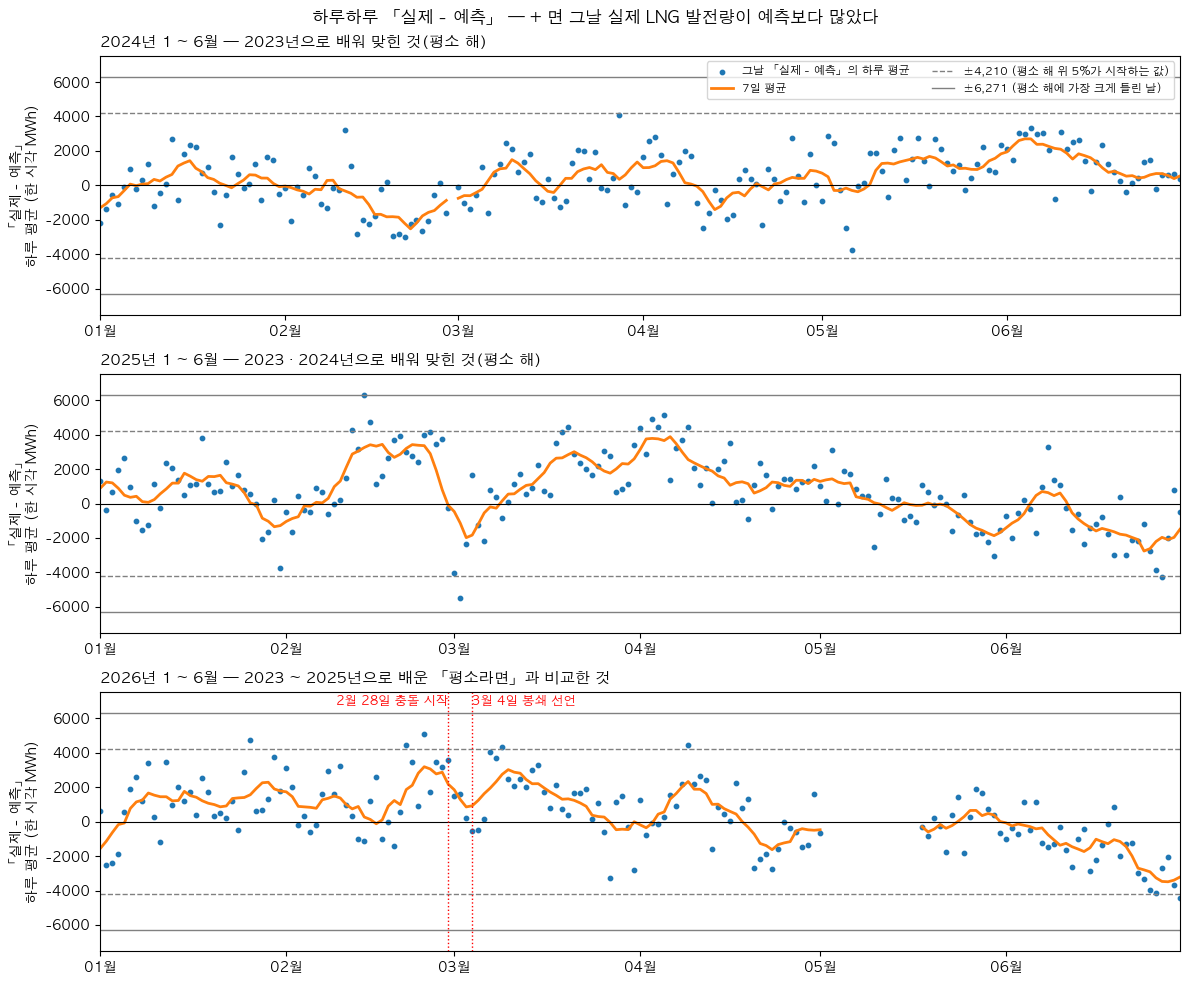

In [157]:
# 9단계 모델 적용 · 3-나
import matplotlib.pyplot as plt                                                       # 그림을 그리는 라이브러리
import matplotlib.dates as mdates                                                     # 가로축에 날짜 눈금을 넣는다
plt.rcParams["font.family"] = "AppleGothic"                                           # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False                                            # 그림의 마이너스 부호가 깨지지 않게

# ── 날마다 「실제 − 예측」의 하루 평균 — 평소 해는 맨 위 준비 ②, 2026년은 2-가가 만든 값 ──
날 = {해: 잔차.groupby(잔차.index.normalize()).mean() for 해, 잔차 in 평소.items()}          # 2024 · 2025년 — 3-가와 같은 값
날[2026] = 차이["실제 − 평소라면"].groupby(차이.index.normalize()).mean()                  # 2026년 1 ~ 6월(5월 2 ~ 17일 빠짐) — 2-가의 세 해 모델
두해 = pd.concat([날[2024], 날[2025]]).abs()                                              # 평소 해 두 해의 날을 + · −를 떼고
점선 = 두해.quantile(0.95)                                                                 # 위 5%가 시작하는 값 — 3-가 [표 1]과 같다
실선 = 두해.max()                                                                          # 평소 해에 가장 크게 틀린 날 — 3-가 [표 1]과 같다
한계 = max(실선 * 1.2, max(날[해][날[해].index.month <= 6].abs().max() for 해 in 날) * 1.05)   # 세로 눈금 끝 — 점이 다 들어가고 글이 선 위에 오게

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharey=True)                              # 세 칸 — 세로 눈금이 같다
제목 = {2024: "2024년 1 ~ 6월 — 2023년으로 배워 맞힌 것(평소 해)",
        2025: "2025년 1 ~ 6월 — 2023 · 2024년으로 배워 맞힌 것(평소 해)",
        2026: "2026년 1 ~ 6월 — 2023 ~ 2025년으로 배운 「평소라면」과 비교한 것"}
for ax, 해 in zip(axes, [2024, 2025, 2026]):
    s = 날[해][날[해].index.month <= 6]                                                     # 1 ~ 6월만
    ax.scatter(s.index, s.values, s=10, color="tab:blue", label="그날 「실제 - 예측」의 하루 평균")   # 점 — 날마다 하나
    s7 = s.rolling("7D", center=True, min_periods=4).mean().asfreq("D")                     # 7일 평균 — 그날과 앞뒤 사흘. 자료가 없는 날은 비워 두어 선을 잇지 않는다
    ax.plot(s7.index, s7.values, color="tab:orange", lw=2, label="7일 평균")                # 굵은 선 — 읽기만 한다
    for 높이, 선종류, 이름 in [(점선, "--", f"±{점선:,.0f} (평소 해 위 5%가 시작하는 값)"),
                           (실선, "-", f"±{실선:,.0f} (평소 해에 가장 크게 틀린 날)")]:
        ax.axhline(높이, ls=선종류, color="gray", lw=1, label=이름)                            # 위쪽 선
        ax.axhline(-높이, ls=선종류, color="gray", lw=1)                                       # 아래쪽 선
    ax.axhline(0, color="black", lw=0.8)                                                    # 0 — 예측과 같다
    if 해 == 2026:
        for d, 글 in [("2026-02-28", "2월 28일 충돌 시작"), ("2026-03-04", "3월 4일 봉쇄 선언")]:
            ax.axvline(pd.Timestamp(d), color="red", lw=1, ls=":")                         # 봉쇄 앞뒤를 보려는 세로선
            ax.text(pd.Timestamp(d), 실선 * 1.08, 글, color="red", fontsize=9,
                    ha="right" if d.endswith("28") else "left")                             # 두 글이 겹치지 않게 좌우로
    ax.set_xlim(pd.Timestamp(f"{해}-01-01"), pd.Timestamp(f"{해}-06-30"))                    # 세 칸 모두 1 ~ 6월
    ax.set_ylim(-한계, 한계)                                                                  # 세 칸 같은 눈금
    ax.xaxis.set_major_locator(mdates.MonthLocator())                                       # 달마다 눈금
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m월"))                              # 01월 · 02월 …
    ax.set_title(제목[해], fontsize=11, loc="left")
    ax.set_ylabel("「실제 - 예측」\n하루 평균 (한 시각 MWh)")                                   # 세로축은 LNG 발전량이 아니라 그날 「실제 - 예측」의 평균
axes[0].legend(loc="upper right", fontsize=8, ncol=2)                                       # 선 이름은 맨 위 칸에만
fig.suptitle("하루하루 「실제 - 예측」 — + 면 그날 실제 LNG 발전량이 예측보다 많았다", fontsize=12)          # 맥 글꼴(AppleGothic)에 없는 긴 빼기표 대신 -
plt.tight_layout()
plt.show()

## 3-다 — 4,210 · 6,271보다 크게 틀린 날을 해마다 세면 (2024 · 2025 · 2026년 1 ~ 6월)

**이 셀이 답하는 물음** — 「아예 우리가 정했던, 4000대, 혹은 6000대를 넘어서는 지점들을 찾아서」 · 「2번 그래프에 비해 상대적으로 그러니까 평균보다 적은 지점들이 조금 더 많이 찍혔다는 것 정도?」(창주 님, 3-나 「✍️ 내 답변」)

**표의 숫자**

- [표 1] — 해마다 1 ~ 6월의 날을 크기(+ · − 뗌)로 셉니다. 4,210(평소 해 699일의 위 5%가 시작하는 값)과 6,271(평소 해에 가장 크게 틀린 날)은 3-가 [표 1] 「두 해」 줄과 같은 값입니다. 해마다 비교한 날 수가 달라서(2026년은 5월 2 ~ 17일이 빠짐) 「100일에 몇 날」로 맞춰 놓습니다. 평소 해 두 줄의 「6,271보다 크게 틀린 때」는 6,271이 두 해에서 가장 큰 값이라 늘 0이고, 2026년 줄만 봅니다.
- [표 2] — 해마다 1 ~ 6월의 날을 0보다 위(실제가 예측보다 많았다) · 아래(적었다)로 셉니다.
- [표 3] — 2026년 1 ~ 6월에 4,210보다 크게 틀린 날을 날짜순으로 적습니다. 「충돌 · 봉쇄와」는 그날이 2월 28일(충돌 시작)과 3월 4일(봉쇄 선언)의 앞인지, 그 사이인지, 뒤인지입니다.
- 2024 · 2025년은 평소 해에 모델이 틀린 양이고, 2026년은 「실제 − 평소라면」입니다. + 는 세 해 모두 실제가 많았다는 뜻입니다. 모델끼리 비교하는 표가 아닙니다.

In [158]:
# 9단계 모델 적용 · 3-다
assert "차이" in globals() and "입력26" in globals(), "맨 위 준비 ① ~ ③과 2-가를 먼저 돌려 주세요 — 2026년 「실제 − 평소라면」은 2-가에서, 2026년 날 종류는 준비 ③에서 만들어집니다"
# ── 날마다 「실제 − 예측」의 하루 평균 — 3-가 · 3-나와 같은 값. 평소 해는 맨 위 준비 ②, 2026년은 2-가 ──
날마다 = {해: 잔차.groupby(잔차.index.normalize()).mean() for 해, 잔차 in 평소.items()}             # 2024 · 2025년 — 평소 해에 모델이 틀린 양
날마다[2026] = 차이["실제 − 평소라면"].groupby(차이.index.normalize()).mean()                      # 2026년 1 ~ 6월(5월 2 ~ 17일 빠짐)
두해 = pd.concat([날마다[2024], 날마다[2025]]).abs()                                               # 평소 해 두 해(699일)의 크기 — + · −를 뗀다
점선, 실선 = 두해.quantile(0.95), 두해.max()                                                        # 위 5%가 시작하는 값 · 가장 크게 틀린 날 — 3-가 [표 1] 「두 해」 줄과 같은 값

def 몇번(날짜들):                                                                                   # 이어진 날은 한 번으로 센다 — 3-가 「✍️ 정할 것」 아래 답변에서 정한 것
    d = pd.Series(sorted(날짜들))
    return int((d.diff() != pd.Timedelta(days=1)).sum())

표1, 표2 = [], []                                                                                   # [표 1] 크기로 센 것 · [표 2] 0보다 위 · 아래로 센 것 — 줄은 해마다 하나
for 해 in [2024, 2025, 2026]:
    s = 날마다[해][날마다[해].index.month <= 6]                                                      # 1 ~ 6월만
    이름 = f"{해}년 1 ~ 6월" + (" (평소 해)" if 해 < 2026 else " (실제 − 평소라면)")
    넘음 = s[s.abs() > 점선]                                                                         # 위 5%가 시작하는 값보다 크게 틀린 날
    표1.append({"해": 이름,
                "비교한 날": len(s),
                f"{점선:,.0f}보다 크게 틀린 날": len(넘음),
                "그 날이 100일에 몇 날": f"{len(넘음) / len(s) * 100:.1f}",                          # 해마다 비교한 날 수가 달라서 100일로 맞춘다
                "그 가운데 + 쪽 · − 쪽 (+ 면 실제가 많았다)": f"{int((넘음 > 0).sum())} · {int((넘음 < 0).sum())}",
                f"{실선:,.0f}보다 크게 틀린 때 (이어진 날은 한 번)": 몇번(s.index[s.abs() > 실선]),
                "가장 크게 틀린 날의 크기": f"{s.abs().max():,.0f}"})
    표2.append({"해": 이름,
                "비교한 날": len(s),
                "0보다 위인 날 (실제가 예측보다 많았다)": int((s > 0).sum()),
                "0보다 아래인 날 (실제가 예측보다 적었다)": int((s < 0).sum()),
                "아래인 날이 100일에 몇 날": f"{(s < 0).mean() * 100:.0f}"})
표1 = pd.DataFrame(표1).set_index("해")
표2 = pd.DataFrame(표2).set_index("해")

# ── [표 3] 2026년에 위 5%가 시작하는 값보다 크게 틀린 날 — 그날이 무슨 날이었나 ──
s26 = 날마다[2026]
넘26 = s26[s26.abs() > 점선]                                                                         # 날짜순
날종류26 = 입력26["날 종류"].groupby(입력26.index.normalize()).first()                               # 준비 ③이 만든 2026년 날 종류(월 · 화~금 · 토 · 일 · 공휴일 · 명절)
휴일표 = pd.read_csv(os.path.join(RAW, "holidays_kr.csv"), encoding="utf-8-sig")                     # 2단계에서 받아 둔 공휴일 파일 — 3-가와 같다
휴일이름 = 휴일표.assign(날=pd.to_datetime(휴일표["date"])).groupby("날")["name"].agg(" · ".join)      # 날짜마다 공휴일 이름
요일이름 = ["월", "화", "수", "목", "금", "토", "일"]
def 봉쇄와(d):                                                                                       # 2월 28일 충돌 시작 · 3월 4일 봉쇄 선언
    return "앞" if d < pd.Timestamp("2026-02-28") else ("사이" if d < pd.Timestamp("2026-03-04") else "뒤")
표3 = pd.DataFrame({"날짜": [d.strftime("%Y-%m-%d") for d in 넘26.index],
                    "요일": [요일이름[d.dayofweek] for d in 넘26.index],
                    "날 종류": [날종류26[d] for d in 넘26.index],
                    "공휴일 이름": [휴일이름.get(d, "—") for d in 넘26.index],                       # 공휴일이 아니면 —
                    "그날 「실제 − 평소라면」 (+ 면 실제가 많았다)": [f"{v:+,.0f}" for v in 넘26.values],
                    "충돌 · 봉쇄와": [봉쇄와(d) for d in 넘26.index]},
                   index=range(1, len(넘26) + 1))

print(f"[표 1] 해마다 1 ~ 6월의 날을 크기(+ · − 뗌)로 세면 — {점선:,.0f}은 평소 해 위 5%가 시작하는 값, {실선:,.0f}은 평소 해에 가장 크게 틀린 날(3-가 [표 1] 「두 해」 줄)")
print(f"       평소 해 두 줄의 「{실선:,.0f}보다 크게 틀린 때」는 {실선:,.0f}이 두 해에서 가장 큰 값이라 늘 0이다 — 2026년 줄만 본다")
display(표1)
print("[표 2] 해마다 1 ~ 6월의 날을 0보다 위 · 아래로 세면 — 0은 「실제 = 예측」인 선")
display(표2)
print(f"[표 3] 2026년 1 ~ 6월에 {점선:,.0f}보다 크게 틀린 날(날짜순) — 「충돌 · 봉쇄와」는 앞 2월 27일까지 · 사이 2월 28일(충돌 시작) ~ 3월 3일 · 뒤 3월 4일(봉쇄 선언)부터")
if len(표3):
    display(표3)
else:
    print("       없다")

[표 1] 해마다 1 ~ 6월의 날을 크기(+ · − 뗌)로 세면 — 4,210은 평소 해 위 5%가 시작하는 값, 6,271은 평소 해에 가장 크게 틀린 날(3-가 [표 1] 「두 해」 줄)
       평소 해 두 줄의 「6,271보다 크게 틀린 때」는 6,271이 두 해에서 가장 큰 값이라 늘 0이다 — 2026년 줄만 본다


,비교한 날,"4,210보다 크게 틀린 날",그 날이 100일에 몇 날,그 가운데 + 쪽 · − 쪽 (+ 면 실제가 많았다),"6,271보다 크게 틀린 때 (이어진 날은 한 번)",가장 크게 틀린 날의 크기
해,,,,,,
2024년 1 ~ 6월 (평소 해),181,0,0.0,0 · 0,0,"4,064"
2025년 1 ~ 6월 (평소 해),181,11,6.1,9 · 2,0,"6,271"
2026년 1 ~ 6월 (실제 − 평소라면),165,6,3.6,5 · 1,0,"5,089"


[표 2] 해마다 1 ~ 6월의 날을 0보다 위 · 아래로 세면 — 0은 「실제 = 예측」인 선


,비교한 날,0보다 위인 날 (실제가 예측보다 많았다),0보다 아래인 날 (실제가 예측보다 적었다),아래인 날이 100일에 몇 날
해,,,,
2024년 1 ~ 6월 (평소 해),181,105,76,42
2025년 1 ~ 6월 (평소 해),181,118,63,35
2026년 1 ~ 6월 (실제 − 평소라면),165,98,67,41


[표 3] 2026년 1 ~ 6월에 4,210보다 크게 틀린 날(날짜순) — 「충돌 · 봉쇄와」는 앞 2월 27일까지 · 사이 2월 28일(충돌 시작) ~ 3월 3일 · 뒤 3월 4일(봉쇄 선언)부터


,날짜,요일,날 종류,공휴일 이름,그날 「실제 − 평소라면」 (+ 면 실제가 많았다),충돌 · 봉쇄와
1,2026-01-26,월,월,—,"+4,713",앞
2,2026-02-21,토,토,—,"+4,463",앞
3,2026-02-24,화,화~금,—,"+5,089",앞
4,2026-03-09,월,월,—,"+4,308",뒤
5,2026-04-09,목,화~금,—,"+4,456",뒤
6,2026-06-30,화,화~금,—,"-4,416",뒤


## 3-라 — 낮(10 ~ 15시)과 밤(0 ~ 5시)으로 나눠 보면 (2026년 1 ~ 6월, 평소 해 스물세 달과 비교)

**이 셀이 답하는 물음** — 물음 3의 「날 · 시각 단위로 나눠 봐도 평소 범위 안인가」 가운데 시각(낮과 밤)입니다.

**표의 숫자**

- [표 1] — 평소 해 스물세 달(2024년 8월은 자료 없음)의 낮 · 밤 「실제 − 예측」 달 평균을 크기(+ · − 뗌)로 본 것입니다. 「가장 크게 틀린 달의 크기」가 2026년을 비교하는 기준입니다(물음 1의 2,177과 같은 방식).
- [표 2] — 2026년 달마다 낮 · 밤 「실제 − 평소라면」입니다. + 면 실제가 평소라면보다 많았습니다. 「평소 해와 비교」는 그 크기가 [표 1]의 가장 크게 틀린 달 안인지입니다. 맨 오른쪽 「하루 전체 24시각」은 2-가 [표]의 값이고, 기준(2,177)이 달라 옆에 놓기만 합니다.
- 모델끼리 비교하는 표가 아닙니다.

In [159]:
# 9단계 모델 적용 · 3-라
assert "차이" in globals(), "맨 위 준비 ① ~ ③과 2-가를 먼저 돌려 주세요 — 2026년 「실제 − 평소라면」은 2-가에서 만들어집니다"
# ── 낮(10 ~ 15시) · 밤(0 ~ 5시)으로 나눠 달마다 「실제 − 예측」을 평균 낸다 — 7단계 3-라와 같은 시각 ──
def 낮밤(s):                                                                       # 시각마다 「실제 − 예측」 → 달마다 낮 평균 · 밤 평균
    시 = s.index.hour
    낮, 밤 = (시 >= 10) & (시 <= 15), 시 <= 5
    return pd.DataFrame({"낮": s[낮].groupby(s.index[낮].month).mean(),
                         "밤": s[밤].groupby(s.index[밤].month).mean()})
평소낮밤 = pd.concat({해: 낮밤(잔차) for 해, 잔차 in 평소.items()})                  # 2024 · 2025년 스물세 달 — 맨 위 준비 ②의 잔차(2024년 8월은 자료 없음)
낮밤26 = 낮밤(차이["실제 − 평소라면"])                                               # 2026년 1 ~ 6월 — 2-가의 세 해 모델(5월은 1일 · 18 ~ 31일)
하루26 = 차이["실제 − 평소라면"].groupby(차이.index.month).mean()                     # 하루 전체 24시각 — 2-가 [표]와 같은 값

기준, 표1 = {}, []                                                                   # 낮 · 밤마다 평소 해에 가장 크게 틀린 달의 크기 — 물음 1의 2,177과 같은 방식
for 때, 시각 in [("낮", "10 ~ 15시"), ("밤", "0 ~ 5시")]:
    크기 = 평소낮밤[때].abs()                                                          # + · −를 뗀 크기
    해, 달 = 크기.idxmax()                                                             # 가장 크게 틀린 달
    기준[때] = 크기.max()
    표1.append({"시각": f"{때} ({시각})", "달 수": len(크기),
                "달마다 틀린 양의 크기 평균": f"{크기.mean():,.0f}",
                "가장 크게 틀린 달의 크기": f"{기준[때]:,.0f}",
                "그 달 (+ 면 실제가 많았다)": f"{해}년 {달}월 {평소낮밤[때][(해, 달)]:+,.0f}"})
표1 = pd.DataFrame(표1).set_index("시각")

def 비교(v, 때):                                                                     # [표 1]의 가장 크게 틀린 달과 비교
    return "평소 범위 안" if abs(v) <= 기준[때] else "넘는다"
표2 = pd.DataFrame({"낮 「실제 − 평소라면」": 낮밤26["낮"].map("{:+,.0f}".format),
                    "낮 — 평소 해와 비교": [비교(v, "낮") for v in 낮밤26["낮"]],
                    "밤 「실제 − 평소라면」": 낮밤26["밤"].map("{:+,.0f}".format),
                    "밤 — 평소 해와 비교": [비교(v, "밤") for v in 낮밤26["밤"]],
                    "옆에 · 하루 전체 24시각 (2-가, 기준은 2,177)": 하루26.map("{:+,.0f}".format)})
표2.index = [f"{m}월" for m in 표2.index]

print("[표 1] 평소 해(2024 · 2025년) 스물세 달 — 낮 · 밤마다 「실제 − 예측」의 달 평균을 크기(+ · − 뗌)로 본 것 · 한 시각 MWh")
print("       2024년은 2023년으로, 2025년은 2023 · 2024년으로 배워 맞힌 것 — 3-가 · 3-다와 같은 잔차")
display(표1)
print("[표 2] 2026년 1 ~ 6월 달마다 낮 · 밤 「실제 − 평소라면」 — + 면 실제가 평소라면보다 많았다 · 5월은 1일 · 18 ~ 31일의 15일")
print(f"       「평소 범위 안」은 그 크기가 [표 1]의 가장 크게 틀린 달(낮 {기준['낮']:,.0f} · 밤 {기준['밤']:,.0f}) 안이라는 뜻")
display(표2)

[표 1] 평소 해(2024 · 2025년) 스물세 달 — 낮 · 밤마다 「실제 − 예측」의 달 평균을 크기(+ · − 뗌)로 본 것 · 한 시각 MWh
       2024년은 2023년으로, 2025년은 2023 · 2024년으로 배워 맞힌 것 — 3-가 · 3-다와 같은 잔차


,달 수,달마다 틀린 양의 크기 평균,가장 크게 틀린 달의 크기,그 달 (+ 면 실제가 많았다)
시각,,,,
낮 (10 ~ 15시),23,964,"2,769","2025년 12월 -2,769"
밤 (0 ~ 5시),23,"1,168","3,194","2025년 4월 +3,194"


[표 2] 2026년 1 ~ 6월 달마다 낮 · 밤 「실제 − 평소라면」 — + 면 실제가 평소라면보다 많았다 · 5월은 1일 · 18 ~ 31일의 15일
       「평소 범위 안」은 그 크기가 [표 1]의 가장 크게 틀린 달(낮 2,769 · 밤 3,194) 안이라는 뜻


,낮 「실제 − 평소라면」,낮 — 평소 해와 비교,밤 「실제 − 평소라면」,밤 — 평소 해와 비교,"옆에 · 하루 전체 24시각 (2-가, 기준은 2,177)"
1월,-804,평소 범위 안,+852,평소 범위 안,"+1,096"
2월,-494,평소 범위 안,"+1,305",평소 범위 안,"+1,446"
3월,-911,평소 범위 안,"+1,342",평소 범위 안,"+1,211"
4월,-960,평소 범위 안,-70,평소 범위 안,+257
5월,-292,평소 범위 안,-277,평소 범위 안,+38
6월,"-2,020",평소 범위 안,"-1,206",평소 범위 안,"-1,595"


## 3-마 — 날 종류마다 · 30도 넘는 시각에 나눠 보면 (2024 · 2025 · 2026년 1 ~ 6월)

**이 셀이 답하는 물음** — 물음 3의 「날 · 시각 단위로 나눠 봐도 평소 범위 안인가」 가운데 날 종류입니다. 7단계 물음 3에서 2025년에 모델이 크게 틀린 날 · 시각(토요일 · 연휴 · 30도 넘는 시각)을 2026년 같은 날 · 시각 옆에 놓는 일도 여기서 합니다.

**표의 숫자**

- [표 1] — 날 종류(5단계에서 만든 여섯 가지 — 토 · 일에 든 공휴일은 토 · 일, 명절은 설 · 추석 연휴)마다, 그리고 30도 넘는 시각만 모아 1 ~ 6월 「실제 − 예측」을 평균 낸 값입니다(한 시각 MWh). 2024 · 2025년은 평소 해에 모델이 틀린 양, 2026년은 「실제 − 평소라면」이고, + 면 실제가 많았습니다. 맨 오른쪽 칸은 2026년 값의 크기가 평소 해 두 해 가운데 더 크게 틀린 해의 크기 안인지입니다.
- [표 2] — [표 1]의 평균을 낸 날 수입니다(30도 넘는 시각은 시각 수). 공휴일 · 명절은 해마다 서너 날이라 한두 날로 크게 흔들립니다.
- 모델끼리 비교하는 표가 아닙니다.

In [160]:
# 9단계 모델 적용 · 3-마
assert "차이" in globals() and "입력26" in globals(), "맨 위 준비 ① ~ ③과 2-가를 먼저 돌려 주세요 — 2026년 「실제 − 평소라면」은 2-가, 2026년 날 종류와 기온은 준비 ③에서 만들어집니다"
# ── 날 종류마다 · 30도 넘는 시각에 1 ~ 6월 「실제 − 예측」을 평균 낸다 — 평소 해는 맨 위 준비 ②의 잔차, 2026년은 2-가 ──
종류순서 = ["월", "화~금", "토", "일", "공휴일", "명절"]                                         # 5단계 「저장」 셀이 만든 여섯 가지
def 나눔(잔차, 날종류, 기온):                                                                    # 시각마다 잔차 → 묶음마다 평균 · 날 수(30도 넘는 시각은 시각 수)
    s = 잔차[잔차.index.month <= 6]                                                              # 1 ~ 6월만
    k, t = 날종류.reindex(s.index), 기온.reindex(s.index)                                        # 그 시각의 날 종류 · 기온
    평균 = {g: s[k == g].mean() for g in 종류순서}
    개수 = {g: s[k == g].index.normalize().nunique() for g in 종류순서}
    더움 = t > 30                                                                                 # 30도 넘는 시각
    평균["30도 넘는 시각"] = s[더움].mean() if 더움.any() else np.nan                              # 없으면 빈 칸
    개수["30도 넘는 시각"] = int(더움.sum())
    return pd.Series(평균), pd.Series(개수)
결과 = {해: 나눔(잔차, 전체["날 종류"], 전체["ta"]) for 해, 잔차 in 평소.items()}                  # 2024 · 2025년 — 평소 해에 모델이 틀린 양
결과[2026] = 나눔(차이["실제 − 평소라면"], 입력26["날 종류"], 입력26["ta"])                          # 2026년 — 5월 2 ~ 17일 빠짐
평균표 = pd.DataFrame({해: 결과[해][0] for 해 in [2024, 2025, 2026]})
개수표 = pd.DataFrame({해: 결과[해][1] for 해 in [2024, 2025, 2026]})
경계 = 평균표[[2024, 2025]].abs().max(axis=1)                                                     # 평소 해 두 해 가운데 더 크게 틀린 해의 크기

def 숫자(v): return "—" if pd.isna(v) else f"{v:+,.0f}"
def 비교(v, b): return "—" if pd.isna(v) or pd.isna(b) else ("안" if abs(v) <= b else "넘는다")
표1 = pd.DataFrame({"2024년 1 ~ 6월 (평소 해)": 평균표[2024].map(숫자),
                    "2025년 1 ~ 6월 (평소 해)": 평균표[2025].map(숫자),
                    "2026년 1 ~ 6월 (실제 − 평소라면)": 평균표[2026].map(숫자),
                    "2026년 차이의 크기가 평소 해 두 해에 틀린 크기 안인가": [비교(v, b) for v, b in zip(평균표[2026], 경계)]})
표2 = 개수표.rename(columns={2024: "2024년 1 ~ 6월 날 수", 2025: "2025년 1 ~ 6월 날 수", 2026: "2026년 1 ~ 6월 날 수"},   # [표 1]의 차이가 아니라 날 수라는 것을 칸 이름에 적는다
                    index={"30도 넘는 시각": "30도 넘는 시각 (시각 수)"})

print("[표 1] 날 종류마다 · 30도 넘는 시각의 1 ~ 6월 「실제 − 예측」 평균 — 한 시각 MWh · + 면 실제가 예측(2026년은 평소라면)보다 많았다")
print("       날 종류는 5단계에서 만든 여섯 가지(토 · 일에 든 공휴일은 토 · 일, 명절은 설 · 추석 연휴) · 오른쪽 칸의 기준은 평소 해 두 해 가운데 더 크게 틀린 해의 크기")
display(표1)
print("[표 2] [표 1]의 평균을 낸 날 수(30도 넘는 시각은 시각 수) — 수가 적은 줄은 한두 날로 크게 흔들린다")
display(표2)

[표 1] 날 종류마다 · 30도 넘는 시각의 1 ~ 6월 「실제 − 예측」 평균 — 한 시각 MWh · + 면 실제가 예측(2026년은 평소라면)보다 많았다
       날 종류는 5단계에서 만든 여섯 가지(토 · 일에 든 공휴일은 토 · 일, 명절은 설 · 추석 연휴) · 오른쪽 칸의 기준은 평소 해 두 해 가운데 더 크게 틀린 해의 크기


,2024년 1 ~ 6월 (평소 해),2025년 1 ~ 6월 (평소 해),2026년 1 ~ 6월 (실제 − 평소라면),2026년 차이의 크기가 평소 해 두 해에 틀린 크기 안인가
월,+867,+913,+405,안
화~금,+481,+889,+247,안
토,+444,+506,+754,넘는다
일,-310,+391,"+1,041",넘는다
공휴일,-635,+44,-206,안
명절,+978,"-1,172",+501,안
30도 넘는 시각,+8,"-2,232","-2,032",안


[표 2] [표 1]의 평균을 낸 날 수(30도 넘는 시각은 시각 수) — 수가 적은 줄은 한두 날로 크게 흔들린다


,2024년 1 ~ 6월 날 수,2025년 1 ~ 6월 날 수,2026년 1 ~ 6월 날 수
월,23,23,21
화~금,98,96,90
토,25,26,23
일,25,26,23
공휴일,6,7,5
명절,4,3,3
30도 넘는 시각 (시각 수),84,46,75


# 물음 4 — 눈에 띈 넷은 왜 그렇게 나왔나 (외부 사건의 날짜와 나란히 놓고 본다)

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 4 결론

**왜 생긴 물음인가** — 물음 1 ~ 3에서 2026년 1 ~ 6월 LNG는 달 · 날 · 시각 · 날 종류로 나눠 봐도 평소 범위 안이었습니다. 그래도 그 안에서 눈에 띈 것이 넷 있었고(1 석탄이 2월부터 평소보다 많았다 · 2 원전이 1월부터 평소보다 적었다 · 3 6월에 낮 · 밤 모두 LNG가 적었다 · 4 주말에 LNG가 많았다), 그 넷이 왜 그렇게 나왔는지를 우리 자료와 외부 사건의 날짜로 찾는 물음입니다(창주 님 「그러니까 우리가 원래 보려고 했던 것들, 그중에서도 좀 튀어오르는 애들에서 원인을 찾아보려는거지?」).

### 결정 — 원전이 1월부터 적었던 것(2026년 전에 멈춘 원전 넷 — 후보)과 석탄이 평일에 많았던 것(까닭은 찾지 못함)이 서로 상쇄됐다. 6월은 낮에는 수요, 밤에는 석탄 쪽이고, 주말은 석탄이 평일에만 많았던 것 쪽이다. 이 까닭을 물음 2 결론에도 한 줄로 적는다

**같이 정한 것**

1. 석탄 설비용량 화살표는 「못 봄」 그대로 둔다 — 석탄이 태울 수 있는 최대는 우리 자료로 낼 수 없다(4-나 「✍️ 정할 것」 — 다).
2. 원전 정비 일정 자료는 찾아봤지만 쓸 수 없었다 — 한수원 API는 최근 엿새만 준다(4-다 「✍️ 정할 것」 — 가, 2a단계 `02_데이터보기` 물음 9).

**결정 근거**

- 물음 4 전체 — 창주 님 말을 엮은 것(10-27 채팅에서 확인하심, 「좋아 동의해」): 「원전 발전량이 금년부터 평소보다 많이 적어서 lng가 평소보다 더 많이 사용됐지만, 석탄이 그 부족분을 같이 채워서 하나의 파이를 lng가 다 차지한 게 아니라 석탄이 부족분을 채웠다. 석탄은 주말에는 평소만큼 정도이고 평일에만 평소보다 많아서 lng가 줄었다. 상한이 풀리는 상황이라도 평소와 크게 다르지 않고 범위 안에 있었고, 요금 동결이라 b2 · r1도 작동하지 않았다. 1월은 크리티컬하게 추웠지만 열병합 하나로 치부하긴 어렵다.」
- 1(석탄) — 4-가 주마다 그림: 석탄은 1월 22일 주부터 평소보다 많았고, 외부 사건(2월 28일부터)보다 앞이다. 4-나 [표]: 3월 16일 상한 해제 앞뒤 14일의 「뒤 - 앞」 −1,449는 평소 해 범위(−759 ~ −2,553) 안이다. 4-라: 석탄 줄 평일 −1,360 · 주말 +131 — 평일에만 평소보다 많았다. 석탄으로 들어오는 외부 사건 가운데 평일 · 주말을 가르는 일은 없다(판단).
- 2(원전) — 4-가: 원전은 1월 첫 주부터 평소보다 적었다. 4-다 [표 1]: 설비용량 열은 멈춘 원전까지 센다. [표 2]: 4월 4일 앞뒤 2026년만 +551(평소 해 −255 ~ −600) — 고리 2호기가 그 무렵 들어왔다는 쪽의 후보. [표 3]: 새울 3호기는 평소 해 범위 안 — 가를 수 없다.
- 3 · 4(6월 · 주말) — 4-라 [표 1]: 「주말 − 평일」 맨 위 +763, 넷 가운데 석탄 +1,492만 범위 위. [표 2] · [표 3]: 6월 수요 낮 −3,849 · 밤 −364, 석탄 낮 −116 · 밤 −1,923. 수요가 낮에 적었던 까닭은 요금 쪽이 아니고(1 ~ 6월 요금 동결), 그 밖은 가를 수 없다.
- 물음 2 결론에 더한다 — 창주 님 「나는 당연히 비용이 크지 않다면 한계랑 뭐 결론에 제대로 더 잘 적히는게 좋다고 생각하는데?」(4-라 아래 「✍️ 정할 것」).

**고리마다 — 7단계 인과지도의 고리와 열병합을 2026년 차이 옆에** (4-라 아래 고리 문답 · 4-마)

| 고리 | 일어났어야 하는 것 | 9단계에서 본 것 | 창주 님 답 | 그래서 |
|---|---|---|---|---|
| B1 석탄 고리(균형) | 봉쇄(3월 4일) · 상한 해제(3월 16일, 지연 12일) 바로 뒤에 석탄이 늘고 LNG가 준다 | 석탄은 그보다 앞인 1월 22일 주부터 평일에 많았고, 3월 16일 뒤에 더 늘지 않았다(4-가 · 4-나 · 4-라) | 「작동했다면 상한 해제 이후 바로 늘어야 적합하지 않을까??」 | 1 ~ 6월에는 B1이 말하는 때에 석탄이 움직이지 않았다. 원전이 모자란 몫을 석탄이 먼저 채웠을 수 있다(판단) |
| B2 요금 고리(균형) | 요금이 오른 뒤 수요가 준다(지연 — 요금은 분기마다 정한다) | 2분기 · 3분기 요금 동결(확인 — 3월 23일 · 6월 22일 발표, 한국경제TV · YTN 사이언스 · YTN) | 「아니 b2로 설명할수 없을거같어. 지연이 길어서」 | 1 ~ 6월에는 움직이지 않았다. 6월 낮 수요가 적었던 까닭은 B2가 아니다 |
| R1 작은 강화 고리 | B2와 같이 움직인다(앞의 세 칸이 같다) | B2가 움직이지 않았다 | 「요금 동결이면 r1도 작동하지 않겠지??」 | 1 ~ 6월에는 움직이지 않았다 |
| 열병합(추운 정도 → LNG, 근거 「못 봄」) | 평소보다 추우면 LNG가 더 는다 | 1월만 평소 해보다 추웠다(4-마 — 평균 −3.6°C · 0도 아래 569시각). 1월 LNG +1,124는 원전 줄 +2,155로 설명되고 열병합 몫은 보이지 않는다(판단) | 「이것을 열병합 하나로 치부하긴 좀 어려울 것 같은데??」 | 근거 「못 봄」 그대로 |

**인과지도** — 물음 4에서 본 것은 모두 후보이거나 가를 수 없음이라, 근거(4단계 실측 · 일부러 자름 · 못 봄)를 바꿀 화살표는 없다(클로드 판단 — 창주 님 「응 동의해」). 고리가 어느 길인지는 그림 아래 세 줄에 적었다(`figures/인과지도_9단계.png`).

**석탄이 평일에만 많았던 까닭(짐작)** — 창주 님 「원자력도 줄고 그래서 그 부족분을 채우려고 했는데 lng의 요동이나 가격변화 등등의 여러 요소가 겹쳐서 부족분을 석탄이 채운거 아닐까??」 · 「주말에는 원래 자체적으로 에너지 소모량이 주중보다는 적으니까 그 부족분이라는 절대량이 적어서 석탄이 굳이 많이 태울 필요가 없었는지 모르겠어」. 평일 쪽은 우리가 본 것과 맞다. 다만 원전이 모자란 몫은 주말에도 평일과 비슷했고(4-라 [표 1] 원전 줄 주말 − 평일 +208), 주말에 석탄이 평소보다 적었던 것은 아침 · 낮(6 ~ 15시)이었으며 LNG는 그 시간이 아니라 밤 · 아침 · 저녁에 평소보다 많았다(4-바). 주말에 왜 석탄이 아니라 LNG가 원전 몫을 더 채웠는지는 발전기마다의 운전 기록이 없어 가를 수 없다(열린 물음 — 11단계 한계).

**남은 것**

- 10단계(차이를 LNG 톤 · 카고로 바꾸고 같은 달 석탄 · 원전 변화를 나란히 놓는 단계) — 이 결론의 원전 · 석탄 줄을 쓴다.
- 11단계 한계 — 닫는 칸 ③(다른 원전 정비가 섞이는 것 · 4-나는 날씨를 맞추지 않은 비교 등).
- 원전마다의 자료가 필요해지면 한수원 API를 날마다 불러 모은다(README 「되돌아올 수 있는 곳」).

</div>

## 4-가 — 원전 · 석탄 발전량은 언제부터 평소와 달랐나 (주마다, 외부 사건의 날짜와 나란히)

**이 셀이 답하는 물음** — 「튀어오르는 애들에서 원인을 찾아보려는거지?」(창주 님) 가운데 1 · 2 — 석탄 발전량이 평소보다 많아지고 원전 발전량이 평소보다 적어진 것이 언제부터였고, 그때가 외부 사건의 날짜보다 앞인가 뒤인가.

**그림** — 위 칸은 원전, 아래 칸은 석탄입니다.

- 세로축 — 그 주 시각마다 「발전량 − 평소라면」을 평균 낸 값입니다(한 시각 MWh). + 면 그 주에 그 발전원의 발전량이 평소보다 많았고, − 면 적었습니다. 「평소라면」은 2-나와 같은 선형회귀가 날씨 · 시간대 · 날 종류로 맞힌 그 발전원의 발전량입니다. 두 칸은 세로축 눈금이 같고, 0을 가운데 두고 위아래를 같은 폭으로 그렸습니다. 오른쪽 눈금은 같은 값을, 평소 해(2023 ~ 2025년) 1 ~ 6월에 그 발전원이 한 시각에 낸 평균(칸 제목에 있음)에 대한 %로 바꾼 것입니다 — 세로축의 폭만 보면 작은 차이도 크게 보일 수 있어서, 평소 발전량의 몇 %인지 같이 보려고 둔 눈금입니다.
- 부호 — 2-나 [표 1]은 + 면 LNG 발전량이 늘었다는 쪽이었습니다. 이 그림은 + 면 그 발전원의 발전량이 많았다는 쪽이라, 2-나에서 + 였던 원전은 여기서 − 로, − 였던 석탄은 여기서 + 로 나옵니다.
- 파란 굵은 선은 2026년이고, 회색 두 선은 평소 해입니다(2024년은 2023년으로, 2025년은 2023 · 2024년으로 배워 맞힌 것 — 2-나 [표 2]와 같은 방법). 회색 선은 평소에도 한 주 값이 이만큼은 오르내린다는 것을 보는 선입니다.
- 한 주는 1월 1일부터 7일씩 끊었습니다. 자료가 나흘이 안 되는 주는 비웠습니다(2026년 4월 30일 ~ 5월 20일의 세 주 — 5월 2 ~ 17일은 자료가 깨져 있습니다).
- 세로선은 아래 표의 외부 사건이고 번호가 같습니다. 위 칸(원전)에는 원전 발전으로 이어지는 사건을, 아래 칸(석탄)에는 석탄 발전으로 이어지는 사건을 그었습니다. 실선은 확인된 일, 점선은 계획(하겠다는 발표나 예정만 있는 것), 회색은 해마다 있는 일입니다. 2026년의 날짜라 회색 두 선(평소 해)과는 상관이 없습니다.
- 모델끼리 비교하는 그림이 아닙니다.

**외부 사건을 고른 규칙** — 인과지도에서 석탄 · 원전 발전으로 이어지는 변수 다섯(호르무즈 봉쇄 · 석탄 발전 상한 · 탄소 규제 · 원전 설비용량 · 석탄 설비용량)마다, 2026년 1 ~ 6월에 그 변수를 바꾼 일을 한 번씩 찾았고, 늘어나는 쪽과 줄어드는 쪽을 같이 적었습니다. 「1월 1일에 이미 있던 일」은 「평소라면」을 배운 첫해인 2023년부터 바뀐 것을 적었습니다. 원전 정비는 찾지 않았습니다 — README 「되돌아올 수 있는 곳」에 「9단계에서 월별 잔차가 원전 정비기와 겹쳐 보이면 그때 찾을지 정한다」고 적어 두어서, 4-나를 보신 뒤에 정하십니다. 석탄 설비용량은 인과지도에 없던 변수라 9단계에서 더했습니다(석탄 설비용량 → 석탄 발전 상한, `figures/인과지도_9단계`). 이 규칙은 창주 님이 4-가를 처음 실행하신 뒤(10-24)에 정했습니다.

**확인 정도** — 「확인」은 일어난 뒤에 쓴 기사 둘 이상이나 정부 발표 원문이 있는 것, 「계획」은 하겠다는 발표나 예정만 있는 것입니다. 「해마다」는 해마다 있는 일이라서, 그만큼은 「평소라면」에 이미 들어 있다는 표시입니다.

**어느 쪽으로** — 그 사건이 인과지도의 화살표를 따라가면 석탄 · 원전 발전량을 늘리는 쪽(+)인지 줄이는 쪽(−)인지입니다. 그림 세로축의 + · −와 같은 뜻입니다. 호르무즈 봉쇄에서 석탄 발전까지의 화살표(봉쇄 → LNG 가격 → 석탄 발전 상한 → 석탄 발전)가 모두 + 라서, 봉쇄가 심해진 일(1 · 3 · 9 · 11)은 +, 풀린 일(7 · 10)은 − 입니다. 계절관리제는 석탄 발전소의 가동을 멈추거나 출력을 낮추게 하는 제도라 강화(2)는 −, 끝(5)은 + 입니다. 실제로 영향이 있었는지는 이 칸이 아니라 그림으로 봅니다.

| | 날짜 | 외부 사건 | 인과지도 변수 | 어느 쪽으로 (+ 늘림 · − 줄임) | 확인 정도 | 출처 |
|---|---|---|---|---|---|---|
| 1 | 2월 28일 | 미국 · 이스라엘이 이란을 공격했다. 혁명수비대가 해협을 지나지 못하게 하겠다고 알렸다 | 호르무즈 봉쇄 | 석탄 + | 확인 | [위키백과](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) · [영국 하원 도서관 2026-03-02](https://commonslibrary.parliament.uk/iran-in-2026/) |
| 2 | 3월 1일 | 계절관리제 봄철 강화 — 공공 석탄 가동정지를 최대 17기에서 최대 29기로 늘렸다 | 석탄 발전 상한 | 석탄 − | 계획 · 해마다(2023년 3월에도 8 ~ 14기에서 17 ~ 26기로 늘렸다. 2024 · 2025년은 찾지 못함) | [뉴데일리 2026-02-25](https://biz.newdaily.co.kr/site/data/html/2026/02/25/2026022500135.amp.html) · [이투데이 2023-02-24](https://www.etoday.co.kr/news/view/2225208) |
| 3 | 3월 4일 | 이란이 해협 봉쇄를 선언했다(3월 2일에 혁명수비대가 먼저 밝힘). 같은 날 카타르에너지가 불가항력을 선언했다(3월 2일에 가스 생산을 멈춤) | 호르무즈 봉쇄 | 석탄 + | 확인 | [위키백과](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) · [Marine Insight 2026-03-03](https://www.marineinsight.com/shipping-news/irans-irgc-declares-strait-of-hormuz-closed-warns-it-will-set-ships-ablaze-if-they-attempt-transit/) · [Qatar Tribune 2026-03-04](https://www.qatar-tribune.com/article/222644/latest-news/qatarenergy-declares-force-majeure-on-lng-supplies) |
| 4 | 3월 16일 | 석탄 발전 80% 상한(설비용량의 80%)을 그날부터 풀었다. 같은 발표에 원전 정비를 앞당겨 마친다는 계획이 있다 — 기사마다 다르다(6기를 3월 · 5월 중순까지 / 4기를 3월 · 5월까지 / 6월 중순까지). 탄소중립 로드맵 규제를 잠시 미룬다는 기사도 하나 있다(무엇인지는 적혀 있지 않음) | 석탄 발전 상한 · 원전 정비 | 석탄 + · 원전 + | 상한 해제는 확인(그날부터 푼다는 정부 보고를 그날 기사 다섯이 전했다), 원전 정비는 계획 | [뉴스핌](https://www.newspim.com/news/view/20260316000292) · [뉴시스](https://mobile.newsis.com/view/NISX20260316_0003549603) · [Aaj](https://english.aaj.tv/news/amp/330454915) 2026-03-16 · [머니투데이 2026-03-17](https://www.mt.co.kr/economy/2026/03/17/2026031620072544319) · [헤럴드경제 2026-03-15](https://www.heraldk.com/article/2026031518442433588) |
| 5 | 3월 31일 | 계절관리제 끝(해마다 12월 1일 ~ 3월 31일) | 석탄 발전 상한 | 석탄 + | 계획(제도에 정해진 날) · 해마다 | [뉴데일리 2026-02-25](https://biz.newdaily.co.kr/site/data/html/2026/02/25/2026022500135.amp.html) |
| 6 | 4월 4일 | 고리 2호기가 새벽 3시 57분쯤 발전을 다시 시작했다 — 2023년 4월 8일 운영허가가 끝나 멈춘 뒤 처음이다(3월 30일 원안위 승인) | 원전 설비용량 | 원전 + | 확인 | [헤럴드경제 2026-04-03](https://www.heraldk.com/article/2026040320281843775) · [이코노미스트 2026-04-14](https://www05.economist.co.kr/article/view/ecn202604140030) · [헤럴드경제 2026-03-30](https://www.heraldk.com/article/2026033022332741601) |
| 7 | 4월 8일 | 미국 · 이란이 2주 휴전에 합의하며 해협을 열기로 했다(9일에도 배는 막혀 있었다) | 호르무즈 봉쇄 | 석탄 − | 확인 | [위키백과](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) · [Malay Mail 2026-04-08](https://www.malaymail.com/news/world/2026/04/08/us-and-iran-agree-to-two-week-ceasefire-as-trump-pauses-strikes-and-tehran-reopens-strait-of-hormuz/215469) |
| 8 | 4월 11일쯤 | 새울 3호기(1,400MW) 첫 시동 — 4월부터 출력을 0에서 100%까지 올리는 시험을 약 6개월 한다. 전력망에 처음 전기를 보낸 날은 찾지 못했다. 상업운전은 기사마다 다르다(8월 · 하반기 · 이르면 9월 말) | 원전 설비용량 | 원전 + | 확인 | [헤럴드경제 2026-04-12](https://www.heraldk.com/article/2026041213434347480) · [머니투데이 2026-05-20](https://www.mt.co.kr/tech/2026/05/20/2026052008301264636) |
| 9 | 4월 18일 | 이란이 해협을 다시 닫았다 — 17일에 하루 통항을 허용했다가, 13일부터 시작된 미국의 이란 항구 봉쇄에 맞서 | 호르무즈 봉쇄 | 석탄 + | 확인 | [위키백과](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) · [Egyptian Streets 2026-04-18](https://egyptianstreets.com/2026/04/18/iran-closes-strait-of-hormuz-again-saying-it-will-remain-shut-until-us-blockade-is-lifted/) · [Naharnet](https://naharnet.com/stories/en/319626-iran-command-says-has-closed-hormuz-again-over-us-blockade) |
| 10 | 6월 18일 | 이슬라마바드 각서 서명 — 전쟁과 해협 봉쇄를 끝내기로 했고, 미국은 이란 항구 봉쇄를 풀었다. 서명 날짜는 출처마다 하루 다르다(17일 · 18일) | 호르무즈 봉쇄 | 석탄 − | 확인 | [위키백과(해협)](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) · [위키백과(미국 해상 봉쇄)](https://en.wikipedia.org/wiki/2026_United_States_naval_blockade_of_Iran) · [Guardian Nigeria 2026-06-20](https://guardian.ng/news/world/iran-closes-hormuz-strait-again-in-response-to-breach-of-mou/) |
| 11 | 6월 20일 | 이란이 해협을 다시 닫았다고 밝혔다(미군은 부인) | 호르무즈 봉쇄 | 석탄 + | 확인 | [위키백과](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) · [Guardian Nigeria 2026-06-20](https://guardian.ng/news/world/iran-closes-hormuz-strait-again-in-response-to-breach-of-mou/) · [Energy Intelligence](https://www.energyintel.com/0000019e-e595-df78-a3bf-fdf5db0d0000) |

**1월 1일에 이미 있던 일(세로선 없음)** — 2023년부터 바뀐 것

- 석탄 설비용량 — 2023년에서 2025년 사이 석탄 설비는 1,700MW 늘었고, 그동안 석탄 발전량은 10% 줄었습니다(우리 자료 — 4단계 2-마). 늘어난 쪽은 삼척블루파워 1호기(1,050MW, 2024년 5월쯤)와 2호기(1,050MW, 2025년 1월)입니다(출처는 [GEM 위키](https://www.gem.wiki/Samcheok_power_station) 하나 — 1호기 날짜는 블룸버그를 인용한 추정). 줄어든 쪽은 태안 석탄 1호기(500MW)로, 2025년 12월 31일에 발전을 끝냈습니다(확인 — [경향신문](https://www.khan.co.kr/article/202512311951025/) · [헤럴드경제](https://www.heraldk.com/article/2025123018154262773) · [뉴시스](https://www.newsis.com/view/NISX20260213_0003515196)).
- 원전 설비용량 — 2023년에서 2025년 사이 원자력 설비는 1,342MW 늘었습니다(우리 자료 — 4단계 2-마). 늘어난 쪽은 신한울 2호기(1,400MW, 2024년 4월 5일 상업운전 — [머니투데이](https://www.mt.co.kr/economy/2024/04/15/2024041508374862846))입니다. 운영허가가 끝나 멈춘 쪽은 고리 2호기(2023년 4월 8일) · 고리 3호기(2024년 9월 28일) · 고리 4호기(2025년 8월 6일) · 한빛 1호기(2025년 12월 22일)입니다. 고리 2호기는 4월 4일에 다시 발전을 시작했고, 나머지 셋은 2026년 10월에도 멈춰 있었습니다([뉴시스](https://www.newsis.com/view/NISX20251113_0003402323) · [뉴시스](https://www.newsis.com/view/NISX20251224_0003454294) · [머니투데이](https://www.mt.co.kr/tech/2026/10/16/2026101520210233505)). 전력거래소 설비용량 열이 멈춘 원전까지 세는지는 셀에서 확인합니다.
- 석탄 발전 상한 — 제7차 계절관리제(2025년 12월 1일부터): 공공 석탄 최대 17기 가동정지(전년보다 2기 많음) · 최대 46기 출력 80% 상한(해마다 — [헤럴드경제 2025-11-24](https://www.heraldk.com/article/2025112418215446434)).
- 탄소 규제 — 배출권거래제 4차 계획기간(2026 ~ 2030년)이 시작해, 발전 부문이 돈을 내고 사야 하는 배출권 비율이 10%에서 15%로 늘었습니다(계획 — [헤럴드경제 2025-11-10](https://www.heraldk.com/article/2025111000481339526) · [뉴시스 2025-09-12](https://www.newsis.com/view/NISX20250912_0003327284)).

**찾지 못한 것 · 뺀 것**

- 석탄 발전 상한 — 4 ~ 6월에 상한이 다시 생기거나 바뀐 일은 찾지 못했습니다.
- 석탄 설비용량 — 하동 1호기 · 보령 5호기 · 태안 2호기가 2026년 안에 문을 닫을 예정이라는 기사([뉴시스 2026-02-19](https://www.newsis.com/view/NISX20260213_0003515196))는 있지만, 날짜는 찾지 못했습니다.
- 원전 설비용량 — 1 ~ 6월에 운영허가가 끝난 원전은 없습니다(한빛 2호기 9월 · 월성 2호기 11월 — [뉴데일리 2024-09-26](https://biz.newdaily.co.kr/site/data/html/2024/09/26/2024092600073.html)).
- 「석탄 3기(1.5GW) 폐지 연기」는 출처를 다시 찾지 못해 뺐습니다.

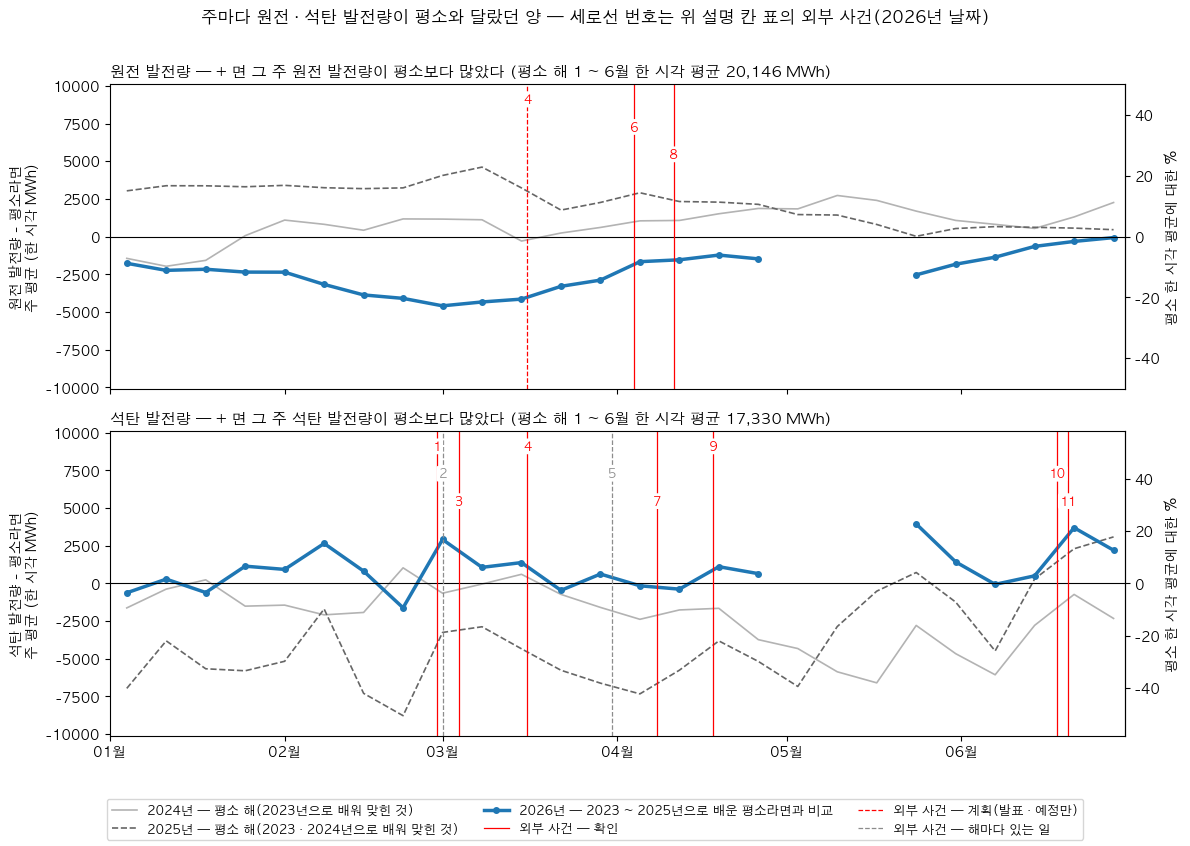

In [161]:
# 9단계 모델 적용 · 4-가
import matplotlib.pyplot as plt                                                       # 그림을 그리는 라이브러리
import matplotlib.dates as mdates                                                     # 가로축에 날짜 눈금을 넣는다
plt.rcParams["font.family"] = "AppleGothic"                                           # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False                                            # 그림의 마이너스 부호가 깨지지 않게
assert "나누기" in globals() and "몫26" in globals(), "물음 2의 2-나를 먼저 돌려 주세요 — 원전 · 석탄으로 나누는 함수와 2026년 값이 거기서 만들어집니다"
y = 전체["lng_mwh"]                                                                    # 맞힐 값(LNG 발전량) — 준비 ②와 같다. 앞 셀에서 같은 이름이 덮어쓰였어도 맞게 돌도록 다시 정한다

# ── 시각마다 원전 · 석탄으로 나눈 값 — 2026년은 2-나가 만든 것, 평소 해는 2-나 [표 2]와 같은 두 번을 시각마다 다시 낸다 ──
나눈값 = {2026: 몫26}                                                                   # 2023 ~ 2025년으로 배워 2026년 1 ~ 6월을 나눈 값(2-나)
for 맞힌해, 배운해 in [(2024, [2023]), (2025, [2023, 2024])]:                          # 2023 → 2024 · 2023 · 2024 → 2025 — 1-사 · 2-나와 같은 두 번
    곳 = 전체["year"] == 맞힌해                                                         # 맞힐 해의 시각
    나눈값[맞힌해], _ = 나누기(전체["year"].isin(배운해), 선형X[곳],                       # 2-나의 함수 그대로 — 시각마다 넷으로 나눈 값을 돌려준다
                            {k: v[곳] for k, v in dict(대상, LNG=y).items()}, 태양광[곳])

# ── 주마다 — 1월 1일부터 7일씩 끊고, 자료가 나흘이 안 되는 주는 비운다 ──
def 주마다(몫, 발전원):
    v = -몫[발전원]                                                                      # 2-나의 값은 + 면 LNG가 늘었다는 쪽 — 부호를 뒤집어 + 면 그 발전원의 발전량이 평소보다 많았다
    v = v[v.index.month <= 6]                                                          # 1 ~ 6월만
    달력 = pd.to_datetime(pd.DataFrame({"year": 2026, "month": v.index.month, "day": v.index.day}))   # 해마다 같은 날짜끼리 놓으려고 2026년 달력으로 옮긴다
    주 = (달력 - pd.Timestamp("2026-01-01")).dt.days // 7                                # 1월 1일부터 7일씩 끊은 주 번호(0 ~ 25)
    g = pd.DataFrame({"값": v.values, "주": 주.values, "날": 달력.values})
    평균 = g.groupby("주")["값"].mean()                                                  # 그 주 시각들의 평균
    평균[g.groupby("주")["날"].nunique() < 4] = np.nan                                   # 자료가 나흘이 안 되는 주는 비운다
    평균 = 평균.reindex(range(26))                                                       # 26주를 다 놓아 빈 주에서 선이 끊기게 한다
    평균.index = pd.Timestamp("2026-01-01") + pd.to_timedelta(평균.index * 7 + 3, unit="D")   # 점은 그 주의 가운데 날에 찍는다
    return 평균

# ── 그림 — 위 칸 원전 · 아래 칸 석탄, 해마다 한 선, 외부 사건은 세로선 ──
from matplotlib.lines import Line2D                                                   # 선 종류를 범례에 보이려고 짧은 선을 만든다
사건 = [("2026-02-28", "1",  "석탄", "확인", False),                                    # 외부 사건 — 위 설명 칸 표와 같은 번호
        ("2026-03-01", "2",  "석탄", "계획", True),                                     # (날짜, 번호, 그을 칸, 확인 정도, 해마다 있는 일인가)
        ("2026-03-04", "3",  "석탄", "확인", False),
        ("2026-03-16", "4",  "석탄", "확인", False),                                    # 석탄 80% 상한 해제 — 석탄 칸
        ("2026-03-16", "4",  "원전", "계획", False),                                    # 같은 발표의 원전 정비 앞당김 — 원전 칸
        ("2026-03-31", "5",  "석탄", "계획", True),
        ("2026-04-04", "6",  "원전", "확인", False),
        ("2026-04-08", "7",  "석탄", "확인", False),
        ("2026-04-11", "8",  "원전", "확인", False),
        ("2026-04-18", "9",  "석탄", "확인", False),
        ("2026-06-18", "10", "석탄", "확인", False),
        ("2026-06-20", "11", "석탄", "확인", False)]
def 사건선(정도, 해마다):                                                                # 확인은 실선 · 계획은 점선, 2026년만의 일은 빨강 · 해마다 있는 일은 회색
    return dict(color="0.55" if 해마다 else "red", ls="--" if 정도 == "계획" else "-", lw=0.9)
선 = [(2024, dict(color="0.7", lw=1.2), "2024년 — 평소 해(2023년으로 배워 맞힌 것)"),
      (2025, dict(color="0.4", lw=1.2, ls="--"), "2025년 — 평소 해(2023 · 2024년으로 배워 맞힌 것)"),
      (2026, dict(color="tab:blue", lw=2.5, marker="o", ms=4), "2026년 — 2023 ~ 2025년으로 배운 평소라면과 비교")]
평소평균 = {k: 대상[k][대상[k].index.month <= 6].mean() for k in ("원전", "석탄")}       # 평소 해(2023 ~ 2025년) 1 ~ 6월에 그 발전원이 한 시각에 낸 평균 — 오른쪽 % 눈금의 기준
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, sharey=True)          # 두 칸의 가로축(날짜)과 세로축(MWh)이 같다 — 한 칸만 크게 보이지 않게
for ax, 발전원 in zip(axes, ["원전", "석탄"]):
    for 해, 선종류, 이름 in 선:
        s = 주마다(나눈값[해], 발전원)
        ax.plot(s.index, s.values, label=이름, **선종류)                                 # 해마다 한 선 — 빈 주에서는 끊긴다
    ax.axhline(0, color="black", lw=0.8)                                                 # 0 — 평소라면과 같다
    이칸 = [e for e in 사건 if e[2] == 발전원]                                            # 인과지도에서 이 발전원으로 이어지는 사건만 이 칸에 긋는다
    for i, (d, 번호, _, 정도, 해마다) in enumerate(이칸):
        ax.axvline(pd.Timestamp(d), **사건선(정도, 해마다))                                # 외부 사건의 날짜
        ax.text(pd.Timestamp(d), [0.97, 0.88, 0.79][i % 3], 번호, color=사건선(정도, 해마다)["color"], fontsize=9,
                ha="center", va="top", transform=ax.get_xaxis_transform(),
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))           # 번호 — 가까운 날짜끼리 겹치지 않게 높이를 셋으로 번갈아
    ax.set_ylabel(f"{발전원} 발전량 - 평소라면\n주 평균 (한 시각 MWh)")                 # 세로축 — 그 주 시각들의 평균
    ax.set_title(f"{발전원} 발전량 — + 면 그 주 {발전원} 발전량이 평소보다 많았다 (평소 해 1 ~ 6월 한 시각 평균 {평소평균[발전원]:,.0f} MWh)", fontsize=11, loc="left")
    m = 평소평균[발전원]
    오른쪽 = ax.secondary_yaxis("right", functions=(lambda v, m=m: v / m * 100, lambda p, m=m: p * m / 100))   # 같은 값을 평소 한 시각 평균에 대한 %로
    오른쪽.set_ylabel("평소 한 시각 평균에 대한 %")
끝 = max(np.nanmax(np.abs(l.get_ydata())) for ax in axes for l in ax.lines[:3]) * 1.15   # 해마다 세 선 가운데 가장 멀리 간 값
axes[0].set_ylim(-끝, 끝)                                                                # 0을 가운데 두고 위아래를 같은 폭으로 — 한쪽만 늘려 그리지 않게
axes[1].set_xlim(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-06-30"))              # 1 ~ 6월
axes[1].xaxis.set_major_locator(mdates.MonthLocator())                                 # 달마다 눈금
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m월"))                        # 01월 · 02월 …
선들, 선이름 = axes[0].get_legend_handles_labels()
선들 += [Line2D([], [], **사건선("확인", False)), Line2D([], [], **사건선("계획", False)), Line2D([], [], **사건선("계획", True))]
선이름 += ["외부 사건 — 확인", "외부 사건 — 계획(발표 · 예정만)", "외부 사건 — 해마다 있는 일"]
fig.legend(선들, 선이름, loc="lower center", ncol=3, fontsize=9)                          # 선 이름은 그림 아래에 — 선을 가리지 않게
fig.suptitle("주마다 원전 · 석탄 발전량이 평소와 달랐던 양 — 세로선 번호는 위 설명 칸 표의 외부 사건(2026년 날짜)", fontsize=12)
plt.tight_layout(rect=[0, 0.08, 1, 0.97])
plt.show()

## 4-나 — 석탄 상한을 푼 3월 16일 뒤에 석탄을 가장 많이 태운 양이 올라갔나 (평소 해의 같은 때와 나란히)

**이 셀이 답하는 물음** — 「튀어오르는 애들에서 원인을 찾아보려는거지?」(창주 님) 가운데 1(석탄 발전량이 평소보다 많았다) — 3월 16일에 석탄 상한을 푼 뒤(위 4-가 표 4번, 확인) 석탄을 가장 많이 태운 양이 평소 해의 같은 때보다 더 올라갔나. 상한이 석탄을 막고 있었다면, 상한을 푼 뒤에는 가장 많이 태운 양이 올라갔어야 합니다(판단).

**표와 그림**

- 날마다 「석탄을 가장 많이 태운 한 시각」의 발전량(MWh)을 냅니다. 상한은 한 시각에 태울 수 있는 양을 막는 것이라, 하루 평균보다 가장 많이 태운 시각에 먼저 드러납니다(판단).
- 3월 16일 앞 14일(3월 2 ~ 15일)과 뒤 14일(3월 16 ~ 29일)의 평균을 해마다 냅니다. 3월 1일(계절관리제 봄철 강화)과 3월 31일(계절관리제 끝)은 해마다 있는 일이라 두 기간에서 뺐습니다. 14일씩이라 두 기간에 같은 요일이 두 번씩 들어갑니다. 3월 2일(2026년)과 3월 3일(2025년)은 대체공휴일이라, 그해 앞 14일에는 쉬는 날이 하루씩 더 있습니다.
- 「뒤 - 앞」이 + 면 뒤 14일에 석탄을 가장 많이 태운 양이 앞 14일보다 많았다는 뜻입니다. 평소 해도 3월 중순 앞뒤로 이만큼은 바뀐다는 것을 보려고 같이 놓습니다.
- 이 셀은 모델을 쓰지 않습니다. 실제 발전량끼리의 비교라 평소라면이 없고, 그래서 평소 해에 2023년도 넣었습니다(2023 · 2024 · 2025년).
- 그림 — 2월 15일 ~ 4월 15일의 날마다 가장 많이 태운 한 시각입니다. 파란 굵은 선이 2026년, 회색 선이 평소 해(2023년 점 · 2024년 실선 · 2025년 점선)이고, 다른 해는 2026년 달력의 같은 날에 겹쳐 그렸습니다. 빨간 세로선이 3월 16일 상한 해제, 회색 점선 세로선이 3월 1일 · 31일 계절관리제(해마다)입니다. 세로축은 0부터 그렸습니다.
- 그림의 같은 날짜도 해마다 요일이 다릅니다(예: 3월 7일 — 2026년 토요일 · 2025년 금요일). 그래서 그림에서 해끼리 날마다 비교하지 않고, 해끼리는 표로 봅니다. 그림은 2026년 선이 3월 16일 바로 뒤에 한꺼번에 올랐는지만 봅니다.
- 모델끼리 비교하는 표가 아닙니다.

[표] 날마다 석탄을 가장 많이 태운 한 시각의 발전량 — 3월 16일 앞뒤 14일의 평균 (MWh)
     모델을 쓰지 않은 실제 발전량끼리의 비교 · 평소 해는 2023 · 2024 · 2025년


,앞 14일 (3월 2 ~ 15일),뒤 14일 (3월 16 ~ 29일),뒤 - 앞 (+ 면 뒤에 더 태웠다),날 수 (앞 · 뒤)
해,,,,
2023년 (평소 해),"18,323","17,563",-759,14 · 14
2024년 (평소 해),"19,717","17,807","-1,910",14 · 14
2025년 (평소 해),"15,455","12,902","-2,553",14 · 14
2026년,"18,690","17,241","-1,449",14 · 14


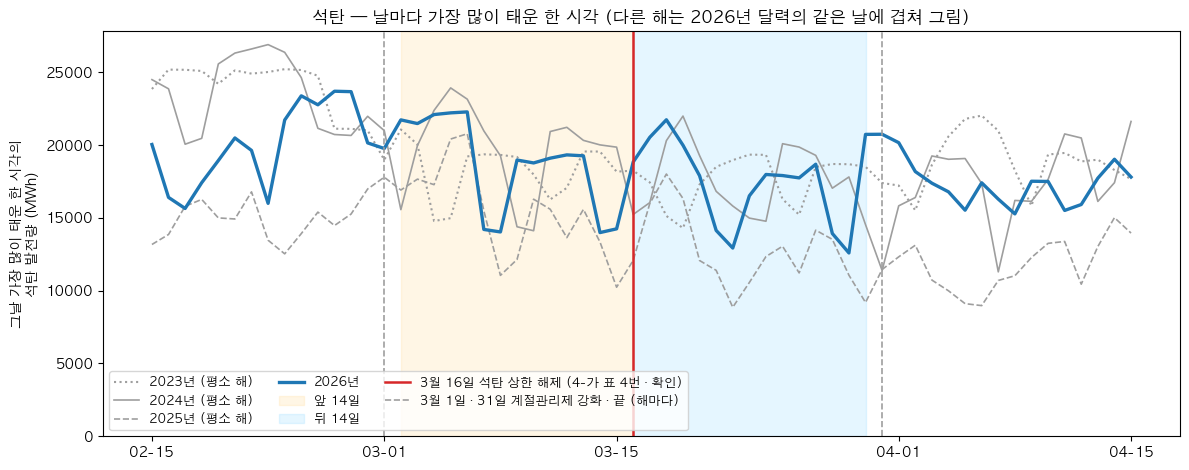

In [162]:
# 9단계 모델 적용 · 4-나
assert "대상" in globals() and "대상26" in globals(), "물음 2의 2-나를 먼저 돌려 주세요 — 석탄 발전량(2023 ~ 2025년 · 2026년)이 거기서 만들어집니다"
import matplotlib.pyplot as plt                                                       # 그림을 그리는 라이브러리
import matplotlib.dates as mdates                                                     # 가로축에 날짜 눈금을 넣는다
plt.rcParams["font.family"] = "AppleGothic"                                           # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False                                            # 그림의 마이너스 부호가 깨지지 않게

# ── 날마다 「석탄을 가장 많이 태운 한 시각」 — 2023 ~ 2025년은 2-나의 대상, 2026년은 대상26 ──
석 = pd.concat([대상["석탄"], 대상26["석탄"]]).sort_index()                          # 시각마다 석탄 발전량(유연탄 + 무연탄, MWh)
하루최대 = 석.groupby(석.index.normalize()).max()                                     # 날마다 가장 많이 태운 한 시각의 발전량

# ── 3월 16일 앞뒤 14일씩 — 3월 1일(계절관리제 봄철 강화)과 3월 31일(계절관리제 끝)은 피한다 ──
줄 = []
for 해 in (2023, 2024, 2025, 2026):
    앞 = 하루최대[f"{해}-03-02":f"{해}-03-15"]                                         # 상한을 풀기 전 14일(다른 해는 같은 날짜)
    뒤 = 하루최대[f"{해}-03-16":f"{해}-03-29"]                                         # 상한을 푼 뒤 14일(다른 해는 같은 날짜)
    줄.append({"해": f"{해}년" if 해 == 2026 else f"{해}년 (평소 해)",
               "앞 14일 (3월 2 ~ 15일)": f"{앞.mean():,.0f}",                           # 그 14일 동안 「가장 많이 태운 한 시각」의 평균
               "뒤 14일 (3월 16 ~ 29일)": f"{뒤.mean():,.0f}",
               "뒤 - 앞 (+ 면 뒤에 더 태웠다)": f"{뒤.mean() - 앞.mean():+,.0f}",
               "날 수 (앞 · 뒤)": f"{len(앞)} · {len(뒤)}"})
표 = pd.DataFrame(줄).set_index("해")
print("[표] 날마다 석탄을 가장 많이 태운 한 시각의 발전량 — 3월 16일 앞뒤 14일의 평균 (MWh)")
print("     모델을 쓰지 않은 실제 발전량끼리의 비교 · 평소 해는 2023 · 2024 · 2025년")
display(표)

# ── 그림 — 2월 15일 ~ 4월 15일, 해마다 한 선(다른 해는 2026년 달력의 같은 날에 겹쳐 그린다) ──
fig, ax = plt.subplots(figsize=(12, 4.8))
옵션 = {2023: dict(color="#9e9e9e", linestyle=":", linewidth=1.5),                    # 평소 해는 회색 — 2023년 점
        2024: dict(color="#9e9e9e", linestyle="-", linewidth=1.2),                    # 2024년 실선
        2025: dict(color="#9e9e9e", linestyle="--", linewidth=1.2),                   # 2025년 점선
        2026: dict(color="#1f77b4", linestyle="-", linewidth=2.4)}                    # 2026년은 파란 굵은 선
for 해, 그리기 in 옵션.items():
    s = 하루최대[f"{해}-02-15":f"{해}-04-15"]
    s = s[~((s.index.month == 2) & (s.index.day == 29))]                              # 2월 29일은 2026년 달력에 없어서 뺀다
    날 = pd.to_datetime(pd.DataFrame({"year": 2026, "month": s.index.month, "day": s.index.day}))   # 2026년 달력의 같은 날로 옮긴다
    ax.plot(날, s.values, label=f"{해}년" + ("" if 해 == 2026 else " (평소 해)"), **그리기)
ax.axvspan(pd.Timestamp("2026-03-02"), pd.Timestamp("2026-03-16"), color="#ffd27f", alpha=0.2, label="앞 14일")
ax.axvspan(pd.Timestamp("2026-03-16"), pd.Timestamp("2026-03-30"), color="#7fd3ff", alpha=0.2, label="뒤 14일")
ax.axvline(pd.Timestamp("2026-03-16"), color="#d62728", linewidth=1.8, label="3월 16일 석탄 상한 해제 (4-가 표 4번 · 확인)")
ax.axvline(pd.Timestamp("2026-03-01"), color="#9e9e9e", linewidth=1.2, linestyle="--", label="3월 1일 · 31일 계절관리제 강화 · 끝 (해마다)")
ax.axvline(pd.Timestamp("2026-03-31"), color="#9e9e9e", linewidth=1.2, linestyle="--")
ax.set_ylim(bottom=0)                                                                 # 0부터 그린다 — 작은 차이가 크게 보이지 않게
ax.set_ylabel("그날 가장 많이 태운 한 시각의\n석탄 발전량 (MWh)")
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15]))                     # 1일 · 15일에 눈금
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set_title("석탄 — 날마다 가장 많이 태운 한 시각 (다른 해는 2026년 달력의 같은 날에 겹쳐 그림)")
ax.legend(loc="lower left", fontsize=9, ncol=3)
plt.tight_layout()
plt.show()

## 4-다 — 원전 발전량은 고리 2호기 · 새울 3호기 날짜 앞뒤로 바뀌었나, 설비용량 열은 멈춘 원전도 세나

**이 셀이 답하는 물음** — 「튀어오르는 애들에서 원인을 찾아보려는거지?」(창주 님) 가운데 2(원전 발전량이 1월부터 평소보다 적었다) — 원전 칸의 사건이 우리 자료(시간별 원전 발전량)를 그 무렵 실제로 바꿨나, 그리고 전력거래소 설비용량 열은 멈춘 원전까지 세나.

**표와 그림**

- [표 1] 설비용량 열 — 전력거래소 연간 파일의 원자력 설비용량(MW)을 원전이 멈춘 날의 하루 앞과 하루 뒤로 놓습니다. 고리 2호기(2023년 4월 8일) · 고리 4호기(2025년 8월 6일) · 한빛 1호기(2025년 12월 22일)입니다. 고리 3호기(2024년 9월 28일)는 2024년 연간 파일에 원자력 줄이 없어서 볼 수 없습니다. 이 열은 하루 안에서는 바뀌지 않습니다.
- [표 2] · [표 3] 날짜 앞뒤 — 4월 4일과 4월 11일의 앞 7일 · 뒤 7일에 원전이 낸 한 시각 평균(MWh)을 해마다 냅니다. 「뒤 - 앞」이 + 면 뒤 7일에 원전 발전량이 많았다는 뜻입니다. 봄에는 해마다 원전 정비가 있어서, 평소 해(2023 · 2024 · 2025년)의 같은 날짜도 같이 놓습니다. 7일씩이라 요일은 고르게 들어갑니다. 모델을 쓰지 않은 실제 발전량끼리의 비교입니다. 고리 2호기는 685MW(전자신문 2025-11-13), 새울 3호기는 1,400MW입니다.
- 그림 — 1 ~ 6월 원전 발전량의 7일 평균선(그날을 가운데 둔 7일)입니다. 7일 평균이라 해끼리 같은 날짜를 나란히 봐도 요일이 섞이지 않습니다. 파란 굵은 선이 2026년, 회색 선이 평소 해(2023년 점 · 2024년 실선 · 2025년 점선)이고, 다른 해는 2026년 달력의 같은 날에 겹쳐 그렸습니다. 빨간 세로선 6 · 8은 확인(실선), 4는 계획(점선)입니다. 2026년 5월 2 ~ 17일은 자료가 없어 선이 끊깁니다. 세로축은 0부터 그렸습니다.
- 모델끼리 비교하는 표가 아닙니다.

[표 1] 전력거래소 연간 파일의 원자력 설비용량 — 원전이 멈춘 날 하루 앞 · 하루 뒤
     2024년 파일에는 원자력 줄이 없어 고리 3호기(2024년 9월 28일)는 볼 수 없다


,멈춘 날,하루 앞 설비용량 (MW),하루 뒤 설비용량 (MW),뒤 - 앞
멈춘 원전,,,,
고리 2호기,2023-04-08,"24,650","24,650",+0
고리 4호기,2025-08-06,"26,050","26,050",+0
한빛 1호기,2025-12-22,"26,050","26,050",+0


[표 2] 4월 4일(고리 2호기 다시 발전) 앞뒤 7일 — 원전 발전량 한 시각 평균 (MWh)


,앞 7일,뒤 7일,뒤 - 앞 (+ 면 뒤에 더 많았다),시각 수 (앞 · 뒤)
해,,,,
2023년 (평소 해),"18,971","18,716",-255,168 · 168
2024년 (평소 해),"19,562","18,962",-600,168 · 168
2025년 (평소 해),"21,795","21,241",-554,168 · 168
2026년,"17,495","18,047",+551,168 · 168


[표 3] 4월 11일쯤(새울 3호기 첫 시동) 앞뒤 7일 — 원전 발전량 한 시각 평균 (MWh)


,앞 7일,뒤 7일,뒤 - 앞 (+ 면 뒤에 더 많았다),시각 수 (앞 · 뒤)
해,,,,
2023년 (평소 해),"18,716","17,905",-812,168 · 168
2024년 (평소 해),"18,962","19,126",+163,168 · 168
2025년 (평소 해),"21,241","20,948",-293,168 · 168
2026년,"18,047","17,893",-153,168 · 168


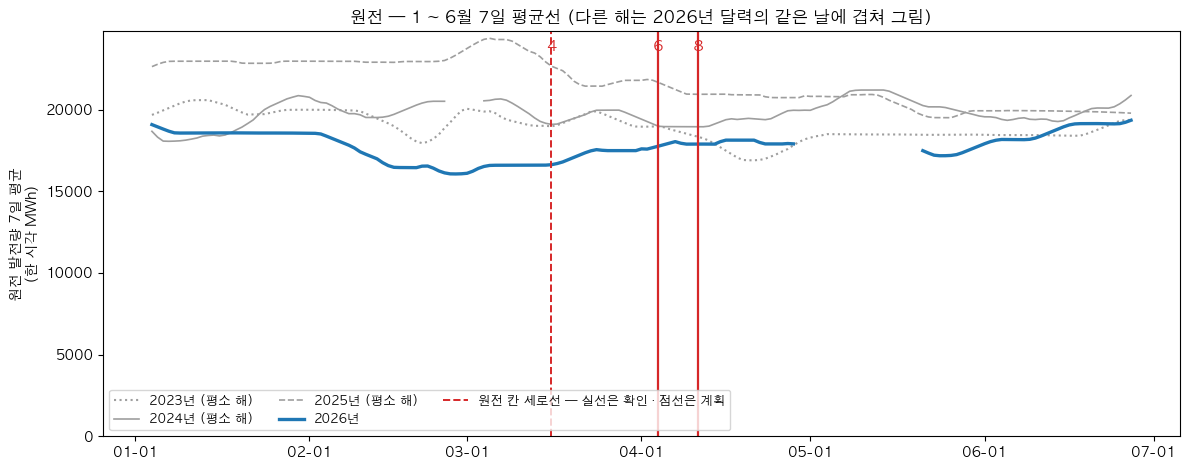

In [163]:
# 9단계 모델 적용 · 4-다
assert "대상" in globals() and "대상26" in globals(), "물음 2의 2-나를 먼저 돌려 주세요 — 원전 발전량(2023 ~ 2025년 · 2026년)이 거기서 만들어집니다"
import matplotlib.pyplot as plt                                                       # 그림을 그리는 라이브러리
import matplotlib.dates as mdates                                                     # 가로축에 날짜 눈금을 넣는다
plt.rcParams["font.family"] = "AppleGothic"                                           # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False                                            # 그림의 마이너스 부호가 깨지지 않게

# ── [표 1] 설비용량 열 — 연간 파일에서 원자력 줄만 남긴다(LNG 줄은 읽자마자 버린다) ──
def 원자력설비(해):
    이름 = [f for f in os.listdir(os.path.join(RAW, "kpx")) if f"{해}1231" in f][0]       # 파일 이름에 20251231 같은 기준일이 있다
    d = pd.read_csv(os.path.join(RAW, "kpx", 이름), encoding="utf-8-sig")
    d.columns = ["date", "hour", "fuel", "cap_mw", "mwh"]                               # 해마다 열 이름이 달라서 순서로 통일한다
    d = d[d["fuel"].str.strip() == "원자력"]                                            # 원자력 줄만 남긴다
    return d.groupby(pd.to_datetime(d["date"]))["cap_mw"].first()                     # 날마다 하나 — 하루 안에서는 바뀌지 않는다
설비 = pd.concat([원자력설비(2023), 원자력설비(2025)])                                 # 2024년 파일에는 원자력 줄이 없다
줄 = []
for 원전, 날 in [("고리 2호기", "2023-04-08"), ("고리 4호기", "2025-08-06"), ("한빛 1호기", "2025-12-22")]:
    날 = pd.Timestamp(날); 앞날, 뒷날 = 날 - pd.Timedelta(days=1), 날 + pd.Timedelta(days=1)
    줄.append({"멈춘 원전": 원전, "멈춘 날": 날.strftime("%Y-%m-%d"),
               "하루 앞 설비용량 (MW)": f"{설비[앞날]:,.0f}", "하루 뒤 설비용량 (MW)": f"{설비[뒷날]:,.0f}",
               "뒤 - 앞": f"{설비[뒷날] - 설비[앞날]:+,.0f}"})
print("[표 1] 전력거래소 연간 파일의 원자력 설비용량 — 원전이 멈춘 날 하루 앞 · 하루 뒤")
print("     2024년 파일에는 원자력 줄이 없어 고리 3호기(2024년 9월 28일)는 볼 수 없다")
display(pd.DataFrame(줄).set_index("멈춘 원전"))

# ── [표 2] · [표 3] 날짜 앞뒤 7일 — 원전 발전량 한 시각 평균(실제 발전량, 모델 없음) ──
원 = pd.concat([대상["원전"], 대상26["원전"]]).sort_index()                          # 시각마다 원전 발전량(MWh) — 2023 ~ 2026년
def 앞뒤(월일):
    표 = []
    for 해 in (2023, 2024, 2025, 2026):
        날 = pd.Timestamp(f"{해}-{월일}")
        앞 = 원[날 - pd.Timedelta(days=7): 날 - pd.Timedelta(hours=1)]                # 그날 앞 7일(168시각)
        뒤 = 원[날: 날 + pd.Timedelta(days=7) - pd.Timedelta(hours=1)]               # 그날부터 7일(168시각)
        표.append({"해": f"{해}년" if 해 == 2026 else f"{해}년 (평소 해)",
                   "앞 7일": f"{앞.mean():,.0f}", "뒤 7일": f"{뒤.mean():,.0f}",
                   "뒤 - 앞 (+ 면 뒤에 더 많았다)": f"{뒤.mean() - 앞.mean():+,.0f}",
                   "시각 수 (앞 · 뒤)": f"{len(앞)} · {len(뒤)}"})
    return pd.DataFrame(표).set_index("해")
print("[표 2] 4월 4일(고리 2호기 다시 발전) 앞뒤 7일 — 원전 발전량 한 시각 평균 (MWh)")
display(앞뒤("04-04"))
print("[표 3] 4월 11일쯤(새울 3호기 첫 시동) 앞뒤 7일 — 원전 발전량 한 시각 평균 (MWh)")
display(앞뒤("04-11"))

# ── 그림 — 1 ~ 6월 원전 발전량의 7일 평균선(그날을 가운데 둔 7일 — 요일이 고르게 들어간다) ──
하루 = 원.groupby(원.index.normalize()).mean()                                        # 날마다 한 시각 평균
fig, ax = plt.subplots(figsize=(12, 4.8))
옵션 = {2023: dict(color="#9e9e9e", linestyle=":", linewidth=1.5),                    # 평소 해는 회색 — 2023년 점
        2024: dict(color="#9e9e9e", linestyle="-", linewidth=1.2),                    # 2024년 실선
        2025: dict(color="#9e9e9e", linestyle="--", linewidth=1.2),                   # 2025년 점선
        2026: dict(color="#1f77b4", linestyle="-", linewidth=2.4)}                    # 2026년은 파란 굵은 선
for 해, 그리기 in 옵션.items():
    s = 하루.reindex(pd.date_range(f"{해}-01-01", f"{해}-06-30", freq="D"))            # 자료가 없는 날은 비워 둔다(2026년 5월 2 ~ 17일)
    s = s.rolling(7, center=True, min_periods=7).mean()                               # 그날을 가운데 둔 7일 평균
    s = s[~((s.index.month == 2) & (s.index.day == 29))]                              # 2월 29일은 2026년 달력에 없어서 뺀다
    날 = pd.to_datetime(pd.DataFrame({"year": 2026, "month": s.index.month, "day": s.index.day}))   # 2026년 달력의 같은 날로 옮긴다
    ax.plot(날, s.values, label=f"{해}년" + ("" if 해 == 2026 else " (평소 해)"), **그리기)
ax.axvline(pd.Timestamp("2026-03-16"), color="#d62728", linewidth=1.4, linestyle="--", label="원전 칸 세로선 — 실선은 확인 · 점선은 계획")
ax.axvline(pd.Timestamp("2026-04-04"), color="#d62728", linewidth=1.6)
ax.axvline(pd.Timestamp("2026-04-11"), color="#d62728", linewidth=1.6)
ax.set_ylim(bottom=0)                                                                 # 0부터 그린다 — 작은 차이가 크게 보이지 않게
위 = ax.get_ylim()[1]
for 날짜, 번호 in (("2026-03-16", "4"), ("2026-04-04", "6"), ("2026-04-11", "8")):     # 번호는 4-가 표와 같다
    ax.text(pd.Timestamp(날짜), 위 * 0.98, 번호, color="#d62728", ha="center", va="top", fontsize=11, fontweight="bold")
ax.set_ylabel("원전 발전량 7일 평균\n(한 시각 MWh)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-01"))
ax.set_title("원전 — 1 ~ 6월 7일 평균선 (다른 해는 2026년 달력의 같은 날에 겹쳐 그림)")
ax.legend(loc="lower left", fontsize=9, ncol=3)
plt.tight_layout()
plt.show()

## 4-라 — LNG가 평소와 달랐던 양을 수요 · 원전 · 석탄 · 그 밖으로 나눠, 주말 · 평일과 6월 낮 · 밤으로 따로 보면 어느 줄이 움직였나

**이 셀이 답하는 물음** — 「튀어오르는 애들에서 원인을 찾아보려는거지?」(창주 님) 가운데 3(6월에 낮 · 밤 모두 LNG가 평소보다 적었다)과 4(주말에 LNG가 평소보다 많았다) — 그 차이가 수요 · 원전 · 석탄 · 그 밖 가운데 어느 줄에서 왔나.

**나누는 방법(2-나와 같다)** — 2-나는 2026년 LNG가 「평소라면」보다 많거나 적었던 양을, 그렇게 된 까닭 네 가지(수요 · 원전 · 석탄 · 그 밖의 발전)로 나눈 표입니다. 예를 들어 2026년 1월에 LNG는 평소라면보다 한 시각에 1,124 MWh 많았고, 이것이 원전 +2,155(원전 발전량이 평소보다 적어서 그만큼 LNG가 늘었다) · 수요 −582(전기를 쓴 양이 평소보다 적어서 그만큼 LNG가 줄었다) · 석탄 −7 · 그 밖 −443으로 나뉩니다(2-나 [표 1], 넷을 더하면 +1,124). 4-라는 이 나누기를 1 ~ 6월 전체가 아니라 주말 시각만 · 평일 시각만, 그리고 6월 낮 시각만 · 밤 시각만 따로 해서 비교합니다.

**표의 숫자**

- 넷으로 나누는 방법은 2-나와 같습니다(선형회귀, 넷을 더하면 맨 위 LNG 줄). + 면 그 줄 때문에 LNG가 늘었다는 뜻입니다 — 2-나와 같은 쪽이라, 원전 · 석탄 · 그 밖은 그 발전량이 평소보다 적으면 + 입니다.
- [표 1] 1 ~ 6월 「주말(토 · 일) − 평일(화~금)」 — 주말 시각의 평균에서 화~금 시각의 평균을 뺀 값입니다(3-마와 같은 나눔 — 토 · 일에 든 공휴일은 토 · 일로 세고, 월요일과 평일 공휴일 · 명절은 넣지 않습니다). + 면 주말에 그 줄 때문에 LNG가 평일보다 더 늘었다는 뜻입니다.
- [표 2] · [표 3] 6월 낮(10 ~ 15시) · 밤(0 ~ 5시) — 3-라와 같은 시각입니다. 2026년 6월은 1 ~ 30일이 다 있습니다.
- 오른쪽 칸은 2026년 값이 평소 해 두 해(2024 · 2025년) 값 사이에 있는지입니다. 평소 해가 둘뿐이라 약한 기준입니다(3-마와 같은 약점).
- 모델끼리 비교하는 표가 아닙니다.

In [164]:
# 9단계 모델 적용 · 4-라
assert "나누기" in globals() and "몫26" in globals(), "물음 2의 2-나를 먼저 돌려 주세요 — 수요 · 원전 · 석탄 · 그 밖으로 나누는 함수가 거기서 만들어집니다"
y = 전체["lng_mwh"]                                                                    # 맞힐 값(LNG 발전량) — 앞 셀에서 같은 이름이 덮어쓰였어도 맞게 돌도록 다시 정한다
# ── 시각마다 넷으로 나눈 값 — 2026년은 2-나, 평소 해 2024 · 2025년은 2-나의 함수로 다시 나눈다(4-가와 같다) ──
몫해 = {2026: 몫26}
for 맞힌해, 배운해 in [(2024, [2023]), (2025, [2023, 2024])]:                          # 2023 → 2024 · 2023 · 2024 → 2025
    곳 = 전체["year"] == 맞힌해
    몫해[맞힌해], _ = 나누기(전체["year"].isin(배운해), 선형X[곳],
                            {k: v[곳] for k, v in dict(대상, LNG=y).items()}, 태양광[곳])
날종류 = {2024: 전체["날 종류"], 2025: 전체["날 종류"], 2026: 입력26["날 종류"]}         # 5단계에서 만든 여섯 가지(토 · 일에 든 공휴일은 토 · 일)
줄이름 = {"LNG (선형회귀)": "LNG — 아래 넷을 더한 값",
          "수요": "수요 — + 면 수요가 평소보다 많아서 LNG가 늘었다",
          "원전": "원전 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다",
          "석탄": "석탄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다",
          "그 밖": "그 밖 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다"}

def 범위판정(v, a, b):                                                                   # 2026년 값이 평소 해 두 해의 범위 안인가
    낮은, 높은 = min(a, b), max(a, b)
    return "범위 안" if 낮은 <= v <= 높은 else ("범위 위" if v > 높은 else "범위 아래")
def 표로(값):                                                                            # 해마다 한 칸 + 오른쪽에 범위 칸
    t = pd.DataFrame({f"{해}년" + (" (평소 해)" if 해 < 2026 else ""): 값[해].map("{:+,.0f}".format) for 해 in (2024, 2025, 2026)})
    t["2026년이 평소 해 두 해의 범위 안인가"] = [범위판정(값[2026][k], 값[2024][k], 값[2025][k]) for k in 값[2026].index]
    return t.rename(index=줄이름)

# ── [표 1] 1 ~ 6월 주말(토 · 일) − 평일(화~금) — 3-마와 같은 나눔 ──
주말차 = {}
for 해 in (2024, 2025, 2026):
    m = 몫해[해][몫해[해].index.month <= 6][list(줄이름)]
    k = 날종류[해].reindex(m.index)
    주말차[해] = m[k.isin(["토", "일"])].mean() - m[k == "화~금"].mean()           # 주말 시각 평균 − 화~금 시각 평균
print("[표 1] 1 ~ 6월 「주말(토 · 일) − 평일(화~금)」 — LNG가 평소와 달랐던 양을 넷으로 나눠서 (한 시각 MWh)")
print("       + 면 주말에 그 줄 때문에 LNG가 평일보다 더 늘었다 · 넷을 더하면 맨 위 줄")
display(표로(주말차))

# ── [표 2] · [표 3] 6월 낮(10 ~ 15시) · 밤(0 ~ 5시) — 3-라와 같은 시각 ──
for 번호, 때, 시각 in [(2, "낮", (10, 15)), (3, "밤", (0, 5))]:
    값 = {}
    for 해 in (2024, 2025, 2026):
        m = 몫해[해][list(줄이름)]
        시 = m.index.hour
        값[해] = m[(m.index.month == 6) & (시 >= 시각[0]) & (시 <= 시각[1])].mean()
    print(f"[표 {번호}] 6월 {때}({시각[0]} ~ {시각[1]}시) — LNG가 평소와 달랐던 양을 넷으로 나눠서 (한 시각 MWh · + 면 그 줄 때문에 LNG가 늘었다)")
    display(표로(값))

[표 1] 1 ~ 6월 「주말(토 · 일) − 평일(화~금)」 — LNG가 평소와 달랐던 양을 넷으로 나눠서 (한 시각 MWh)
       + 면 주말에 그 줄 때문에 LNG가 평일보다 더 늘었다 · 넷을 더하면 맨 위 줄


,2024년 (평소 해),2025년 (평소 해),2026년,2026년이 평소 해 두 해의 범위 안인가
LNG — 아래 넷을 더한 값,-180,-387,+763,범위 위
수요 — + 면 수요가 평소보다 많아서 LNG가 늘었다,+709,-103,-772,범위 아래
원전 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다,-96,+257,+208,범위 안
석탄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다,-753,-662,"+1,492",범위 위
그 밖 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다,-40,+120,-164,범위 아래


[표 2] 6월 낮(10 ~ 15시) — LNG가 평소와 달랐던 양을 넷으로 나눠서 (한 시각 MWh · + 면 그 줄 때문에 LNG가 늘었다)


,2024년 (평소 해),2025년 (평소 해),2026년,2026년이 평소 해 두 해의 범위 안인가
LNG — 아래 넷을 더한 값,"+1,040","-1,824","-2,449",범위 아래
수요 — + 면 수요가 평소보다 많아서 LNG가 늘었다,-219,-901,"-3,849",범위 아래
원전 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다,"-1,143",-575,+673,범위 위
석탄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다,"+3,290","+1,002",-116,범위 아래
그 밖 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다,-888,"-1,350",+843,범위 위


[표 3] 6월 밤(0 ~ 5시) — LNG가 평소와 달랐던 양을 넷으로 나눠서 (한 시각 MWh · + 면 그 줄 때문에 LNG가 늘었다)


,2024년 (평소 해),2025년 (평소 해),2026년,2026년이 평소 해 두 해의 범위 안인가
LNG — 아래 넷을 더한 값,"+1,686",-802,-985,범위 아래
수요 — + 면 수요가 평소보다 많아서 LNG가 늘었다,-47,+380,-364,범위 아래
원전 — + 면 원전 발전량이 평소보다 적어서 LNG가 늘었다,"-1,154",-591,+744,범위 위
석탄 — + 면 석탄 발전량이 평소보다 적어서 LNG가 늘었다,"+3,590",+75,"-1,923",범위 아래
그 밖 — + 면 그 밖 발전량이 평소보다 적어서 LNG가 늘었다,-703,-666,+557,범위 위


## 4-마 — 2026년 1 ~ 3월은 평소 해보다 추웠나 (열병합)

**이 셀이 답하는 물음** — 「이건 기온이랑 봐야하는거 아닌가??」(창주 님, 바로 위 「열병합 확인 (1)」) — 2026년 1 ~ 3월에 LNG가 평소보다 많았던 것에 열병합이 더해졌을 수 있나. 그 전에, 그해 겨울이 평소 해보다 추웠나.

**표의 숫자**

- [표 1] 1 ~ 3월 달마다 서울 평균 기온(°C)입니다. 맨 아래 줄은 2026년이 평소 해 세 해의 값 사이에 있는지입니다.
- [표 2] 달마다 0도 아래였던 시각 수입니다. 많을수록 추웠다는 뜻입니다. 평균이 비슷해도 몹시 추운 때가 몰렸는지를 봅니다.
- 기온은 서울 한 지점 값입니다(모델에 넣은 값과 같습니다). 실제 값끼리의 비교이고, 모델끼리 비교하는 표가 아닙니다.

In [165]:
# 9단계 모델 적용 · 4-마
assert "입력26" in globals(), "맨 위 준비 ① ~ ③을 먼저 돌려 주세요 — 2026년 기온은 준비 ③에서 만들어집니다"
기온 = pd.concat([전체["ta"], 입력26["ta"]]).sort_index()                      # 서울 시각마다 기온(°C) — 2023 ~ 2025년은 준비 ②, 2026년은 준비 ③
평균, 영하 = {}, {}
for 해 in (2023, 2024, 2025, 2026):
    s = 기온[(기온.index.year == 해) & (기온.index.month <= 3)]                   # 그해 1 ~ 3월
    이름 = f"{해}년" + (" (평소 해)" if 해 < 2026 else "")
    평균[이름] = s.groupby(s.index.month).mean()                                # 달마다 평균 기온
    영하[이름] = (s < 0).groupby(s.index.month).sum()                           # 달마다 0도 아래였던 시각 수

def 표로(d, 추운쪽, 꼴):                                                      # 해마다 한 줄 + 맨 아래에 2026년이 평소 해 세 해의 범위 안인가
    t = pd.DataFrame(d).T
    t.columns = [f"{m}월" for m in t.columns]
    평소, v = t.iloc[:3], t.iloc[3]
    판정 = []
    for c in t.columns:
        낮은, 높은 = 평소[c].min(), 평소[c].max()
        if 낮은 <= v[c] <= 높은: 판정.append("범위 안")
        elif (v[c] < 낮은) == (추운쪽 == "낮다"): 판정.append("범위 밖 — 평소 해보다 추웠다")
        else: 판정.append("범위 밖 — 평소 해보다 덜 추웠다")
    t = t.apply(lambda col: col.map(꼴.format)).astype(object)
    t.loc["2026년이 평소 해 세 해의 범위 안인가"] = 판정
    return t

print("[표 1] 1 ~ 3월 달마다 서울 평균 기온 (°C) — 평소 해는 모델이 배운 세 해")
display(표로(평균, "낮다", "{:.1f}"))
print("[표 2] 1 ~ 3월 달마다 0도 아래였던 시각 수 — 많을수록 추웠다")
display(표로(영하, "높다", "{:,.0f}"))

[표 1] 1 ~ 3월 달마다 서울 평균 기온 (°C) — 평소 해는 모델이 배운 세 해


,1월,2월,3월
2023년 (평소 해),-1.5,2.3,9.8
2024년 (평소 해),-0.5,3.8,6.9
2025년 (평소 해),-0.4,-1.2,8.0
2026년,-3.6,2.7,8.1
2026년이 평소 해 세 해의 범위 안인가,범위 밖 — 평소 해보다 추웠다,범위 안,범위 안


[표 2] 1 ~ 3월 달마다 0도 아래였던 시각 수 — 많을수록 추웠다


,1월,2월,3월
2023년 (평소 해),457,214,18
2024년 (평소 해),363,108,61
2025년 (평소 해),393,387,19
2026년,569,206,24
2026년이 평소 해 세 해의 범위 안인가,범위 밖 — 평소 해보다 추웠다,범위 안,범위 안


## 4-바 — 2026년 주말에 석탄이 평소만큼이었던 것은 하루 중 언제였나

**이 셀이 답하는 물음** — 「튀어오르는 애들에서 원인을 찾아보려는거지?」(창주 님) 가운데 4(주말에 LNG가 많았다) — 4-라에서 2026년 석탄은 평일에만 평소보다 많았고 주말에는 거의 평소만큼이었는데, 그것이 하루 내내 그랬는지 어떤 시간대에만 그랬는지. 그리고 주말에 LNG가 많았던 것이 석탄이 적었던 그 시간대의 일인지.

**표의 숫자**

- 4-라와 같은 나눈 값(선형회귀)을 다섯 시간대(밤 0 ~ 5시 · 아침 6 ~ 9시 · 낮 10 ~ 15시 · 저녁 16 ~ 21시 · 늦은 밤 22 ~ 23시)로 나눴습니다.
- 두 표 모두 「+ 면 그 발전량이 평소보다 많았다」입니다. [표 1]은 4-라의 석탄 줄을 뒤집어 「석탄이 평소보다 많았던 양」으로 적었습니다(4-라와 부호가 반대). [표 2]는 LNG 줄(넷을 더한 값) 그대로입니다.
- 2026년은 평일(화~금) · 주말(토 · 일) 값을 따로 놓고, 그 차이(주말 − 평일)를 평소 해 두 해의 「주말 − 평일」과 비교했습니다.
- 모델끼리 비교하는 표가 아닙니다.

**여쭌 것(10-27 채팅)** — 1. [표 1]에서 2026년 주말에 석탄이 평소보다 적었던(−) 시간대는 언제인가. 2. [표 2]와 같이 보면, 주말에 LNG가 평소보다 많았던 것은 석탄이 적었던 그 시간대에만 그랬나, 하루 내내 그랬나.

In [ ]:
# 9단계 모델 적용 · 4-바
assert "몫해" in globals() and "날종류" in globals(), "4-라를 먼저 돌려 주세요 — 해마다 넷으로 나눈 값과 날 종류가 거기서 만들어집니다"
시간대 = [("밤 0 ~ 5시", 0, 5), ("아침 6 ~ 9시", 6, 9), ("낮 10 ~ 15시", 10, 15), ("저녁 16 ~ 21시", 16, 21), ("늦은 밤 22 ~ 23시", 22, 23)]

def 평균(해, 값, 날):                                                           # 그해 1 ~ 6월, 시간대마다 그 날(주말 · 평일)의 평균
    m = 값[해][값[해].index.month <= 6]
    k = 날종류[해].reindex(m.index)
    곳날 = k.isin(["토", "일"]) if 날 == "주말" else (k == "화~금")
    h = m.index.hour
    return pd.Series({이름: m[곳날 & (h >= a) & (h <= b)].mean() for 이름, a, b in 시간대})

def 표로(값):                                                                   # 2026년 평일 · 주말 · 주말 − 평일, 평소 해 두 해의 주말 − 평일, 범위
    주, 평 = 평균(2026, 값, "주말"), 평균(2026, 값, "평일")
    차 = {해: 평균(해, 값, "주말") - 평균(해, 값, "평일") for 해 in (2024, 2025, 2026)}
    t = pd.DataFrame({"2026년 평일(화~금)": 평, "2026년 주말(토 · 일)": 주, "2026년 주말 − 평일": 차[2026],
                      "2024년 주말 − 평일 (평소 해)": 차[2024], "2025년 주말 − 평일 (평소 해)": 차[2025]})
    판정 = ["범위 안" if min(x, y) <= z <= max(x, y) else ("범위 위" if z > max(x, y) else "범위 아래") for x, y, z in zip(차[2024], 차[2025], 차[2026])]
    t = t.apply(lambda c: c.map("{:+,.0f}".format)).astype(object)
    t["2026년 주말 − 평일이 평소 해 두 해의 범위 안인가"] = 판정
    return t

석탄량 = {해: -몫해[해]["석탄"] for 해 in 몫해}                                  # 4-라의 석탄 줄을 뒤집는다 — + 면 석탄 발전량이 평소보다 많았다
LNG량 = {해: 몫해[해]["LNG (선형회귀)"] for 해 in 몫해}                          # LNG 줄은 그대로 — + 면 LNG 발전량이 평소보다 많았다
print("[표 1] 석탄이 평소보다 많았던 양 — 시간대마다 (1 ~ 6월, 한 시각 MWh · + 면 석탄 발전량이 평소보다 많았다)")
display(표로(석탄량))
print("[표 2] LNG가 평소보다 많았던 양 — 시간대마다 (1 ~ 6월, 한 시각 MWh · + 면 LNG 발전량이 평소보다 많았다)")
display(표로(LNG량))